# Necessary Imports

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
sns.set_theme('paper')

# Load Data

In [ ]:
try:
  load_data = pd.read_csv('/content/1. swiggy_data_uncleaned.csv', on_bad_lines = 'skip')

except FileNotFoundError:
   print('No such file in directory. Please upload it first')

else:
  df = load_data.copy()
  pd.set_option('display.max_columns',None)

In [ ]:
df.head(10)

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Type_of_order,Order_Date,Time_ordered,Time_Order_picked,Weatherconditions,Road_traffic_density,Type_of_vehicle,Vehicle_condition,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,Snack,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,motorcycle,2,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,Snack,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,scooter,2,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,motorcycle,0,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,motorcycle,0,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,Snack,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,scooter,1,1,No,Metropolitian,(min) 30
5,0x9bb4,HYDRES09DEL03,22,4.8,17.431668,78.408321,17.461668,78.438321,Buffet,11-03-2022,21:20:00,21:30:00,conditions Cloudy,Jam,motorcycle,0,1,No,Urban,(min) 26
6,0x95b4,RANCHIRES15DEL01,33,4.7,23.369746,85.339820,23.479746,85.449820,Meal,04-03-2022,19:15:00,19:30:00,conditions Fog,Jam,scooter,1,1,No,Metropolitian,(min) 40
7,0x9eb2,MYSRES15DEL02,35,4.6,12.352058,76.606650,12.482058,76.736650,Meal,14-03-2022,17:25:00,17:30:00,conditions Cloudy,Medium,motorcycle,2,1,No,Metropolitian,(min) 32
8,0x1102,HYDRES05DEL02,22,4.8,17.433809,78.386744,17.563809,78.516744,Buffet,20-03-2022,20:55:00,21:05:00,conditions Stormy,Jam,motorcycle,0,1,No,Metropolitian,(min) 34
9,0xcdcd,DEHRES17DEL01,36,4.2,30.327968,78.046106,30.397968,78.116106,Snack,12-02-2022,21:55:00,22:10:00,conditions Fog,Jam,motorcycle,2,3,No,Metropolitian,(min) 46


# 1.Data Assessing

## Key Observations just by looking at data in Excel

1. **Incorrect Representation of Missing Values**
   - Several features `Delivery_person_Age`, `Delivery_person_Ratings`, `Time_Ordered`, `Weatherconditions`, `Road_traffic_density`, `multiple_deliveries`, `Festival`, and `City` contain missing values that are incorrectly represented as the string `"NaN"` instead of the standard `np.nan`.
  
   - This inconsistency may prevent proper handling of missing values during preprocessing.
  
   - These string-based `"NaN"` values must be explicitly converted to `np.nan` before applying any imputation technique or training machine learning models.

---
2. **Invalid Restaurant Coordinates (0, 0)**
   - Some observations has **`Restaurant_latitude` = 0** and **`Restaurant_longitude`** = 0

   - The **coordinates (0,0)** commonly referred to as **Null Island**, located in the **Atlantic Ocean near the Gulf of Guinea (near western coast of Africa)**

   - The Gulf of Guinea borders numerous West African nations, including Nigeria, Ghana, Ivory Coast, Benin, Equatorial Guinea, Gabon etc.  

   - **These coordinates do not correspond to any landmass in India with an active food delivery operations** and therefore cannot represent valid restaurant locations of India.
   
   - These values lack realistic geographic precision for Swiggy food delivery platform. **These records clearly indicate missing or corrupted geolocation data.**

---
3. **Suspicious Delivery Location Coordinates with Low Precision**
   - Some observations contain `Delivery_location_latitude` and `Delivery_location_longitude` values such as **0.01, 0.02, 0.03,0.04....,0.09, 0.11, 0.13**, where **latitude and longitude are equal.**

   - Any coordinate where latitude ≈ 0.xx and longitude ≈ 0.xx lies very close to the Equator (0° latitude) and the Prime Meridian (0° longitude).
  
   - Specifically: **(0.11, 0.11)** is located in the **Atlantic Ocean**, off the western coast of Africa & **(0.01-0.07, 0.01-0.07)** all fall within the **Atlantic Ocean near the Gulf of Guinea**, close to the point commonly referred to as **Null Island.**

   - **These coordinates do not correspond to any landmass in India with an active food delivery operations** and therefore cannot represent valid restaurant locations.
   
   - These values lack realistic geographic precision for Swiggy food delivery platform. **These records clearly indicate missing or corrupted geolocation data.**
   
   - The repeated occurrence of such values suggests rounding errors, or improperly recorded geolocation data, rather than real delivery addresses.

- The Presence of **string-based NaNs**, **invalid geospatial coordinates** highlights **data quality issues in the datset.**

---
4. **Embedded City Information in `Delivery_person_ID`**
   - The `Delivery_person_ID` column appears to encode city-level information within the ID itself.
   
   - Examples observed:
     - INDORES13DEL02: Indore
     - BANGRES18DEL02: Bangalore
     - COIMBRES13DEL02: Coimbatore
     - CHENRES12DEL01: Chennai
     - HYDRES09DEL03: Hyderabad
     - RANCHIRES15DEL01: Ranchi
     - MYSRES15DEL02: Mysore
  
   - This indicates that the city information could potentially be extracted as a separate feature

In [ ]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Type_of_order,Order_Date,Time_ordered,Time_Order_picked,Weatherconditions,Road_traffic_density,Type_of_vehicle,Vehicle_condition,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,Snack,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,motorcycle,2,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,Snack,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,scooter,2,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,motorcycle,0,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,motorcycle,0,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,Snack,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,scooter,1,1,No,Metropolitian,(min) 30


In [ ]:
# Correct range
mask1 = df['Restaurant_latitude'].between(6.7467,37.1)
mask2 = df['Restaurant_longitude'].between(68.1167,97.4167)
mask3 = df['Delivery_location_latitude'].between(6.7467,37.1)
mask4 = df['Delivery_location_longitude'].between(68.1167,97.4167)

geospatial_columns = ['Restaurant_latitude',	'Restaurant_longitude',	'Delivery_location_latitude',	'Delivery_location_longitude']

geospatial_errors_df = df.loc[~(mask1 & mask2 & mask3 & mask4),geospatial_columns]

print(f'Number of rows that have geospatial errors: {geospatial_errors_df.shape[0]}')

display(geospatial_errors_df)

Number of rows that have geospatial errors: 4071


,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
33,0.000000,0.000000,0.110000,0.110000
52,0.000000,0.000000,0.030000,0.030000
57,0.000000,0.000000,0.080000,0.080000
59,0.000000,0.000000,0.060000,0.060000
67,0.000000,0.000000,0.020000,0.020000
68,0.000000,0.000000,0.040000,0.040000
72,0.000000,0.000000,0.080000,0.080000
73,0.000000,0.000000,0.020000,0.020000
76,0.000000,0.000000,0.050000,0.050000
81,0.000000,0.000000,0.110000,0.110000


In [ ]:
fig = px.scatter_mapbox(geospatial_errors_df, lat = 'Delivery_location_latitude', lon = 'Delivery_location_longitude', zoom = 4, width = 1000, height = 400)

fig.update_layout(
    mapbox_style = 'open-street-map',
    margin = {'r':0,'t':0,'l':0,'b':0}
)

fig.show()

In [ ]:
# Original data shape

load_data.shape

(45593, 20)

In [ ]:
# Originial shape of data

rows,cols = df.shape

print(f'The dataset has {rows} rows and {cols} columns')

The dataset has 45593 rows and 20 columns


In [ ]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Type_of_order', 'Order_Date',
       'Time_ordered', 'Time_Order_picked', 'Weatherconditions',
       'Road_traffic_density', 'Type_of_vehicle', 'Vehicle_condition',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)'],
      dtype='object')

In [ ]:
df.columns.str.strip().str.lower()

Index(['id', 'delivery_person_id', 'delivery_person_age',
       'delivery_person_ratings', 'restaurant_latitude',
       'restaurant_longitude', 'delivery_location_latitude',
       'delivery_location_longitude', 'type_of_order', 'order_date',
       'time_ordered', 'time_order_picked', 'weatherconditions',
       'road_traffic_density', 'type_of_vehicle', 'vehicle_condition',
       'multiple_deliveries', 'festival', 'city', 'time_taken(min)'],
      dtype='object')

In [ ]:
def change_column_names(df:pd.DataFrame):

    # Renaming columns to readable and ML-friendly names
    # 1. Ensures consistent naming convention (snake_case)
    # 2. Removing leading and trailing whitespaces from all features name
    # 3. Improves reliability of comparisons

    df.columns = df.columns.str.strip().str.lower()

    rename_dict =  {
                    'delivery_person_id' : 'rider_id',
                    'delivery_person_age': 'rider_age',
                    'delivery_person_ratings': 'rider_ratings',
                    'delivery_location_latitude':  'delivery_latitude',
                    'delivery_location_longitude': 'delivery_longitude',
                    'type_of_order' : 'order_type',
                    'time_ordered': 'order_time',
                    'time_order_picked': 'order_picked_time',
                    'weatherconditions': 'weather',
                    'road_traffic_density': 'traffic',
                    'type_of_vehicle' : 'vehicle_type',
                    'city': 'city_type',
                    'time_taken(min)': 'time_taken'
                    }

    return df.rename(columns = rename_dict)

In [ ]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Type_of_order,Order_Date,Time_ordered,Time_Order_picked,Weatherconditions,Road_traffic_density,Type_of_vehicle,Vehicle_condition,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,Snack,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,motorcycle,2,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,Snack,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,scooter,2,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,motorcycle,0,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,motorcycle,0,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,Snack,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,scooter,1,1,No,Metropolitian,(min) 30


In [ ]:
df = change_column_names(df)

df.head()

,id,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,festival,city_type,time_taken
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,Snack,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,motorcycle,2,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,Snack,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,scooter,2,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,motorcycle,0,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,motorcycle,0,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,Snack,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,scooter,1,1,No,Metropolitian,(min) 30


In [ ]:
f_dtypes = df.dtypes.reset_index()
f_dtypes.columns = ['feature','data_type']
f_dtypes

,feature,data_type
0,id,object
1,rider_id,object
2,rider_age,object
3,rider_ratings,object
4,restaurant_latitude,float64
5,restaurant_longitude,float64
6,delivery_latitude,float64
7,delivery_longitude,float64
8,order_type,object
9,order_date,object


Corrections to be made:
1. `rider_age` column should be in `integer` format
2. `rider_ratings` column should be in `float` format
3. Date & time columns (ex: `order_date`, `order_time`, `order_picked_time`) should be in `Datetime` format
4. `time_taken` column column should be in `integer` format
5. `multiple_deliveries` column column should be in `integer` format

## Identifying Missing Values in data

In [ ]:
def get_missing_info(df:pd.DataFrame):

   d1 = df.dtypes.reset_index() # datatypes
   d2 = df.isnull().sum().reset_index() # missing value count

   missing_info = d1.merge(d2, how = 'inner', on = 'index')
   missing_info.columns = ['feature', 'data_type', 'missing_count']
   missing_info['missing_%'] = round((missing_info['missing_count']/len(df))*100,2)

   return missing_info

In [ ]:
get_missing_info(df)

,feature,data_type,missing_count,missing_%
0,id,object,0,0.0
1,rider_id,object,0,0.0
2,rider_age,object,0,0.0
3,rider_ratings,object,0,0.0
4,restaurant_latitude,float64,0,0.0
5,restaurant_longitude,float64,0,0.0
6,delivery_latitude,float64,0,0.0
7,delivery_longitude,float64,0,0.0
8,order_type,object,0,0.0
9,order_date,object,0,0.0


In [ ]:
df.isnull().sum().sum() # 0: signifies no missing values

np.int64(0)

### M-1

In [ ]:
# ------------------------------------------------------------------------------------------------------------------------------------------------
# GOAL:
# Detect missing values that are incorrectly stored as STRINGS such as: 'NaN','nan','Nan','NAN' etc, instead of real np.nan
# So here we manually scan the dataset to detect such cases.
# Q. Why this matters:
# 1. Pandas only treats actual np.nan as missing.
# 2. If a dataset contains string-based representations like 'NaN','nan','Nan','NAN' etc, Pandas will not recognize them as missing values.
# 3. This can silently break:
#    - df.isnull()
#    - Missing Value Imputation
#    - Model Training & Results
#    - Statistical Summaries
# ------------------------------------------------------------------------------------------------------------------------------------------------

# A set to collect UNIQUE string-based null representations
# Helps us inspect all different formats used in dataset, Since No duplicates are allowed
set_null_different_types = set()

# Counter to track total occurrences of string-based nulls
null_values_count = 0

# Since in our data, null values are represented using strings
# So these null strings have to be present in that columns where datatype is object
object_df = df.select_dtypes(include = 'object')

# Iterate through each column
for col in object_df.columns.tolist():

    # We iterate through all values in a particular column
    # To count total occurrences of string-based nulls in that particular column
    for value in object_df[col]:

        # strip() & lower() : Makes comparison becomes Case-Insensitive means
        # 'NaN', 'NaN ', ' NaN ', 'nan', 'nan ', ' nan', 'Nan', 'NAN' ----> All were treated same as 'nan'
        # 'Null', 'null', ' Null ', 'null ' ---> All were treated same as 'null' and so on
        v = value.strip().lower()

        condition1 = v in ['nan', 'null', 'none'] # Detect only exact null-like string matches only e.g., 'nan', 'null', 'none'
        condition2 = v.startswith('nan')          # Assumption 1: If a value starts with 'nan', it is likely corrupted null data
        condition3 = v.endswith('nan')            # Assumption 2: If a value ends with   'nan', it is likely corrupted null data

        if condition1 or condition2 or condition3:

           null_values_count += 1 # Increase total count of detected string-null values

           # Store UNIQUE original raw values
           # Important: We store original values (Not stripped & lowercase version)
           # So we can inspect exactly how they appeared in dataset
           set_null_different_types.add(value) # Here Why we don't use update() instead of add() is later explained in M-2


# Print summary of findings
print(f'Detected string-based null representations: {set_null_different_types}', end = '\n\n')
print(f'Total {null_values_count} null values are encoded as strings across all columns in the data')

Detected string-based null representations: {'conditions NaN', 'NaN '}

Total 9131 null values are encoded as strings across all columns in the data


### M-2

In [ ]:
set_null_different_types = set()
null_values_count = 0

for col in df.select_dtypes(include = 'object').columns.tolist():

    mask1 = df[col].apply(lambda x: x.strip().lower() in ['nan', 'null', 'none'])
    mask2 = df[col].apply(lambda x: x.strip().lower().startswith('nan'))
    mask3 = df[col].apply(lambda x: x.strip().lower().endswith('nan'))

    # Combine all three masks: Logical OR -> if any condition is True, mark it as null string-null(null value represented using string)
    final_mask = mask1|mask2|mask3

    # Count total null-string occurrences in this column
    null_values_count += final_mask.sum()

    # Extract Data using boolean indexing
    data = df.loc[final_mask,col]

    if len(data) > 0:
       null_string = data.unique()[0]
       print(f'Column name: {col}, Null representation: {null_string}')

       set_null_different_types.add(null_string)
       # add() added-up an entire string object(null_string) at once into the set i.e. set_null_different_types


       # set_null_different_types.update(null_string)
       #
       # Can't use update() here
       # Because update() does not add the whole string object(null_string) as one single object.
       # It takes the each element from string object(null_string) and adds them one by one into the set i.e set_null_different_types

# Print summary of findings
print(f'\nDetected string-based null representations: {set_null_different_types}', end = '\n\n')
print(f'Total {null_values_count} null values are encoded as strings across all columns in the data')

Column name: rider_age, Null representation: NaN 
Column name: rider_ratings, Null representation: NaN 
Column name: order_time, Null representation: NaN 
Column name: weather, Null representation: conditions NaN
Column name: traffic, Null representation: NaN 
Column name: multiple_deliveries, Null representation: NaN 
Column name: festival, Null representation: NaN 
Column name: city_type, Null representation: NaN 

Detected string-based null representations: {'conditions NaN', 'NaN '}

Total 9131 null values are encoded as strings across all columns in the data


In [ ]:
print(f'Total missing values(np.nan) in dataset BEFORE cleaning: {df.isnull().sum().sum()}')

# Convert detected null strings into proper missing values
df.replace(to_replace = set_null_different_types, value = np.nan, inplace = True)

print(f'Total missing values(np.nan) in dataset AFTER cleaning: {df.isnull().sum().sum()}')

Total missing values(np.nan) in dataset BEFORE cleaning: 0
Total missing values(np.nan) in dataset AFTER cleaning: 9131


## Missing Value Analysis
- Not an in-depth analysis
- It is just to get some idea about missingness present in our data
- Furthur in-depth analysis, we'll see later after an in-depth EDA section

In [ ]:
d1 = df.copy()

In [ ]:
row, cols = d1.shape
missing_cells = d1.isnull().sum().sum()
missing_atleast_rows = d1.isnull().any(axis = 1).sum()
missing_all_rows = d1.isnull().all(axis = 1).sum()
rows_duplicated = d1.duplicated().sum()

print(f'There are {row} rows and {cols} columns in the dataset')
print(f'There are {missing_cells} missing cells out of {df.size} total cells, which signifies that {round((missing_cells/df.size)*100,2)}% of data is missing')
print(f'There are {missing_atleast_rows} rows containing at least one missing value, which accounts for {round((missing_atleast_rows/row)*100,2)}% of total rows')
print(f'There are {missing_all_rows} rows containing all missing values, which accounts for {round((missing_all_rows/row)*100,2)}% of total rows')
print(f'There are {rows_duplicated} duplicated rows')

There are 45593 rows and 20 columns in the dataset
There are 9131 missing cells out of 911860 total cells, which signifies that 1.0% of data is missing
There are 4225 rows containing at least one missing value, which accounts for 9.27% of total rows
There are 0 rows containing all missing values, which accounts for 0.0% of total rows
There are 0 duplicated rows


In [ ]:
get_missing_info(df)

,feature,data_type,missing_count,missing_%
0,id,object,0,0.00
1,rider_id,object,0,0.00
2,rider_age,object,1854,4.07
3,rider_ratings,object,1908,4.18
4,restaurant_latitude,float64,0,0.00
5,restaurant_longitude,float64,0,0.00
6,delivery_latitude,float64,0,0.00
7,delivery_longitude,float64,0,0.00
8,order_type,object,0,0.00
9,order_date,object,0,0.00


In [ ]:
import missingno as msno

### a. Bar Chart

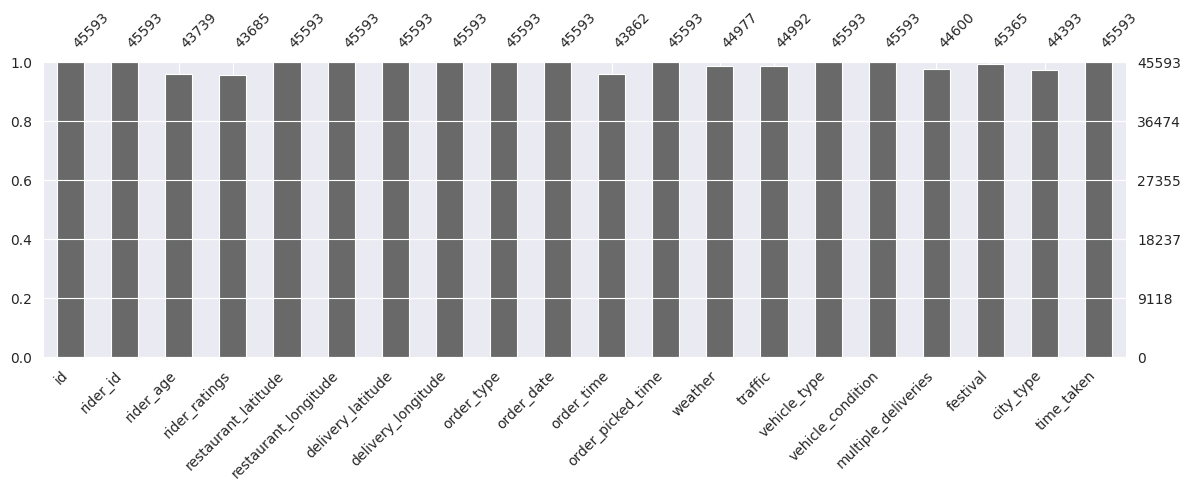

In [ ]:
fig,ax = plt.subplots(nrows = 1, ncols = 1, figsize = (12,5))
msno.bar(df, ax = ax, fontsize = 10)
plt.tight_layout()
plt.show()

1. This is a completeness / non-missing values bar chart
2. Each bar represents a feature
3. **Y-axis (0 - 1 scale) : proportion of non-null values**
4. **Numbers above bars : count of non-null values**
5. Total rows = 45,593

Observations:

---
**1. Overall Data Quality**
- Most bars are almost touching 1.0
- Dataset is highly complete.
- There are no columns with major missing values (>5-10%).

---
**2. Columns With Slight Missing Data (Visually Lower Bars)**
- `rider_age`
- `rider_ratings`
- `order_time`
- `weather`
- `traffic`
- `multiple_deliveries`
- `festival`
- `city_type`

---
**3. Fully Complete Columns (Bars at 1.0)**
- `id`
- `rider_id`
- `restaurant_latitude`
- `restaurant_longitude`
- `delivery_latitude`
- `delivery_longitude`
- `order_type`
- `order_date`
- `order_picked_time`
- `vehicle_type`
- `vehicle_condition`
- `time_taken`

### b. Nullity Correlation Heatmap

## 📊 Missingness Correlation — Complete Guide

---
## 🔴 Correlation = -1 (Perfect Negative Correlation)

### Meaning
- The two variables have perfectly opposite missing patterns.
- When value in one column is present, the value in other column is always missing.
- They never contain values at the same time.
- **The missingness of one feature is negatively linearly correlated with the missingness of another feature.**

### Example
| A     | B     |
|-------|-------|
| value | NaN   |
| NaN   | value |
| value | NaN   |
| NaN   | value |
| value | NaN   |
| NaN   | value |
| value | NaN   |
| NaN   | value |

- If A is observed → B is missing  
- If B is observed → A is missing  
- This produces **exactly -1**.

## 🔴 Correlation Near -1
- Very strong inverse missing pattern.
- The two variables are almost always opposite in their missingness.
- A few exceptions may exist, but the pattern is strongly inverse.

---
## ⚪ Correlation = 0 (Perfect Independence)

### Meaning
- Missingness in one column is completely independent of the other.
- Knowing whether value in column A is missing tells you nothing about whether value in column B is missing.
- There is **no linear relationship between their missingness indicators.**
- The missingness of one feature is not linearly correlated with the missingness of another feature.

### Example
| A     | B     |
|-------|-------|
| value | value |
| value | value |
| NaN   | value |
| NaN   | value |
| NaN   | NaN   |
| NaN   | NaN   |
| value | NaN   |
| value | NaN   |
| value | value |
| value | value |

- There is no consistent pattern.
- Missingness occurs randomly relative to each other.
- This produces **exactly 0** (rare in real datasets).

---
## ⚪ Correlation Near 0
- No meaningful relationship in missingness.
- Any association is likely due to random variation.
- **Suggests independence between the pair (though not proof of global MCAR).**
- Correlation ≈ 0 indicates:
  - **Absence of linear pairwise co-missing structure**
  - But that does not establish statistical independence or MCAR, **because missingness relationships can be non-linear or conditional.**

---
## 📈 Correlation = +1 (Perfect Positive Correlation)

### Meaning
- The two variables have identical missing patterns.
- When one value in Column A is missing, the other value in Column B is always missing.
- When one value in Column A is present, the other value in Column B is always present.
- The **missingness of one feature is positively linearly correlated with the missingness of another feature.**

### Example
| A     | B     |
|-------|-------|
| value | value |
| NaN   | NaN   |
| value | value |
| NaN   | NaN   |
| NaN   | NaN   |
| NaN   | NaN   |
| value | value |
| value | value |

- They are missing & present together 100% of the time.
- The variables always appear or disappear together.
- This produces **exactly +1**.

---
## 📈 Correlation Near +1
- Very strong co-missing behavior.
- The variables almost always appear or disappear together.
- Minor inconsistencies may exist, but the pattern is strongly aligned.

---
## 🧠 Important Conceptual Note
This Nullity correlation:
- ❌ Is **NOT** correlation between actual values.
- ✅ Is correlation between **missingness indicators** (1 = missing, 0 = present).
- **Therefore, it describes the structure of missing data — not the relationship between feature values.**

---
## **⚠️ Near-Perfect Correlations**
- `< 1` means the correlation is very close to +1, but not exactly +1
- `>-1` means the correlation is very close to -1, but not exactly -1

---
## 🎯 Interpretation Summary

| Correlation | Meaning | Interpretation |
|-------------|----------|---------------|
| -1      | Perfect inverse missingness | One present → other always missing |
| Near -1 | Strong inverse pattern | One present → other usually missing|
| 0       | Independent missingness | No linear relationship in missingness, but missingness can be non-linear and conditional |
| Near 0  | Weak/no linear relationship | Likely random relative to each other |
| +1      | Perfect co-missing | Always missing & present together |
| Near +1 | Strong co-missing pattern | Usually missing  & present together |

---
Q. What +1 or -1 Actually Tell You
- `+1` → Value in two variables are always missing together.
- `-1` → When value in one variable is missing, the value in other variable is always present.

This tells us:

- ✅ Missingness is not random, it is structured
- ✅ There is a dependency pattern.
- ❌ But it does not tell us why the dependency exists.

Important Reminder:

---
**MCAR Definition**

MCAR (Missing Completely at Random) means:
- The probability of data being missing is the same for all observations
- It does not depened either on the observed data neither it depends on the unobserved(missing) data.
- The missing is completely random and has no relationship with any other data, making MCAR is the simplest case to handle since it introduces least bias.

---
**MAR Definition**

MAR (Missing at Random) means:
- The probability of data being missing is related to the observed data but not to the unobserved data.
- The Missingness can be explained by the **other variables in the dataset for which data is available**.
- Under MAR, Missingness is systematic and can be modelled using the observed data, allowing for more sophisticated imputation methods (KNN, Iterative Imputer) that can reduce bias.

---
**MNAR Definition**

MNAR (Missing Not at Random) means:
- The probability of data being missing is related to the unobserved data itself.
- The missingness depends on the missing data, meaning there's is a reason related to the missing values that explain why they're missing.

---
**Does Missingness Correlation +1 or -1 Imply MAR / MNAR ?**

**Case A: Correlation = +1**
- Value in two variables are always missing together

- Suppose: `order_time` and `order_picked_time` are always missing together. Why could this happen?

***Scenario 1 (Likely MAR)***
- Both are missing when `city_type = Rural`  
-  Missingness can be explained by other feature of the dataset  
- This is MAR.

***Scenario 2 (Likely MNAR)***
- Both are missing because extremely late night deliveries were not recorded  
- Missingness in `order_time` depends on the unobserved values of `order_time`
- Missingness in `order_picked_time` depends on the unobserved values of `order_picked_time`
- There is a **reason** (Both are missing because extremely late night deliveries were not recorded), related to missing values, that explain why they are missing  
- This is MNAR.

Conclusion: **+1 alone does NOT automatically prove MAR / MNAR**

---
**Case B: Correlation = -1**

- When value in one variable is missing, the value in other variable is always present

Suppose:
- When `rider_rating` is present, `feedback_comment` is missing.
- When `feedback_comment` is present, `rider_rating` is missing.

Why?

***Scenario 1 (Likely MAR)***
- If the rating given by user to a rider is high -> No need to fill feedback comment as higher rating signifies that user has smooth or good experience with our service.
- Here missigness in feedback comment can be explained by rider rating observed data.
- If the rating given by user to a rider is low -> Need to fill feedback comment to look out where our services lack and the delivery app automatically did not fill deliveries where the rider get low rating.
- Here missingness in rider rating can be explained by feedback comment observed data.  
- There is a structural missingness caused by app design-based dependency
- The app only allows either rating or it feedback comment.  
- Here Missingness is Likely MAR.

***Scenario 2 (Likely MNAR)***
- Reason: Low ratings are intentionally hidden
- Missingness depends on the rating value itself
- Here missingness in rating column depends on missing data of rating
- There is a reason related to missing values that explain why they are missing  
- Here Missingness is MNAR

Conclusion: **-1 alone does NOT automatically prove MAR / MNAR**

---
**What +1 or -1 Actually Prove**

They prove:
- ✅ The missingness b/w two features is not MCAR (Missing Completely At Random).
- ✅ Missingness is not random
- ✅ Missingness is structured
- ✅ There is a dependency pattern
- ❌ It does not automatically imply MAR.
- ❌ It does not automatically imply MNAR.
- ❌ It cannot distinguish MAR vs MNAR
- ❌ It does not tell us the cause.
- ✅ **The cause must be investigated to determine whether it is MAR or MNAR.**

In [ ]:
mask = df.isnull().sum()
nullity_cols = mask[mask > 0].index.tolist()
print(nullity_cols)

# features where data is missing
# Missingno heatmap only considered these features where data is missing

['rider_age', 'rider_ratings', 'order_time', 'weather', 'traffic', 'multiple_deliveries', 'festival', 'city_type']


In [ ]:
X = df.iloc[:,:-1]

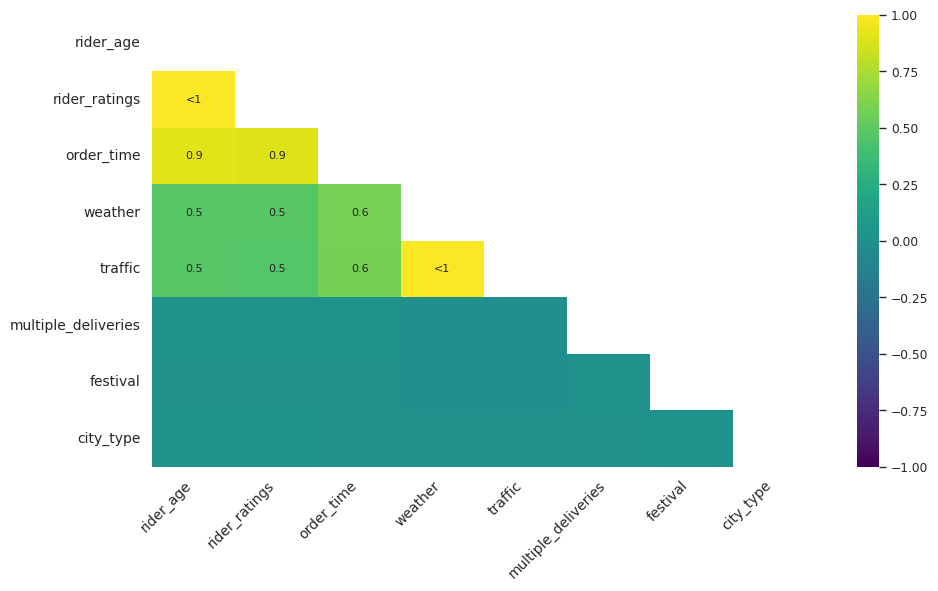

In [ ]:
fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (10, 6))
msno.heatmap(X, ax = ax, fontsize = 10, cmap = 'viridis')
plt.tight_layout()
plt.show()

In [ ]:
x = X['order_time'].isnull().astype(int)
y = X['rider_age'].isnull().astype(int)

np.corrcoef(x,y)[0,1] # this is missingness correlation

np.float64(0.9120276233345102)

In [ ]:
x = X['rider_age'].isnull().astype(int)
y = X['rider_ratings'].isnull().astype(int)

np.corrcoef(x,y)[0,1] # this is missingness correlation

np.float64(0.985138801631695)

In [ ]:
corr_matrix = X[nullity_cols].isnull().astype(int).corr().round(4)
corr_matrix

,rider_age,rider_ratings,order_time,weather,traffic,multiple_deliveries,festival,city_type
rider_age,1.0000,0.9851,0.9120,0.4809,0.4728,0.0142,0.0011,0.0092
rider_ratings,0.9851,1.0000,0.8984,0.4736,0.4656,0.0138,0.0023,0.0087
order_time,0.9120,0.8984,1.0000,0.5891,0.5818,0.0097,0.0006,0.0075
weather,0.4809,0.4736,0.5891,1.0000,0.9876,-0.0018,-0.0002,0.0069
traffic,0.4728,0.4656,0.5818,0.9876,1.0000,-0.0028,-0.0000,0.0062
multiple_deliveries,0.0142,0.0138,0.0097,-0.0018,-0.0028,1.0000,0.0150,0.0074
festival,0.0011,0.0023,0.0006,-0.0002,-0.0000,0.0150,1.0000,0.0233
city_type,0.0092,0.0087,0.0075,0.0069,0.0062,0.0074,0.0233,1.0000


In [ ]:
updated_corr_matrix = np.triu(corr_matrix) # makes matrix elements above diagonal to 0
updated_corr_matrix = np.where(updated_corr_matrix ==1, 0, updated_corr_matrix).T # Since correlation of 1 is caused by same features

corr_df = pd.DataFrame(data = updated_corr_matrix, columns = corr_matrix.columns)
corr_df.set_index(corr_matrix.columns, inplace = True)
corr_df

,rider_age,rider_ratings,order_time,weather,traffic,multiple_deliveries,festival,city_type
rider_age,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0
rider_ratings,0.9851,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0
order_time,0.9120,0.8984,0.0000,0.0000,0.0000,0.0000,0.0000,0.0
weather,0.4809,0.4736,0.5891,0.0000,0.0000,0.0000,0.0000,0.0
traffic,0.4728,0.4656,0.5818,0.9876,0.0000,0.0000,0.0000,0.0
multiple_deliveries,0.0142,0.0138,0.0097,-0.0018,-0.0028,0.0000,0.0000,0.0
festival,0.0011,0.0023,0.0006,-0.0002,-0.0000,0.0150,0.0000,0.0
city_type,0.0092,0.0087,0.0075,0.0069,0.0062,0.0074,0.0233,0.0


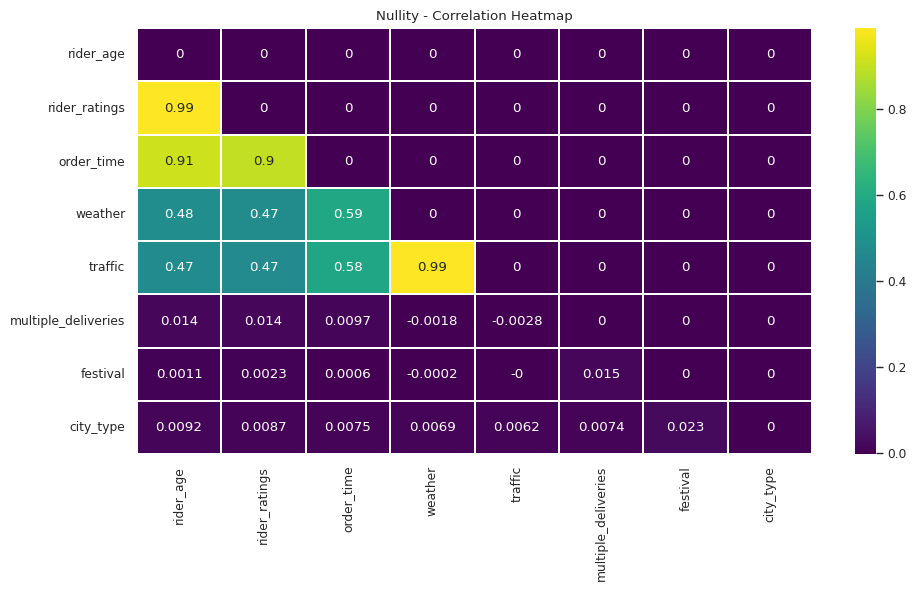

In [ ]:
plt.figure(figsize = (10,6))
sns.heatmap(corr_df, cmap = 'viridis', annot = True, linewidths = 0.01)
plt.title('Nullity - Correlation Heatmap')
plt.tight_layout()
plt.show()

Observations:

1. Strongly Correlated Missingness Blocks

Block 1:
- `rider_age` & `rider_ratings` -> ~1
- `rider_ratings` & `order_time` -> 0.9
- `order_time` & `rider_age` -> 0.9

This suggests:
1. It mean nullity / missingness in delivery person (rider) features like `rider_age` & `rider_ratings` are highly correlated to each other. Here near
~1 signifies that missingness is highly positively correlated which means that when value in one feature is missing the value in other feature is also missing.

2. Missigness in `order_time` column is also related to the `rider_age` &  `rider_ratings` which shows that the data might be missing due to some network error or due to some techincal glitch, where the app system was unable to log in rider details at the time when order is placed.

3. All this suggests if one of these variables is missing, the others are very likely missing as well. All this indicates a strong  missingness pattern. **Here Missingness is structured, not random (MCAR)**

4. Here Missingness can be **likely MNAR:** because missingness depends on the missing data itself meaning there is a reason related to missing values that explain why they are missing. **Though its not a proof, its just an observation of mine.**

5. **The cause must be investigated to determine whether it is MAR or MNAR.**

---
Block 2:
- `weather` & `traffic` -> ~1

This suggests:
1. There is a very positive near-perfect nullity correlation between `weather` & the  `traffic`

2. Be clear that this does not mean that the `weather` & `traffic` features are correlated. To find out if is there is any co-relation between them, we'll see on later.

3. High Positive correlation in missingness means that if values in one feature is missing, there is a high chance that the values are certainly missing in other feature as well.

4. **Here Missingness is structured, not random (MCAR)**

5. **The cause must be investigated to determine whether it is MAR or MNAR.**

---
2. Moderatly Correlated Missingness Blocks
- `order_time` & `weather` -> 0.59
- `order_time` & `traffic` -> 0.58

This suggests:
- This indicates moderate dependency.
- If `order_time` is missing, weather and traffic data are somewhat likely to be missing.
- However, **the missigness correlation is not strong enough.**
- But that **does not establish MCAR, because missingness relationships can be non-linear or conditional.**

---
- `rider_age` & `weather` -> 0.48
- `rider_age` & `traffic` -> 0.47
- `rider_ratings` & `weather` -> 0.47
- `rider_ratings` & `traffic` -> 0.47

This suggest:
- These values suggest some sort of partial dependency between rider related columns and environment related attributes.
- However, **the missigness correlation is not strong enough.**
- But that **does not establish MCAR, because missingness relationships can be non-linear or conditional.**

### c. Dendrogram

- Dendrogram (Hierarchical Clustering of Missingness)
- The `missingno` dendrogram **groups variables based on similarity in their missingness patterns.**
- Variables that merge at lower heights: Have very similar missingness patterns.
- Variables that merge at higher heights: Have more independent missingness behavior.
- In this missingno dendrogram, the numbers **0, 10, 20, 30, 40 on the left side are the distance scale.**
  - They tell you how different the missing-value patterns are between columns.
  - Small value / close to 0: Columns have very similar missing-value behavior.
  - Large value / closer to 40 : Columns have more different missing-value behavior.
  - So this is not row number, not column index, and not percentage of missing values.
  - It is a **hierarchical clustering distance used by `msno.dendrogram()` to group columns based on missingness similarity.**

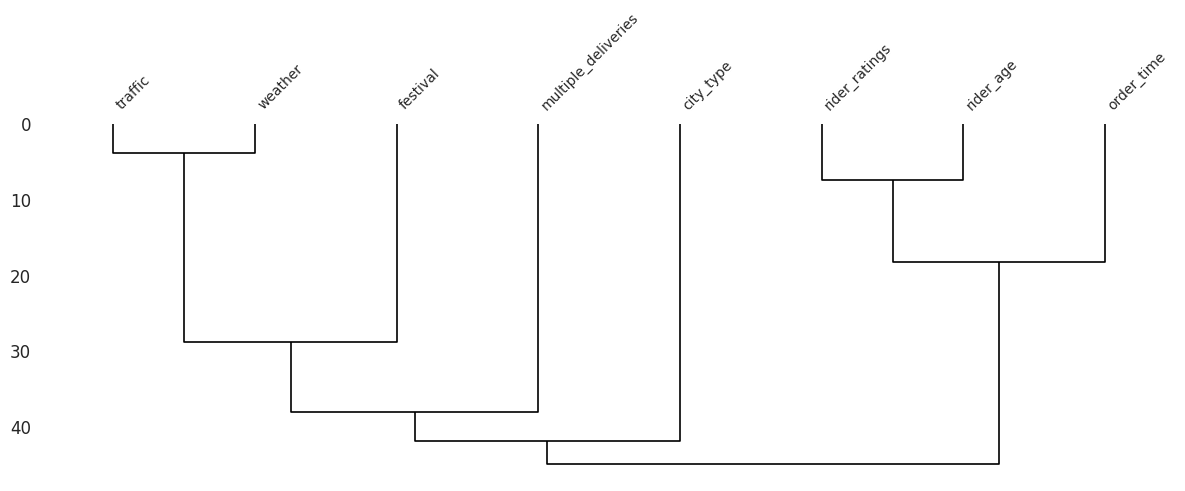

In [ ]:
fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (12, 5))
msno.dendrogram(X[nullity_cols], ax = ax, fontsize = 10)
plt.tight_layout()
plt.show()

Observations:

---
1. Strongly Clustered Variables

   - `rider_age` and `rider_ratings` form a tight cluster. They merge at a very low height.
   - This confirms: Their missingness pattern is almost identical.
   - When one is missing, the other is almost always missing.
   - This aligns with the strong positive nullity correlation observed in the nullity heatmap.
   - `order_time` joins this cluster shortly after.
   - This suggests: **These three variables behave as a structured missingness block.**

---
2. Environmental Cluster

   - `weather` and `traffic` cluster closely together.
   - This confirms: Their missingness patterns are highly similar.
   - If one is missing, the other is very likely missing.
   - This aligns with the strong positive nullity correlation observed in the heatmap.
   - This suggests: **These two variables behave as a structured missingness block.**

---
3. Moderate Cross-Cluster Link
  - The delivery-related cluster (`rider_age`, `rider_ratings`, `order_time`)
connects to the environmental cluster (`weather`, `traffic`) at a higher height.

  - This indicates:
    - There is moderate linkage between these clusters.
    - Some dependency exists between these groups.
    - But they are not perfectly synchronized.
    - This matches the moderate missigness correlations (~0.5-0.6) seen earlier.


---
4. Overall Missingness Structure

The dendrogram reveals two primary missingness clusters:

Cluster 1 (Delivery Information Block):
- `rider_age`
- `rider_ratings`
- `order_time`

Cluster 2 (Environmental Block):
- `weather`
- `traffic`

Other variables show weak or independent missingness behavior.

### d. Matrix Plot

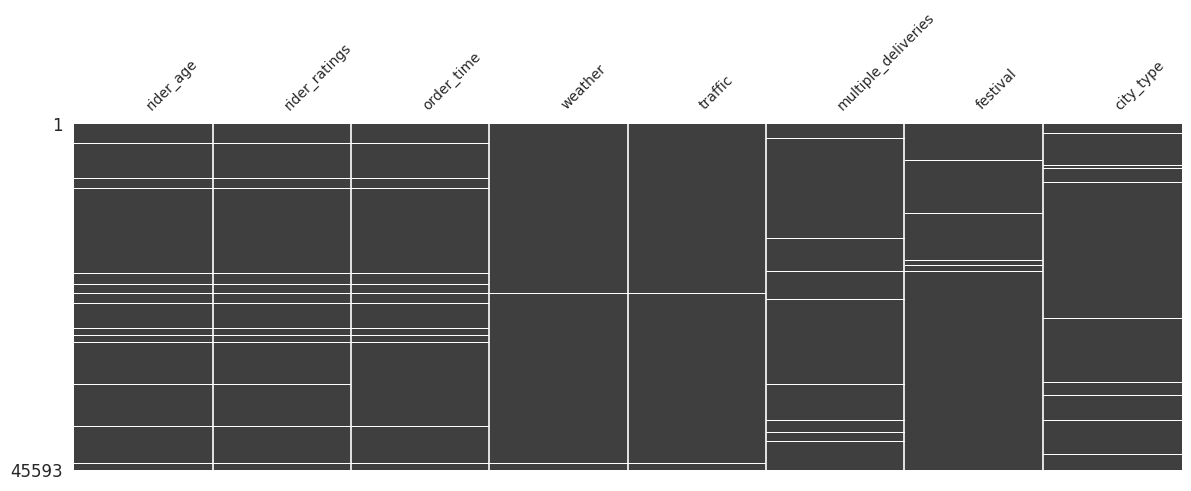

In [ ]:
fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (12,5))
msno.matrix(X[nullity_cols], ax = ax, fontsize = 10)
plt.tight_layout()
plt.show()

### e. Final Interpretation

1. The missingness in this dataset appears systematic and dependent on other features rather than being random.

2. Strong nullity correlations and dendrogram clustering indicate block-wise missingness patterns.

3. This clearly suggests the data is **not MCAR (Missing Completely At Random).**

4. However, while the missingness structure **suggests systematic missingness**, the analysis **does not definitively prove MAR (Missing At Random).**

5. **Further investigation is required to determine whether missingness depends only on observed variables or it depends on unobserved values (MNAR).**

6. Since missingness occurs in structured blocks, **independent Uni-Variate Imputation may disrupt the natural dependency between variables.**

7. **Model-based imputation methods (KNN Imputer, Iterative Imputer) may be more appropriate for this dataset.**

8. However, ultimately, the optimal strategy should be determined through experimentation and model performance evaluation.

# 2.Data Cleaning

In [ ]:
df.head()

,id,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,festival,city_type,time_taken
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,Snack,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,motorcycle,2,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,Snack,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,scooter,2,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,motorcycle,0,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,motorcycle,0,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,Snack,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,scooter,1,1,No,Metropolitian,(min) 30


In [ ]:
# check for duplicated row

df.drop(columns = ['id','rider_id']).duplicated().sum()

# There are no duplicate rows in data

np.int64(0)

In [ ]:
df[object_df.columns] = df[object_df.columns].apply(lambda x: x.str.strip())

# Removing any extra spaces from each value features where data-type is object

## User defined functions for Basic EDA

In [ ]:
def get_index(df:pd.DataFrame, col:str) -> int:

    cols_list = df.columns.tolist()

    return cols_list.index(col)

In [ ]:
def get_categorical_info(df: pd.DataFrame, col_name):

    print(f'Data-Type of "{col_name}" : {df[col_name].dtype}')

    # See all unique values.
    # Useful for spotting inconsistent labels like: 'Male', 'male', ' Male', 'M', etc.
    print(f'Unique values in "{col_name}" : {df[col_name].unique()}')

    # Total number of distinct categories.
    # Helps understand cardinality (important for encoding later).
    print(f'Total unique values in "{col_name}" : {df[col_name].nunique()}')

    # Check missing values.
    null_prop = round((df[col_name].isnull().sum()/len(df))*100,2)
    print(f'% of NaN values in "{col_name}" : {null_prop}\n')

    # Drop missing values for statistical computation
    series = df[col_name]#.dropna()

    # Show frequency of each category (sorted by default).
    # This helps detect:
    # - Imbalanced categories
    # - Rare categories
    # - Dominant class
    counts = series.value_counts()
    cols =   counts.index.to_list()
    prop =   round(series.value_counts(normalize = True)*100,5)

    info_dict = {f'{col_name}': cols, 'count':counts.values, 'proportion': prop.values}
    summary_info = pd.DataFrame(info_dict)
    display(summary_info)

In [ ]:
def get_numerical_info(df: pd.DataFrame, col_name, n_bins):

    # First, just checking what pandas thinks this column is
    # Sometimes numeric columns come as object due to dirty data
    print(f'Data-Type of "{col_name}": {df[col_name].dtype}')

    # Convert everything to numeric safely
    # coerce: forces any non-numeric or unparseable value into a NaN (Not a Number) value.
    feature_series = pd.to_numeric(df[col_name], errors = 'coerce')

    # Calculate count of missing value
    null_count = feature_series.isnull().sum()
    print(f'Total NaN values in "{col_name}" : {null_count}')

    # Calculate % of missing values
    null_prop = round((null_count / len(feature_series))*100,2)
    print(f'% of NaN values in "{col_name}" : {null_prop}%')

    # Basic statistical summary:
    # count, mean, std, min, quartiles, max
    # Rounded for cleaner display.
    display(feature_series.describe().round(2))

    # Clean column name for plotting title.
    # Example: rider_age -> Rider Age
    col_name = ' '.join(col_name.split('_')).title()

    # Creating 2 side-by-side plots:
    # Left -> distribution shape
    # Right -> Boxplot for outlier visibility
    fig, (ax_hist, ax_box) = plt.subplots(nrows = 1, ncols = 2, figsize = (13,4))

    # Histogram + KDE to see distribution pattern.
    # KDE helps smooth the curve.
    sns.histplot(x = feature_series, bins = n_bins, kde = True, color = 'royalblue', ax = ax_hist)
    ax_hist.set_title(f'Distribution of {col_name}', fontsize = 12)

    # Boxplot mainly for spotting outliers and spread.
    sns.boxplot(x = feature_series, color = 'lightgreen', ax = ax_box)
    ax_box.set_title(f'Boxplot of {col_name}', fontsize = 12)

    # Improve spacing so plots don’t overlap.
    plt.tight_layout()
    plt.show()

## Column-Wise Cleaning

### 1.id
- `id` has 45593 unique values
- This column can be dropped from the data

In [ ]:
df['id'].dtype

dtype('O')

In [ ]:
get_categorical_info(df.copy(), 'id')

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
df['id'].nunique() == df.shape[0]

True

In [ ]:
df.drop(columns = ['id'], inplace = True)

1. It has no predictive meaning:
   - `id` are just labels/codes.
   - The model cannot learn real delivery-time behavior from them

2. It can create noise
   - If you encode this column, the model may try to learn fake patterns from random IDs
   For example:
   - id 0x4607 : delivery time 34 minutes
   - id 0xb379 : delivery time 21 minutes
   - But this pattern will not generalize to future orders

3. Very high cardinality
   - It has 45,593 unique values, which is equal to the number of rows
   - This is called high-cardinality categorical data
   - If you apply one-hot encoding, it will create around: 45,593 new columns.That is unnecessary and harmful

4. **Always keep a column only if it helps in explaining the target**

### 2.rider_id

In [ ]:
df['rider_id'].dtype

dtype('O')

In [ ]:
get_categorical_info(df.copy(), 'rider_id')

Data-Type of "rider_id" : object
Unique values in "rider_id" : ['INDORES13DEL02' 'BANGRES18DEL02' 'BANGRES19DEL01' ... 'KOCRES04DEL01'
 'BHPRES06DEL03' 'GOARES03DEL03']
Total unique values in "rider_id" : 1320
% of NaN values in "rider_id" : 0.0



,rider_id,count,proportion
0,PUNERES01DEL01,67,0.14695
1,JAPRES11DEL02,67,0.14695
2,VADRES08DEL02,66,0.14476
3,RANCHIRES02DEL01,66,0.14476
4,HYDRES04DEL02,66,0.14476
5,VADRES11DEL02,66,0.14476
6,JAPRES03DEL01,66,0.14476
7,SURRES11DEL01,65,0.14257
8,JAPRES09DEL02,65,0.14257
9,INDORES15DEL01,65,0.14257


In [ ]:
# extract city name out of rider_id

cities_series = df['rider_id'].str.lower().str.split('res').str.get(0)

df.insert(loc = get_index(df,'festival')+1, column = 'city_name', value = cities_series)

In [ ]:
df['city_name'].unique()

array(['indo', 'bang', 'coimb', 'chen', 'hyd', 'ranchi', 'mys', 'deh',
       'koc', 'pune', 'ludh', 'knp', 'mum', 'kol', 'jap', 'sur', 'goa',
       'aurg', 'agr', 'vad', 'alh', 'bhp'], dtype=object)

In [ ]:
city_mapping = {
    'jap': 'Jaipur',
    'ranchi': 'Ranchi',
    'bang': 'Bangalore',
    'sur': 'Surat',
    'hyd': 'Hyderabad',
    'mum': 'Mumbai',
    'mys': 'Mysore',
    'coimb': 'Coimbatore',
    'vad': 'Vadodara',
    'indo': 'Indore',
    'chen': 'Chennai',
    'pune': 'Pune',
    'agr': 'Agra',
    'ludh': 'Ludhiana',
    'alh': 'Prayagraj', # Formerly Allahabad
    'knp': 'Kanpur',
    'deh': 'Delhi',
    'goa': 'Goa',
    'aurg': 'Aurangabad',
    'koc': 'Kochi',
    'kol': 'Kolkata',
    'bhp': 'Bhopal'
}

In [ ]:
a1 = df['city_name'].value_counts().reset_index()
a2 = df['city_name'].replace(city_mapping).value_counts().reset_index()

pd.concat([a1,a2], axis = 1) # city name cleaning is correct

,city_name,count,city_name,count
0,jap,3443,Jaipur,3443
1,ranchi,3229,Ranchi,3229
2,bang,3195,Bangalore,3195
3,sur,3187,Surat,3187
4,hyd,3181,Hyderabad,3181
5,mum,3173,Mumbai,3173
6,mys,3171,Mysore,3171
7,coimb,3170,Coimbatore,3170
8,vad,3166,Vadodara,3166
9,indo,3159,Indore,3159


In [ ]:
df['city_name'].replace(city_mapping, inplace = True)

In [ ]:
get_categorical_info(df.copy(), 'city_name')

Data-Type of "city_name" : object
Unique values in "city_name" : ['Indore' 'Bangalore' 'Coimbatore' 'Chennai' 'Hyderabad' 'Ranchi' 'Mysore'
 'Delhi' 'Kochi' 'Pune' 'Ludhiana' 'Kanpur' 'Mumbai' 'Kolkata' 'Jaipur'
 'Surat' 'Goa' 'Aurangabad' 'Agra' 'Vadodara' 'Prayagraj' 'Bhopal']
Total unique values in "city_name" : 22
% of NaN values in "city_name" : 0.0



,city_name,count,proportion
0,Jaipur,3443,7.55160
1,Ranchi,3229,7.08223
2,Bangalore,3195,7.00765
3,Surat,3187,6.99011
4,Hyderabad,3181,6.97695
5,Mumbai,3173,6.95940
6,Mysore,3171,6.95502
7,Coimbatore,3170,6.95282
8,Vadodara,3166,6.94405
9,Indore,3159,6.92870


### 3.time_taken
- target

In [ ]:
df['time_taken'].dtype

dtype('O')

In [ ]:
df['time_taken'].head()

,time_taken
0,(min) 24
1,(min) 33
2,(min) 26
3,(min) 21
4,(min) 30


In [ ]:
time_taken = df['time_taken'].str.split().str.get(1)

df['time_taken'] = pd.to_numeric(time_taken, errors = 'coerce')

Data-Type of "time_taken": int64
Total NaN values in "time_taken" : 0
% of NaN values in "time_taken" : 0.0%


,time_taken
count,45593.00
mean,26.29
std,9.38
min,10.00
25%,19.00
50%,26.00
75%,32.00
max,54.00


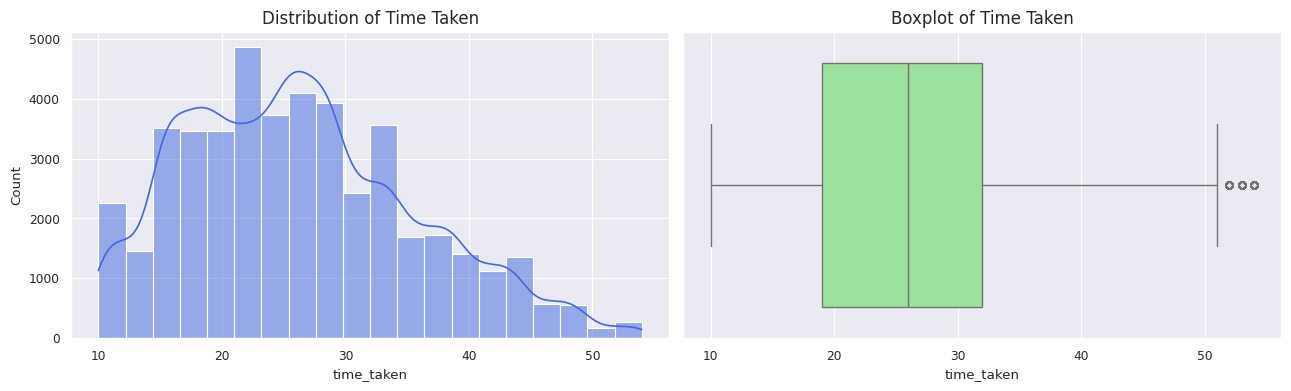

In [ ]:
get_numerical_info(df.copy(), 'time_taken', n_bins = 20)

### 4.rider_age

In [ ]:
df['rider_age'].dtype

dtype('O')

In [ ]:
# Changing data-type
df['rider_age'] = pd.to_numeric(df['rider_age'], errors = 'coerce')

In [ ]:
# datatype
print(df['rider_age'].dtype)

float64


Data-Type of "rider_age": float64
Total NaN values in "rider_age" : 1854
% of NaN values in "rider_age" : 4.07%


,rider_age
count,43739.00
mean,29.57
std,5.82
min,15.00
25%,25.00
50%,30.00
75%,35.00
max,50.00


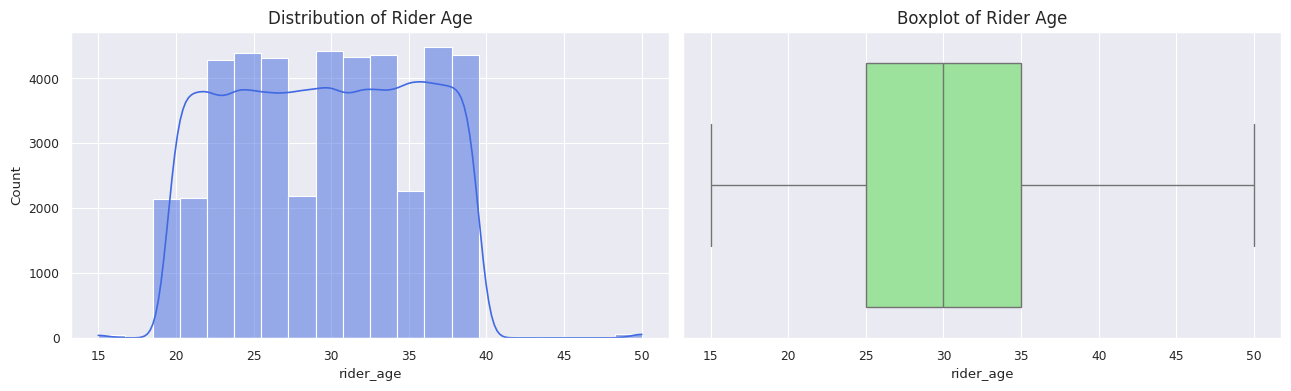

In [ ]:
get_numerical_info(df,'rider_age', n_bins = 20)

- Minimum age of `15` is concerning

In [ ]:
# rows of data where rider age is less than 18

under_age_riders =  df[df['rider_age']<18]
under_age_riders

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,festival,city_name,city_type,time_taken
2387,JAPRES15DEL03,15.0,1,-26.891191,75.802083,26.981191,75.892083,Meal,12-03-2022,NaN,17:20:00,NaN,NaN,motorcycle,3,0,No,Jaipur,Urban,15
2905,INDORES010DEL03,15.0,1,22.750040,75.902847,22.810040,75.962847,Snack,03-04-2022,NaN,20:30:00,NaN,NaN,scooter,3,1,No,Indore,Metropolitian,29
2951,SURRES17DEL03,15.0,1,21.149569,72.772697,21.209569,72.832697,Buffet,21-03-2022,NaN,22:10:00,NaN,NaN,bicycle,3,1,No,Surat,Metropolitian,20
5902,CHENRES15DEL03,15.0,1,13.026286,80.275235,13.056286,80.305235,Drinks,11-03-2022,NaN,20:50:00,NaN,NaN,bicycle,3,1,No,Chennai,Metropolitian,25
9156,BANGRES05DEL01,15.0,1,12.970324,77.645748,13.080324,77.755748,Buffet,25-03-2022,NaN,23:25:00,NaN,NaN,motorcycle,3,2,No,Bangalore,Metropolitian,34
10900,MUMRES14DEL02,15.0,1,19.181300,72.836191,19.231300,72.886191,Buffet,30-03-2022,NaN,20:55:00,NaN,NaN,motorcycle,3,1,No,Mumbai,Metropolitian,39
11125,SURRES12DEL01,15.0,1,-21.183434,-72.814492,21.193434,72.824492,Meal,05-03-2022,NaN,11:30:00,NaN,NaN,scooter,3,1,No,Surat,Urban,27
12093,INDORES03DEL02,15.0,1,22.751857,75.866699,22.801857,75.916699,Buffet,24-03-2022,NaN,21:15:00,NaN,NaN,bicycle,3,0,No,Indore,Metropolitian,28
15124,RANCHIRES02DEL01,15.0,1,0.000000,0.000000,0.070000,0.070000,Meal,16-03-2022,NaN,23:55:00,NaN,NaN,bicycle,3,1,No,Ranchi,Metropolitian,21
15927,CHENRES08DEL02,15.0,1,13.022394,80.242439,13.072394,80.292439,Snack,11-03-2022,NaN,18:10:00,NaN,NaN,bicycle,3,0,No,Chennai,Metropolitian,17


In [ ]:
# Age variaty in under-age riders
print(under_age_riders['rider_age'].unique()[0], end = '\n\n')

# Number of under-age rrivers
print(len(under_age_riders))

# features that have missing values in under-age riders data
mask = under_age_riders.isnull().sum()
mask[mask > 0]

15.0

38


,0
order_time,38
weather,38
traffic,38


In [ ]:
# Observations:
# 1. All under-age riders are of age 15
# 2. rider_ratings = 1 for all observations (weird pattern)
# 3. vehicle condition of all under-age drivers is 3 (weird pattern)
# 4. order_time, weather, traffic has missing value in all the observations
# 5. Corrupted geographical data

In [ ]:
# What type of vehicles these under age drivers were riding

under_age_riders['vehicle_type'].value_counts()

# Since in India for under-age: driving such vehicles excpet bicycle is prohibited

,count
vehicle_type,
scooter,13
electric_scooter,13
bicycle,8
motorcycle,4


**Child and Adolescent Labour (Prohibition and Regulation) Act, 1986**

This Act (amended in 2016) is the main law governing child labour in India.

Key Age Definitions:
| Age                          | Legal Status                                                                             |
| ---------------------------- | ---------------------------------------------------------------------------------------- |
| **Below 14 years**           |  Completely prohibited from working (except helping family after school, non-hazardous) |
| **14-18 years (Adolescent)** |  Allowed to work **only in non-hazardous occupations**                                 |
| **18+ years**                |  No child labour restrictions                                                           |

---
**Q. Is Food Delivery Work Legal at Age 15?**

A 15-year-old is considered an **"Adolescent" (14 - 18 years)** under the law.

**The important question:**

Is food delivery rider considered hazardous?

 Potential Legal Issues:
- Delivery riding involves:
  - Riding motorcycle/scooter in traffic
  - Risk of accidents
  - Long working hours

- Road transport-related work can fall under **hazardous processes/occupations**, especially if it involves commercial driving.

Most delivery platforms (like Zomato or Swiggy) require:

- **Minimum age 18 years**
- Valid driving license
- Legal contract capacity

Since a 15-year-old:
- Cannot legally hold a commercial driving license
- Cannot enter into binding contracts independently

**➡️ In practice, it would be illegal or not permitted.**

---
**Observations:**

From 43,739 riders:

- Minimum rider age = 15
- 38 riders are aged 15
- Vehicles used by under-age riders

| Vehicle Type     | Count |
| ---------------- | ----- |
| scooter          | 13    |
| electric_scooter | 13    |
| bicycle          | 8     |
| motorcycle       | 4     |

Geographic Validation Rules for India

This range covers entire India everything from the northern tip of Ladakh to the southernmost point of the Andaman and Nicobar Islands.

- Latitude: $6^\circ 44'$ N to $37^\circ 6'$ N
- Longitude: $68^\circ 7'$ E to $97^\circ 25'$ E

---
- Latitude (North-South): $6.7467^\circ \text{ N}$ to $37.1000^\circ \text{ N}$
- Longitude (West-East): $68.1167^\circ \text{ E}$ to $97.4167^\circ \text{ E}$

In [ ]:
mask1 = under_age_riders['restaurant_latitude'].between(6.7467,37.1)
mask2 = under_age_riders['restaurant_longitude'].between(68.1167,97.4167)
mask3 = under_age_riders['delivery_latitude'].between(6.7467,37.1)
mask4 = under_age_riders['delivery_longitude'].between(68.1167,97.4167)

under_age_riders[(mask1 & mask2 & mask3 & mask4)]

# under-age riders data with correct geospatial coordinates

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,festival,city_name,city_type,time_taken
2905,INDORES010DEL03,15.0,1,22.750040,75.902847,22.810040,75.962847,Snack,03-04-2022,NaN,20:30:00,NaN,NaN,scooter,3,1,No,Indore,Metropolitian,29
2951,SURRES17DEL03,15.0,1,21.149569,72.772697,21.209569,72.832697,Buffet,21-03-2022,NaN,22:10:00,NaN,NaN,bicycle,3,1,No,Surat,Metropolitian,20
5902,CHENRES15DEL03,15.0,1,13.026286,80.275235,13.056286,80.305235,Drinks,11-03-2022,NaN,20:50:00,NaN,NaN,bicycle,3,1,No,Chennai,Metropolitian,25
9156,BANGRES05DEL01,15.0,1,12.970324,77.645748,13.080324,77.755748,Buffet,25-03-2022,NaN,23:25:00,NaN,NaN,motorcycle,3,2,No,Bangalore,Metropolitian,34
10900,MUMRES14DEL02,15.0,1,19.181300,72.836191,19.231300,72.886191,Buffet,30-03-2022,NaN,20:55:00,NaN,NaN,motorcycle,3,1,No,Mumbai,Metropolitian,39
12093,INDORES03DEL02,15.0,1,22.751857,75.866699,22.801857,75.916699,Buffet,24-03-2022,NaN,21:15:00,NaN,NaN,bicycle,3,0,No,Indore,Metropolitian,28
15927,CHENRES08DEL02,15.0,1,13.022394,80.242439,13.072394,80.292439,Snack,11-03-2022,NaN,18:10:00,NaN,NaN,bicycle,3,0,No,Chennai,Metropolitian,17
16462,MYSRES05DEL03,15.0,1,12.323978,76.627961,12.413978,76.717961,Meal,27-03-2022,NaN,20:00:00,NaN,NaN,electric_scooter,3,0,No,Mysore,Urban,24
21222,BANGRES16DEL02,15.0,1,13.029198,77.570997,13.159198,77.700997,Drinks,06-03-2022,NaN,17:15:00,NaN,NaN,electric_scooter,3,0,No,Bangalore,Metropolitian,28
23488,SURRES07DEL02,15.0,1,21.170798,72.790489,21.220798,72.840489,Snack,24-03-2022,NaN,17:30:00,NaN,NaN,scooter,3,1,No,Surat,Metropolitian,32


In [ ]:
under_age_riders[~(mask1 & mask2 & mask3 & mask4)]

# under-age riders data with incorrect geospatial coordinates

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,festival,city_name,city_type,time_taken
2387,JAPRES15DEL03,15.0,1,-26.891191,75.802083,26.981191,75.892083,Meal,12-03-2022,NaN,17:20:00,NaN,NaN,motorcycle,3,0,No,Jaipur,Urban,15
11125,SURRES12DEL01,15.0,1,-21.183434,-72.814492,21.193434,72.824492,Meal,05-03-2022,NaN,11:30:00,NaN,NaN,scooter,3,1,No,Surat,Urban,27
15124,RANCHIRES02DEL01,15.0,1,0.000000,0.000000,0.070000,0.070000,Meal,16-03-2022,NaN,23:55:00,NaN,NaN,bicycle,3,1,No,Ranchi,Metropolitian,21
16084,MUMRES02DEL01,15.0,1,-19.221315,72.862381,19.231315,72.872381,Snack,30-03-2022,NaN,12:05:00,NaN,NaN,scooter,3,0,No,Mumbai,Metropolitian,23
22291,RANCHIRES09DEL01,15.0,1,-23.351058,-85.325731,23.421058,85.395731,Buffet,27-03-2022,NaN,21:35:00,NaN,NaN,electric_scooter,3,2,Yes,Ranchi,Metropolitian,44
23035,VADRES17DEL01,15.0,1,0.000000,0.000000,0.070000,0.070000,Snack,29-03-2022,NaN,00:00:00,NaN,NaN,scooter,3,0,No,Vadodara,Urban,27
23664,CHENRES04DEL01,15.0,1,-13.029780,-80.208812,13.139780,80.318812,Snack,31-03-2022,NaN,22:40:00,NaN,NaN,electric_scooter,3,1,No,Chennai,Urban,15
33198,CHENRES03DEL02,15.0,1,-13.091809,80.219104,13.111809,80.239104,Buffet,03-03-2022,NaN,11:50:00,NaN,NaN,scooter,3,0,No,Chennai,Metropolitian,33
37100,HYDRES14DEL03,15.0,1,-17.426228,-78.407495,17.486228,78.467495,Buffet,19-03-2022,NaN,19:05:00,NaN,NaN,electric_scooter,3,1,No,Hyderabad,Urban,30
37676,PUNERES20DEL02,15.0,1,-18.592718,-73.773572,18.672718,73.853572,Buffet,16-03-2022,NaN,20:25:00,NaN,NaN,scooter,3,1,No,Pune,Urban,30


Observations:

---
1. **Invalid Coordinate Values(Outside India)**

- Example: Index 15124
  - restaurant_latitude = 0.00
  - restaurant_longitude = 0.00
  - **(0, 0) corresponds to the Gulf of Guinea (Atlantic Ocean)** - not India.
  - This indicates:Coordinate corruption

---
2. **Systematic Sign-Flipping Pattern**

- Example: Index 2387
  - restaurant_latitude = -26.891191
  - delivery_latitude = 26.981191

- Example: Index 23664
  - restaurant_latitude = -13.029780
  - delivery_latitude   =  13.139780

- Observed pattern:
  - Nearly identical magnitudes
  - Only sign flipped
  - Similar decimal structure

---
3. **Missing Contextual Variables**
- For the same rows:
  - `order_time` = NaN
  - `weather` = NaN
  - `traffic` = NaN

- These fields are critical features in delivery time prediction modeling.

---
**Data Quality Interpretation:**

All records with rider_age = 15 exhibits:
- `rider_ratings = 1` for all observations (weird pattern)
- `vehicle condition` of all under-age drivers is 3 (weird pattern)
-  All the rows in critical features like `order_time`, `weather`, `traffic` has NaN values

Some records with rider_age = 15 exhibits:
  - Corrupted geographical data
    - Sign-flipped Geospatial coordinates
    -  Invalid (0,0) locations

---
1. Age 15 is an anomaly. Riders below 18 comes under business-rule violations. There are chances that this issue arrive during data entry

2. In a real world company setting:
   - Identify anomaly (rider_age < 18)
   - Cross-check business rules from management (since commercial delivery requires minimum age 18)
   - Validate with managers and business teams (confirm whether dataset is synthetic or contains data entry errors)
   - Then Apply decision logic:

3. All the rows in critical features like `order_time`, `weather`, `traffic` has NaN values for under age riders of age = 15

4. **Seems like removing these observations from data for now makes more sense then fixing it**
   - Such observation shows weird patterns in `rider_ratings` & `vehicle_condition`
   - and because a lot of data is missing

In [ ]:
(len(under_age_riders)/len(df))*100

# only 0.08 % of observations will be dropped if you remove these observations

0.0833461276950409

In [ ]:
# data shape before dropping under age riders

df.shape

(45593, 20)

In [ ]:
np.array_equal(df[df['rider_age'] < 18].index, under_age_riders.index)

True

In [ ]:
# dropping minor riders data

df.drop(index = df[df['rider_age'] < 18].index, inplace = True)

In [ ]:
# data shape after dropping under age riders

df.shape

(45555, 20)

In [ ]:
df[df['rider_age']>=40].head()

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,festival,city_name,city_type,time_taken
3586,BANGRES05DEL01,50.0,6,-12.970324,-77.645748,13.010324,77.685748,Meal,13-03-2022,NaN,12:30:00,NaN,NaN,electric_scooter,3,0,No,Bangalore,Urban,25
4714,HYDRES17DEL01,50.0,6,-17.451976,-78.385883,17.561976,78.495883,Snack,04-04-2022,NaN,23:20:00,NaN,NaN,bicycle,3,0,No,Hyderabad,Metropolitian,27
5169,JAPRES08DEL01,50.0,6,-26.910262,-75.783013,27.020262,75.893013,Drinks,18-03-2022,NaN,18:50:00,NaN,NaN,scooter,3,1,No,Jaipur,Metropolitian,20
5362,BANGRES19DEL01,50.0,6,12.914264,77.678400,13.024264,77.788400,Meal,06-04-2022,NaN,20:55:00,NaN,NaN,electric_scooter,3,1,No,Bangalore,Metropolitian,18
5651,AGRRES13DEL02,50.0,6,-27.159795,-78.042990,27.209795,78.092990,Drinks,13-02-2022,NaN,18:05:00,NaN,NaN,scooter,3,1,No,Agra,Metropolitian,20


In [ ]:
df[df['rider_age']>=40]['rider_ratings'].unique()

# Observations:
# 1. rider with age >= 40 have this corrupted data of ratings = 6
# 2. Negative signed coordinates
# 3. NaN values in order_time, weather, traffic

array(['6'], dtype=object)

In [ ]:
np.array_equal(df[df['rider_age']>=40].index, df[df['rider_ratings']=='6'].index)

# Lets deal with such data in rider_ratings cleaning

True

Data-Type of "rider_age": float64
Total NaN values in "rider_age" : 1854
% of NaN values in "rider_age" : 4.07%


,rider_age
count,43701.00
mean,29.58
std,5.80
min,20.00
25%,25.00
50%,30.00
75%,35.00
max,50.00


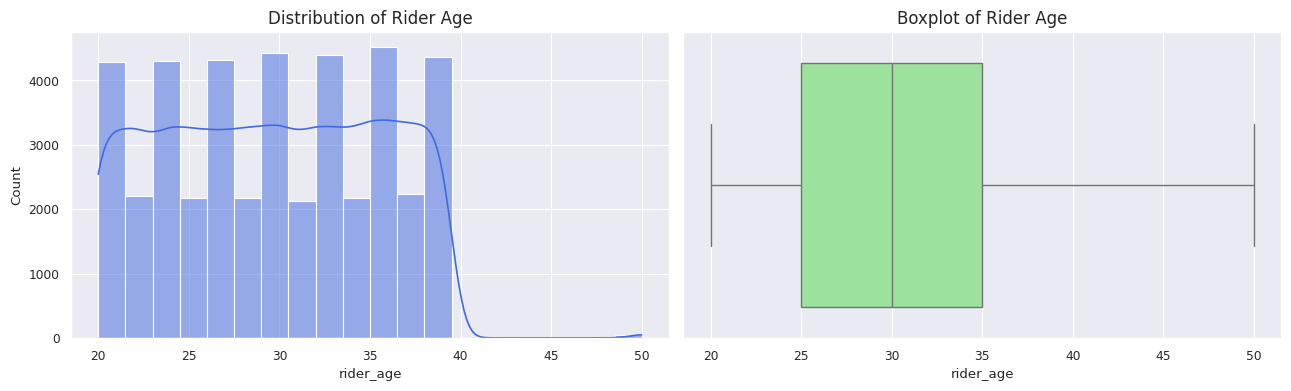

In [ ]:
get_numerical_info(df.copy(),'rider_age', n_bins = 20)

### 5.rider_ratings

In [ ]:
df['rider_ratings'].dtype

dtype('O')

In [ ]:
df['rider_ratings'].unique()

# 'rider_ratings' has be continuous numerical feature

array(['4.9', '4.5', '4.4', '4.7', '4.6', '4.8', '4.2', '4.3', '4', '4.1',
       '5', '3.5', nan, '3.8', '3.9', '3.7', '2.6', '2.5', '3.6', '3.1',
       '2.7', '3.2', '3.3', '6', '3.4', '2.8', '2.9', '3'], dtype=object)

In [ ]:
# Changing data type

df['rider_ratings'] = pd.to_numeric(df['rider_ratings'], errors = 'coerce')

print(df['rider_ratings'].dtype)

float64


Data-Type of "rider_ratings": float64
Total NaN values in "rider_ratings" : 1908
% of NaN values in "rider_ratings" : 4.19%


,rider_ratings
count,43647.00
mean,4.64
std,0.32
min,2.50
25%,4.50
50%,4.70
75%,4.90
max,6.00


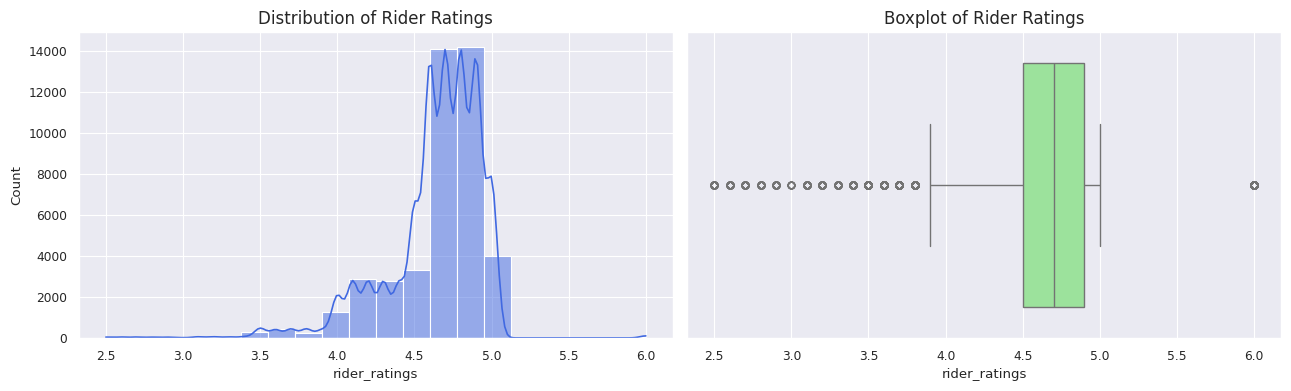

In [ ]:
get_numerical_info(df.copy(), 'rider_ratings', n_bins = 20)

Q. How can maximum ratings be 6 ?

The rider rating of `6` is an anomaly in the data as maximum rider rating can be 5 and not more than that
  - Has to be investigated
  - If data is problematic than fixing or removing is an option

In [ ]:
# rows where the rider_rating = 6

six_star_ratings = df[df['rider_ratings'] > 5]

display(six_star_ratings)

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,festival,city_name,city_type,time_taken
3586,BANGRES05DEL01,50.0,6.0,-12.970324,-77.645748,13.010324,77.685748,Meal,13-03-2022,NaN,12:30:00,NaN,NaN,electric_scooter,3,0,No,Bangalore,Urban,25
4714,HYDRES17DEL01,50.0,6.0,-17.451976,-78.385883,17.561976,78.495883,Snack,04-04-2022,NaN,23:20:00,NaN,NaN,bicycle,3,0,No,Hyderabad,Metropolitian,27
5169,JAPRES08DEL01,50.0,6.0,-26.910262,-75.783013,27.020262,75.893013,Drinks,18-03-2022,NaN,18:50:00,NaN,NaN,scooter,3,1,No,Jaipur,Metropolitian,20
5362,BANGRES19DEL01,50.0,6.0,12.914264,77.678400,13.024264,77.788400,Meal,06-04-2022,NaN,20:55:00,NaN,NaN,electric_scooter,3,1,No,Bangalore,Metropolitian,18
5651,AGRRES13DEL02,50.0,6.0,-27.159795,-78.042990,27.209795,78.092990,Drinks,13-02-2022,NaN,18:05:00,NaN,NaN,scooter,3,1,No,Agra,Metropolitian,20
6394,JAPRES06DEL02,50.0,6.0,26.911927,75.797282,27.041927,75.927282,Meal,02-04-2022,NaN,22:10:00,NaN,NaN,electric_scooter,3,0,No,Jaipur,Urban,20
7031,MYSRES15DEL02,50.0,6.0,-12.352058,-76.606650,12.372058,76.626650,Buffet,15-03-2022,NaN,10:00:00,NaN,NaN,scooter,3,1,No,Mysore,Metropolitian,14
7681,VADRES09DEL01,50.0,6.0,0.000000,0.000000,0.010000,0.010000,Meal,21-03-2022,NaN,08:35:00,NaN,NaN,bicycle,3,1,No,Vadodara,Metropolitian,22
9499,BANGRES010DEL01,50.0,6.0,12.933298,77.614293,13.003298,77.684293,Drinks,12-03-2022,NaN,18:25:00,NaN,NaN,scooter,3,1,No,Bangalore,Urban,17
9535,RANCHIRES13DEL01,50.0,6.0,-23.374989,-85.335486,23.444989,85.405486,Snack,20-03-2022,NaN,17:55:00,NaN,NaN,bicycle,3,1,No,Ranchi,Metropolitian,32


In [ ]:
print(len(six_star_ratings))

mask = six_star_ratings.isnull().sum()
mask[mask > 0]

# same problems just like rider_age column

53


,0
order_time,53
weather,53
traffic,53
city_type,2


In [ ]:
print('Before',df.shape)

# Data removal seems logical at this stage

df.drop(index = df[df['rider_ratings'] > 5].index, inplace = True)

print('After',df.shape)

Before (45555, 20)
After (45502, 20)


Data-Type of "rider_ratings": float64
Total NaN values in "rider_ratings" : 1908
% of NaN values in "rider_ratings" : 4.19%


,rider_ratings
count,43594.00
mean,4.64
std,0.31
min,2.50
25%,4.50
50%,4.70
75%,4.90
max,5.00


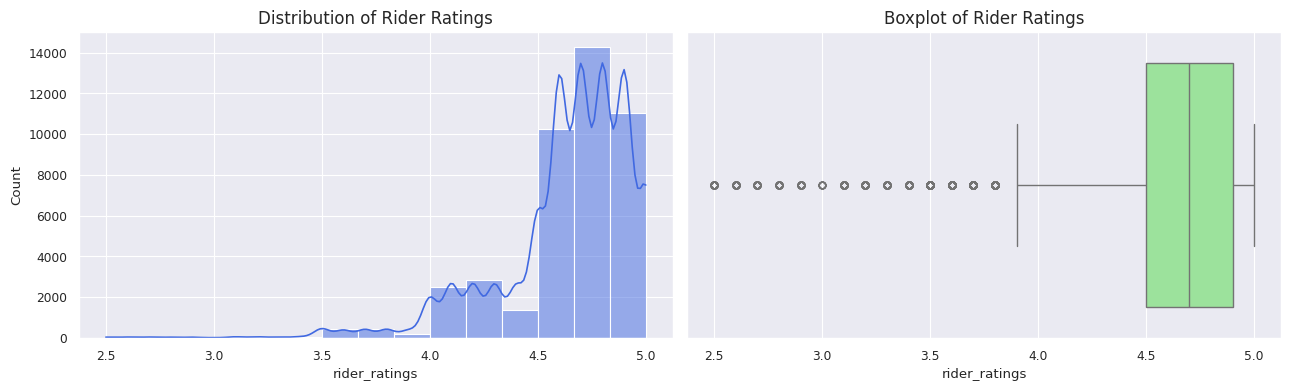

In [ ]:
get_numerical_info(df.copy(), 'rider_ratings', n_bins = 15)

In [ ]:
df[df['rider_age']>=40] # this corrupted data problem also get solved as we clean rider_ratings

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,festival,city_name,city_type,time_taken


Data-Type of "rider_age": float64
Total NaN values in "rider_age" : 1854
% of NaN values in "rider_age" : 4.07%


,rider_age
count,43648.00
mean,29.56
std,5.76
min,20.00
25%,25.00
50%,30.00
75%,35.00
max,39.00


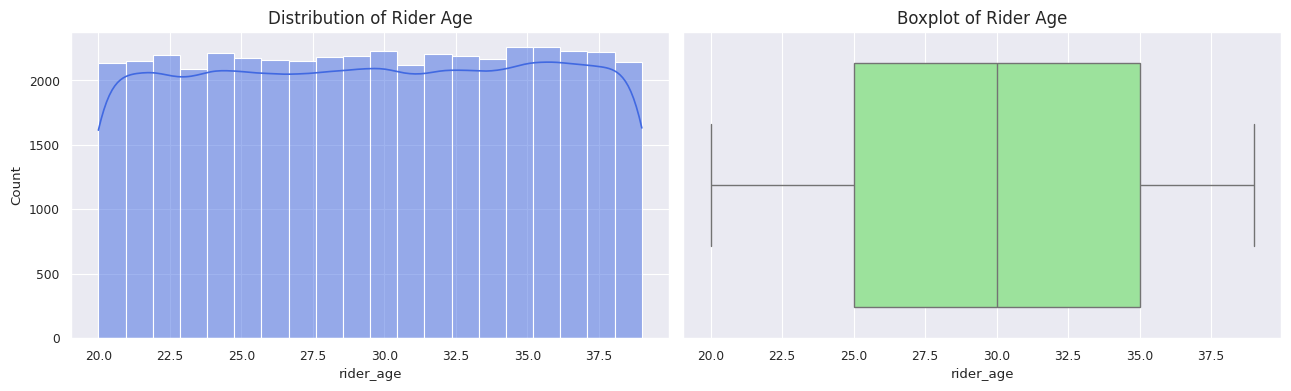

In [ ]:
get_numerical_info(df.copy(),'rider_age', n_bins = 20)

### 6.order_type

In [ ]:
df['order_type'].dtype

dtype('O')

In [ ]:
get_categorical_info(df.copy(), 'order_type')

Data-Type of "order_type" : object
Unique values in "order_type" : ['Snack' 'Drinks' 'Buffet' 'Meal']
Total unique values in "order_type" : 4
% of NaN values in "order_type" : 0.0



,order_type,count,proportion
0,Snack,11512,25.29999
1,Meal,11435,25.13076
2,Drinks,11294,24.82089
3,Buffet,11261,24.74836


### 7.weather

In [ ]:
get_categorical_info(df.copy(),'weather')

Data-Type of "weather" : object
Unique values in "weather" : ['conditions Sunny' 'conditions Stormy' 'conditions Sandstorms'
 'conditions Cloudy' 'conditions Fog' 'conditions Windy' nan]
Total unique values in "weather" : 6
% of NaN values in "weather" : 1.15



,weather,count,proportion
0,conditions Fog,7654,17.01759
1,conditions Stormy,7586,16.86640
2,conditions Cloudy,7536,16.75523
3,conditions Sandstorms,7495,16.66407
4,conditions Windy,7422,16.50177
5,conditions Sunny,7284,16.19494


In [ ]:
df['weather'] = df['weather'].str.split().str.get(1)

In [ ]:
get_categorical_info(df.copy(),'weather')

Data-Type of "weather" : object
Unique values in "weather" : ['Sunny' 'Stormy' 'Sandstorms' 'Cloudy' 'Fog' 'Windy' nan]
Total unique values in "weather" : 6
% of NaN values in "weather" : 1.15



,weather,count,proportion
0,Fog,7654,17.01759
1,Stormy,7586,16.86640
2,Cloudy,7536,16.75523
3,Sandstorms,7495,16.66407
4,Windy,7422,16.50177
5,Sunny,7284,16.19494


### 8.traffic

In [ ]:
get_categorical_info(df.copy(), 'traffic')

Data-Type of "traffic" : object
Unique values in "traffic" : ['High' 'Jam' 'Low' 'Medium' nan]
Total unique values in "traffic" : 4
% of NaN values in "traffic" : 1.12



,traffic,count,proportion
0,Low,15477,34.39945
1,Jam,14143,31.43448
2,Medium,10947,24.33099
3,High,4425,9.83508


### 9.vehicle_type

In [ ]:
get_categorical_info(df.copy(), 'vehicle_type')

Data-Type of "vehicle_type" : object
Unique values in "vehicle_type" : ['motorcycle' 'scooter' 'electric_scooter' 'bicycle']
Total unique values in "vehicle_type" : 4
% of NaN values in "vehicle_type" : 0.0



,vehicle_type,count,proportion
0,motorcycle,26427,58.07877
1,scooter,15244,33.50182
2,electric_scooter,3778,8.30293
3,bicycle,53,0.11648


In [ ]:
vehicle_type_mapping = {'motorcycle': 'Motor-Cycle',
                        'scooter': 'Scooter',
                        'electric_scooter': 'Electric-Scooter',
                        'bicycle': 'Bicycle'}

df['vehicle_type'].replace(vehicle_type_mapping, inplace = True)

In [ ]:
get_categorical_info(df.copy(),'vehicle_type')

Data-Type of "vehicle_type" : object
Unique values in "vehicle_type" : ['Motor-Cycle' 'Scooter' 'Electric-Scooter' 'Bicycle']
Total unique values in "vehicle_type" : 4
% of NaN values in "vehicle_type" : 0.0



,vehicle_type,count,proportion
0,Motor-Cycle,26427,58.07877
1,Scooter,15244,33.50182
2,Electric-Scooter,3778,8.30293
3,Bicycle,53,0.11648


### 10.vehicle_condition

In [ ]:
df['vehicle_condition'].dtype

dtype('int64')

In [ ]:
get_categorical_info(df,'vehicle_condition')

# Discrete numerical data
# Data can take only specific separate values, Often countable one
# Canot take values between those fixed points
#
# For example: vehicled_condition
# vehicle_condition can take only fixed values with a range [0-3]
# Can't take values between those fixed points for ex: 0.2, 1.5, 2.6....and so on

Data-Type of "vehicle_condition" : int64
Unique values in "vehicle_condition" : [2 0 1 3]
Total unique values in "vehicle_condition" : 4
% of NaN values in "vehicle_condition" : 0.0



,vehicle_condition,count,proportion
0,2,15034,33.04031
1,1,15030,33.03152
2,0,15009,32.98536
3,3,429,0.94282


### 11.multiple_deliveries

In [ ]:
df['multiple_deliveries'].dtype

dtype('O')

In [ ]:
get_categorical_info(df, 'multiple_deliveries')

Data-Type of "multiple_deliveries" : object
Unique values in "multiple_deliveries" : ['0' '1' '3' nan '2']
Total unique values in "multiple_deliveries" : 4
% of NaN values in "multiple_deliveries" : 2.18



,multiple_deliveries,count,proportion
0,1,28109,63.15352
1,0,14057,31.58238
2,2,1982,4.45303
3,3,361,0.81107


In [ ]:
df['multiple_deliveries'] = pd.to_numeric(df['multiple_deliveries'], errors = 'coerce')

### 12.festival

In [ ]:
get_categorical_info(df,'festival')

Data-Type of "festival" : object
Unique values in "festival" : ['No' 'Yes' nan]
Total unique values in "festival" : 2
% of NaN values in "festival" : 0.5



,festival,count,proportion
0,No,44380,98.02536
1,Yes,894,1.97464


In [ ]:
df['festival'] = df['festival'].replace({'No':False, 'Yes':True}).astype('boolean')

df.rename(columns = {'festival':'is_festival'}, inplace = True)

In [ ]:
get_categorical_info(df,'is_festival')

Data-Type of "is_festival" : boolean
Unique values in "is_festival" : <BooleanArray>
[False, True, <NA>]
Length: 3, dtype: boolean
Total unique values in "is_festival" : 2
% of NaN values in "is_festival" : 0.5



,is_festival,count,proportion
0,False,44380,98.02536
1,True,894,1.97464


### 13.city_type & city_name

In [ ]:
get_categorical_info(df,'city_type')

Data-Type of "city_type" : object
Unique values in "city_type" : ['Urban' 'Metropolitian' 'Semi-Urban' nan]
Total unique values in "city_type" : 3
% of NaN values in "city_type" : 2.63



,city_type,count,proportion
0,Metropolitian,34029,76.80796
1,Urban,10111,22.82187
2,Semi-Urban,164,0.37017


In [ ]:
get_categorical_info(df,'city_name')

Data-Type of "city_name" : object
Unique values in "city_name" : ['Indore' 'Bangalore' 'Coimbatore' 'Chennai' 'Hyderabad' 'Ranchi' 'Mysore'
 'Delhi' 'Kochi' 'Pune' 'Ludhiana' 'Kanpur' 'Mumbai' 'Kolkata' 'Jaipur'
 'Surat' 'Goa' 'Aurangabad' 'Agra' 'Vadodara' 'Prayagraj' 'Bhopal']
Total unique values in "city_name" : 22
% of NaN values in "city_name" : 0.0



,city_name,count,proportion
0,Jaipur,3439,7.55791
1,Ranchi,3222,7.08101
2,Bangalore,3184,6.99749
3,Surat,3182,6.99310
4,Hyderabad,3177,6.98211
5,Mumbai,3168,6.96233
6,Mysore,3164,6.95354
7,Coimbatore,3162,6.94915
8,Vadodara,3159,6.94255
9,Indore,3154,6.93156


In [ ]:
df.groupby('city_name')['city_type'].unique()

,city_type
city_name,
Agra,"[Metropolitian, Urban, nan, Semi-Urban]"
Aurangabad,"[Metropolitian, Urban, nan, Semi-Urban]"
Bangalore,"[Metropolitian, Urban, nan, Semi-Urban]"
Bhopal,"[Metropolitian, Urban, Semi-Urban, nan]"
Chennai,"[Metropolitian, Urban, nan, Semi-Urban]"
Coimbatore,"[Metropolitian, Urban, nan, Semi-Urban]"
Delhi,"[Metropolitian, Urban, nan, Semi-Urban]"
Goa,"[Urban, Metropolitian, nan, Semi-Urban]"
Hyderabad,"[Urban, Metropolitian, nan, Semi-Urban]"


Observations:

- The same city appears with multiple `city_type` labels
- There are higher chances that the city itself was divided into 3 different parts/zones
  - Zone-1 : Metropolitan
  - Zone-2 : Urban
  - Zone-3 : Semi-urban
  
- But this indicates categorical inconsistency.
- Suppose if Bangalore is sometimes: Metropolitan, Urban, Semi-Urban, then our model cannot learn stable behavior.
- A city should have one deterministic classification, not multiple.

In [ ]:
# I Try: to resolve this inconsistency using majority voting
# Disclaimer:
# This type of cleaning might infuses a bias in our data
# because after this:
# - Now differnt parts of city represent same city_type
# - From our basic day-to-day life knowledge we know that,
# - food deliveries are faster in Metropolitan areas than in Urban or Semi-Urban and so on
# - and the deliveries are faster in Urban then in Semi-Urban
# - Because of more availablity of restaurants, cafes and riders(employee)
#
# - But from this majority voting we explicitley label whole city as one city_type
# - For ex: Suppose Kanpur is divided into 3 different xones but now after this majority voting it only labelled as Urban
#
# - That's my observation & it is based on the assumption that: city itself was divideed into 3 different parts/zones in this data

city_info = df.groupby('city_name', as_index = False)['city_type'].value_counts().sort_values(by = 'count', ascending = False)
city_info.drop_duplicates(subset = ['city_name'], keep = 'first', inplace = True)
city_info.reset_index(drop = True, inplace = True)
city_info

# After cleaning: Every city resolved to Metropolitan
# which signifies that most of the zones present in our data are Metropolitan
# and if the city_type has no variablity in - it's our no use

# Since the feature never changes, it:
# 1. If a feature has the same value for every row, it tells the model nothing new.
# 2. It provides model, no information for distinguishing between different samples.
# 3. Cannot help the model make predictions.
# 4. Adds unnecessary computation and increases dataset size without any benefit.

,city_name,city_type,count
0,Jaipur,Metropolitian,2569
1,Hyderabad,Metropolitian,2385
2,Coimbatore,Metropolitian,2382
3,Surat,Metropolitian,2380
4,Ranchi,Metropolitian,2379
5,Indore,Metropolitian,2376
6,Mysore,Metropolitian,2366
7,Chennai,Metropolitian,2361
8,Mumbai,Metropolitian,2360
9,Bangalore,Metropolitian,2354


If all cities resolve to one category:
1. The feature with no variability is often not useful.
2. Add unnecessary columns after encoding
3. It has low predictive power
4. It adds noise rather than signal
5. It may distort model learning

In [ ]:
df.drop(columns = ['city_type'], inplace = True)

In [ ]:
df.head()

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,is_festival,city_name,time_taken
0,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,Snack,19-03-2022,11:30:00,11:45:00,Sunny,High,Motor-Cycle,2,0.0,False,Indore,24
1,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,Snack,25-03-2022,19:45:00,19:50:00,Stormy,Jam,Scooter,2,1.0,False,Bangalore,33
2,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,19-03-2022,08:30:00,08:45:00,Sandstorms,Low,Motor-Cycle,0,1.0,False,Bangalore,26
3,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,05-04-2022,18:00:00,18:10:00,Sunny,Medium,Motor-Cycle,0,1.0,False,Coimbatore,21
4,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,Snack,26-03-2022,13:30:00,13:45:00,Cloudy,High,Scooter,1,1.0,False,Chennai,30


### 14.Geospatial columns

In [ ]:
geospatial_columns = ['restaurant_latitude', 'restaurant_longitude', 'delivery_latitude', 'delivery_longitude']
location_df = df[geospatial_columns]

get_missing_info(location_df)

,feature,data_type,missing_count,missing_%
0,restaurant_latitude,float64,0,0.0
1,restaurant_longitude,float64,0,0.0
2,delivery_latitude,float64,0,0.0
3,delivery_longitude,float64,0,0.0


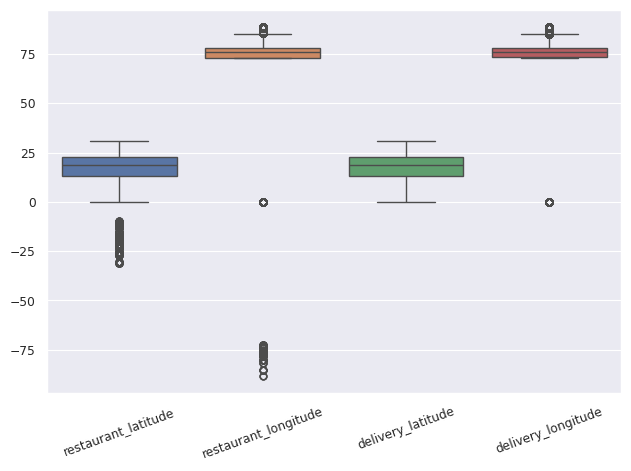

,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude
count,45502.000000,45502.000000,45502.000000,45502.000000
mean,17.046293,70.326557,17.468434,70.848718
std,8.131457,22.591753,7.334058,21.111306
min,-30.905562,-88.352885,0.010000,0.010000
25%,12.933284,73.170283,12.988453,73.280000
50%,18.551440,75.898497,18.634382,76.002471
75%,22.728163,78.045043,22.785049,78.105359
max,30.914057,88.433452,31.054057,88.563452


In [ ]:
sns.boxplot(location_df)
plt.xticks(rotation = 20)
plt.tight_layout()
plt.show()

# negative, excatly 0, ~0 values in restaurant_latitude & restaurant_longitude
# 0 & near 0 values in delivery_latitude and delivery_longitude

location_df.describe()

This range covers everything in India from the northern tip of Ladakh to the southernmost point of the Andaman and Nicobar Islands.

- Latitude: $6^\circ 44'$ N to $37^\circ 6'$ N
- Longitude: $68^\circ 7'$ E to $97^\circ 25'$ E

---
- Latitude (North-South): $6.7467^\circ \text{ N}$ to $37.1000^\circ \text{ N}$
- Longitude (West-East): $68.1167^\circ \text{ E}$ to $97.4167^\circ \text{ E}$

In [ ]:
import plotly.express as px

In [ ]:
# Correct range
mask1 = df['restaurant_latitude'].between(6.7467,37.1)
mask2 = df['restaurant_longitude'].between(68.1167,97.4167)
mask3 = df['delivery_latitude'].between(6.7467,37.1)
mask4 = df['delivery_longitude'].between(68.1167,97.4167)

geospatial_errors_df = df.loc[~(mask1 & mask2 & mask3 & mask4),geospatial_columns]

print(f'Number of rows that have geospatial errors: {geospatial_errors_df.shape[0]}')

display(geospatial_errors_df)

Number of rows that have geospatial errors: 4029


,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude
33,0.000000,0.000000,0.110000,0.110000
52,0.000000,0.000000,0.030000,0.030000
57,0.000000,0.000000,0.080000,0.080000
59,0.000000,0.000000,0.060000,0.060000
67,0.000000,0.000000,0.020000,0.020000
68,0.000000,0.000000,0.040000,0.040000
72,0.000000,0.000000,0.080000,0.080000
73,0.000000,0.000000,0.020000,0.020000
76,0.000000,0.000000,0.050000,0.050000
81,0.000000,0.000000,0.110000,0.110000


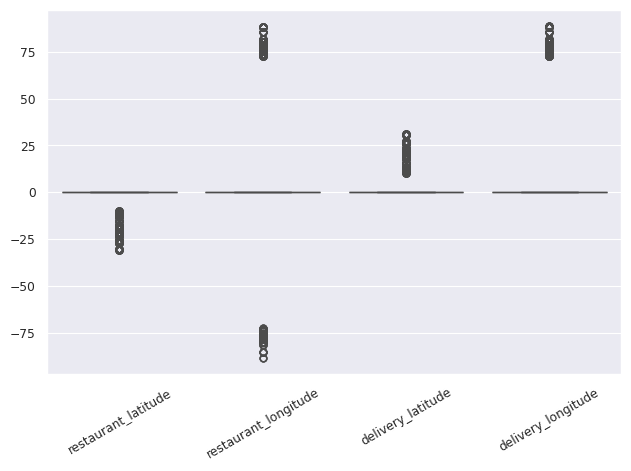

In [ ]:
sns.boxplot(geospatial_errors_df)
plt.xticks(rotation = 30)
plt.tight_layout()
plt.show()

#### a. Geospatial error Type - 1
- Negative coordinate in `restaurant_latitude` and `restaurant_longitude`

In [ ]:
mask1 = geospatial_errors_df['restaurant_latitude'] < 0
mask2 = geospatial_errors_df['restaurant_longitude'] < 0
type1_error_df = geospatial_errors_df[mask1 | mask2]
type1_error_df

,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude
92,-27.163303,78.057044,27.233303,78.127044
283,-27.165108,78.015053,27.225108,78.075053
289,-18.551440,-73.804855,18.611440,73.864855
425,-30.366322,-78.070453,30.496322,78.200453
534,-12.325461,-76.632278,12.385461,76.692278
583,-12.316967,76.603067,12.326967,76.613067
762,-23.359194,-85.325447,23.449194,85.415447
1059,-26.477750,-80.351569,26.487750,80.361569
1091,-15.546594,73.760431,15.606594,73.820431
1157,-12.337978,76.616792,12.387978,76.666792


In [ ]:
round(abs(type1_error_df['restaurant_latitude']) - abs(type1_error_df['delivery_latitude'])).unique()

array([-0.])

In [ ]:
round(abs(type1_error_df['restaurant_longitude']) - abs(type1_error_df['delivery_longitude'])).unique()

array([-0.])

That confirms:
- Magnitudes are almost equal
- Only sign difference
- Strong evidence of synthetic corruption
- The differences were near zero, indicating systematic sign inversion

Hence:

1. Negative Values are correct. They are just sign flipped
2. We just have to take absolute of them

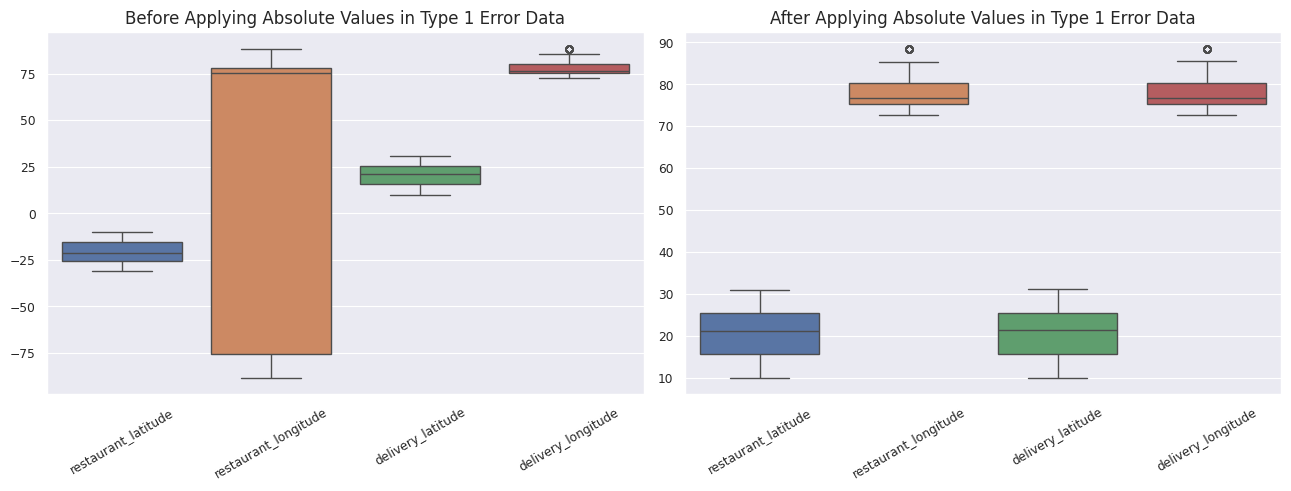

In [ ]:
fig, (ax1,ax2) = plt.subplots(nrows = 1, ncols = 2, figsize = (13, 5))

sns.boxplot(type1_error_df, ax = ax1, label = 'Before Absolute Values')
ax1.set_title('Before Applying Absolute Values in Type 1 Error Data', fontsize = 12)
ax1.tick_params(axis = 'x', rotation = 30)

sns.boxplot(type1_error_df.abs(), ax = ax2, label = 'After Absolute Values')
ax2.set_title('After Applying Absolute Values in Type 1 Error Data', fontsize = 12)
ax2.tick_params(axis = 'x', rotation = 30)
plt.tight_layout()
plt.show()

#### b. Geospatial error Type - 2
- 0 and Near 0 coordinates

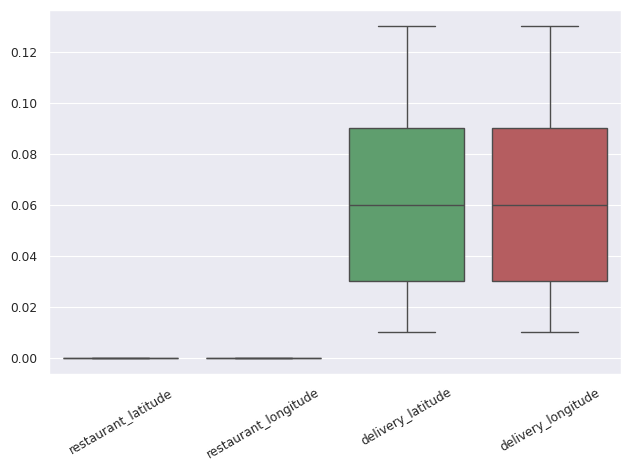

In [ ]:
mask1 = np.floor(df['restaurant_latitude']).between(0,1)
mask2 = np.floor(df['delivery_latitude']).between(0,1)
mask3 = np.floor(df['restaurant_longitude']).between(0,1)
mask4 = np.floor(df['delivery_longitude']).between(0,1)

type2_error_df = df.loc[(mask1 | mask2 | mask3 | mask4), geospatial_columns]

sns.boxplot(type2_error_df)
plt.xticks(rotation = 30)
plt.tight_layout()
plt.show()

In [ ]:
fig = px.scatter_mapbox(type2_error_df, lat = 'delivery_latitude', lon = 'delivery_longitude', zoom = 4, height = 400)

fig.update_layout(
    mapbox_style = 'open-street-map',
    margin = {'r':0,'t':0,'l':0,'b':0}
)

fig.show()

In [ ]:
type2_error_df.min()

,0
restaurant_latitude,0.00
restaurant_longitude,0.00
delivery_latitude,0.01
delivery_longitude,0.01


In [ ]:
len(type2_error_df)

3630

1. All the messy `latitude` and `longitude` values which are less than 1, indicates invalid or incorrectly recorded geospatial coordinates.

2. These incorrect values should be replaced with `np.nan` so they are treated as missing data instead of valid coordinates.

3. After converting coordinates to their absolute values and setting 0 or near-zero geospatial values to `np.nan`, the distance calculations will naturally propagate `NaN` for these invalid points.

4. Once properly marked as missing, these values can then be imputed using more advanced imputation techniques.

In [ ]:
df[geospatial_columns].isnull().sum().rename('missing_values_count')

,missing_values_count
restaurant_latitude,0
restaurant_longitude,0
delivery_latitude,0
delivery_longitude,0


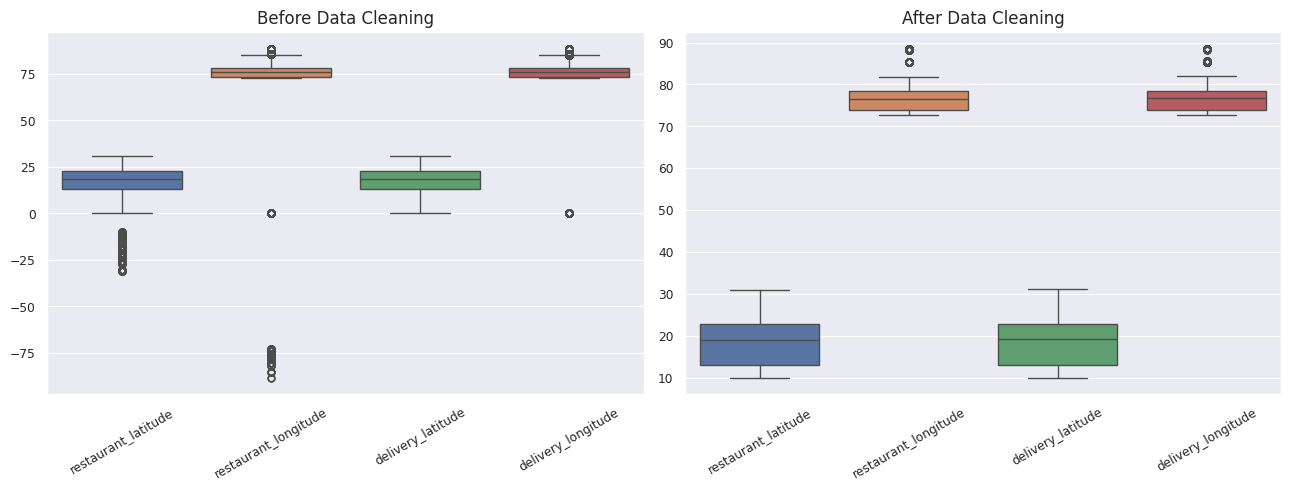

In [ ]:
fig, (ax1,ax2) = plt.subplots(nrows = 1, ncols = 2, figsize = (13, 5))

# Figure 1
sns.boxplot(df[geospatial_columns], ax = ax1)
ax1.set_title('Before Data Cleaning', fontsize = 12)
ax1.tick_params(axis = 'x', rotation = 30)

# Replaceing 0 <= coordiantes <= 1 with np.nan
# Taking absolute value of negative coordinates
df[geospatial_columns] = df[geospatial_columns].applymap(lambda x: np.nan if abs(x) <= 1 else abs(x))

# Figure 2
sns.boxplot(df[geospatial_columns], ax = ax2)
ax2.set_title('After Data Cleaning', fontsize = 12)
ax2.tick_params(axis = 'x', rotation = 30)
plt.tight_layout()
plt.show()

In [ ]:
fig = px.scatter_mapbox(df, lat = 'delivery_latitude', lon = 'delivery_longitude', zoom = 4, height = 700, hover_name = 'city_name')

fig.update_layout(
    mapbox_style = 'open-street-map',
    margin = {'r':0,'t':0,'l':0,'b':0}
)

fig.show()

In [ ]:
df[geospatial_columns].isnull().sum().rename('missing_values_count')

,missing_values_count
restaurant_latitude,3630
restaurant_longitude,3630
delivery_latitude,3630
delivery_longitude,3630


**What is Haversine Distance?**

- It is the shortest distance between two points on Earth
- Since Earth is round, not flat. So we can't use simple Euciledan distance(straight line on paper)
- Instead, Haversine calculates the distance along the Earth's 🌍 surface
- Haversine distance computes the shortest path between two geographic points on Earth using latitude and longitude while accounting for Earth's curvature.

---
**🌍 Simple Example**

Imagine:
- A restaurant location
- A delivery location

- You want the distance a rider travels. Because Earth is curved, the **shortest path is an arc**, not a straight line.
- Haversine computes that arc distance.

| Location   | Latitude | Longitude |
| ---------- | -------- | --------- |
| Restaurant | 12.97    | 77.59     |
| Delivery   | 13.03    | 77.62     |

Haversine converts these into distance

---
**🚫 Why Not Euclidean Distance?**

Euclidean assumes flat Earth.

That causes:
- distance error
- inaccurate modeling
- unrealistic travel estimates

Haversine fixes that.

---
**⭐ Real-World Analogy**

Think of flying:

Airplanes don't fly straight on a flat map — they follow curved paths over Earth.

That curved path is exactly what Haversine measures.

---
**Haversine Distance**

$$ d = 2R \arcsin \left(\sqrt{a}\right)$$
$$a = \sin^2\left(\frac{\Delta lat}{2}\right)
+ \cos(lat_1)\cos(lat_2)\sin^2\left(\frac{\Delta lon}{2}\right)$$

Mathematically:

$a$ should always satisfy: $0<=a<=1$

---
**1. R(Earth radius)**
- R = radius of Earth (**= 6371 km**)
- This converts the angular distance into kilometers.

**2. lat1,lat2**
- Latitude measures **north-south position.**

| Symbol | Meaning                              |
| ------ | ------------------------------------ |
| lat1   | latitude of first point (restaurant) |
| lat2   | latitude of second point (delivery)  |


**3. lon1,lon2**
- Longitude measures **east-west position.**  

| Symbol | Meaning                               |
| ------ | --------------------------------------|
| lon1   | longitude of first point (restaurant) |
| lon2   | longitude of second point (delivery)  |


**4. $\Delta lat$ (delta latitude)**
- Difference in north-south position
  - $\Delta lat = lat2 - lat1$
  - It tells how far north/south of the second point is from the first.  

**5. $\Delta lon$ (delta longitude)**
- Difference in east-west position
  - $\Delta lon = lon2 - lon1$
  - It tells how far east/west of the second point is from the first.  

**6. $a$**
- It represents the angular separation between two points on Earth
- Intermediate value used to compute central angle

**7. arcsin**
- Inverse sine function
- Computes half of the central angle between the two points on the sphere
- Multiplying by 2 gives full central angle

**8. Final multiplication**
- Multiplying by $2R$ converts angle into surface distance

**9. Important note**
- Latitude and longitude must be converted from **degrees to radians**
- Trigonometric functions operate on radians

**Haversine Distance**

$$ d = 2R \arcsin \left(\sqrt{a}\right)$$
$$a = \sin^2\left(\frac{\Delta lat}{2}\right)
+ \cos(lat_1)\cos(lat_2)\sin^2\left(\frac{\Delta lon}{2}\right)$$

Mathematically:

`a` should always satisfy: $0<=a<=1$

In [ ]:
def calculate_haversine_distance_km(df:pd.DataFrame):

    R = 6371  # Earth radius in km

    rest_lat1 = np.radians(df['restaurant_latitude'])
    rest_lon1 = np.radians(df['restaurant_longitude'])
    del_lat2  = np.radians(df['delivery_latitude'])
    del_lon2  = np.radians(df['delivery_longitude'])

    dlat = del_lat2 - rest_lat1
    dlon = del_lon2 - rest_lon1

    a = np.sin(dlat/2)**2 + np.cos(rest_lat1) * np.cos(del_lat2) * np.sin(dlon/2)**2
    a = np.clip(a, 0, 1)

    haversine_distance= 2 * R * np.arcsin(np.sqrt(a))

    df.insert(loc = get_index(df,'delivery_longitude')+1, column = 'distance_km', value = haversine_distance)

    return df

In [ ]:
df = calculate_haversine_distance_km(df.copy())

In [ ]:
df.head(10)

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,distance_km,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,is_festival,city_name,time_taken
0,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,3.025149,Snack,19-03-2022,11:30:00,11:45:00,Sunny,High,Motor-Cycle,2,0.0,False,Indore,24
1,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,20.183530,Snack,25-03-2022,19:45:00,19:50:00,Stormy,Jam,Scooter,2,1.0,False,Bangalore,33
2,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,1.552758,Drinks,19-03-2022,08:30:00,08:45:00,Sandstorms,Low,Motor-Cycle,0,1.0,False,Bangalore,26
3,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,7.790401,Buffet,05-04-2022,18:00:00,18:10:00,Sunny,Medium,Motor-Cycle,0,1.0,False,Coimbatore,21
4,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,6.210138,Snack,26-03-2022,13:30:00,13:45:00,Cloudy,High,Scooter,1,1.0,False,Chennai,30
5,HYDRES09DEL03,22.0,4.8,17.431668,78.408321,17.461668,78.438321,4.610365,Buffet,11-03-2022,21:20:00,21:30:00,Cloudy,Jam,Motor-Cycle,0,1.0,False,Hyderabad,26
6,RANCHIRES15DEL01,33.0,4.7,23.369746,85.339820,23.479746,85.449820,16.600361,Meal,04-03-2022,19:15:00,19:30:00,Fog,Jam,Scooter,1,1.0,False,Ranchi,40
7,MYSRES15DEL02,35.0,4.6,12.352058,76.606650,12.482058,76.736650,20.205253,Meal,14-03-2022,17:25:00,17:30:00,Cloudy,Medium,Motor-Cycle,2,1.0,False,Mysore,32
8,HYDRES05DEL02,22.0,4.8,17.433809,78.386744,17.563809,78.516744,19.975520,Buffet,20-03-2022,20:55:00,21:05:00,Stormy,Jam,Motor-Cycle,0,1.0,False,Hyderabad,34
9,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,10.280582,Snack,12-02-2022,21:55:00,22:10:00,Fog,Jam,Motor-Cycle,2,3.0,False,Delhi,46


In [ ]:
df[geospatial_columns].isnull().sum()

,0
restaurant_latitude,3630
restaurant_longitude,3630
delivery_latitude,3630
delivery_longitude,3630


Data-Type of "distance_km": float64
Total NaN values in "distance_km" : 3630
% of NaN values in "distance_km" : 7.98%


,distance_km
count,41872.00
mean,9.72
std,5.60
min,1.47
25%,4.66
50%,9.19
75%,13.68
max,20.97


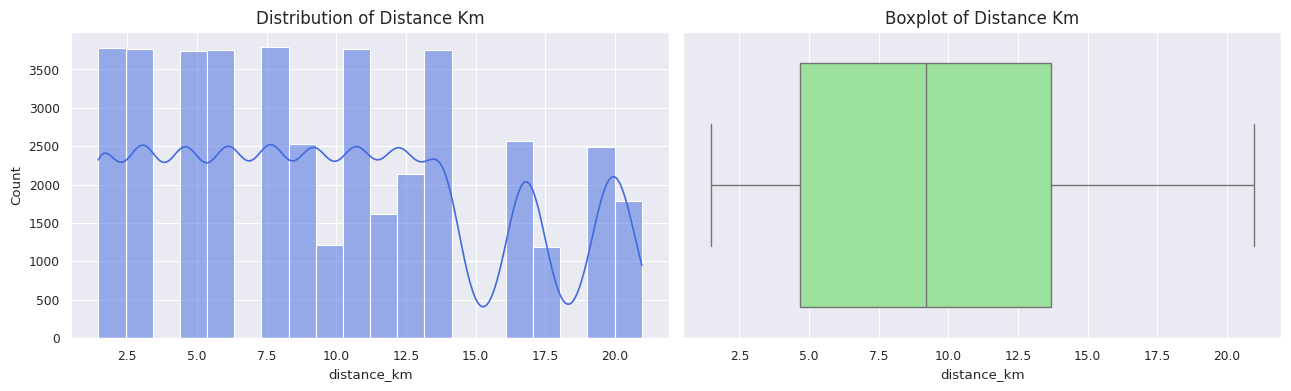

In [ ]:
get_numerical_info(df, 'distance_km', n_bins = 20)

### 15.Date & time columns

In [ ]:
df.head()

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,distance_km,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,is_festival,city_name,time_taken
0,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,3.025149,Snack,19-03-2022,11:30:00,11:45:00,Sunny,High,Motor-Cycle,2,0.0,False,Indore,24
1,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,20.183530,Snack,25-03-2022,19:45:00,19:50:00,Stormy,Jam,Scooter,2,1.0,False,Bangalore,33
2,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,1.552758,Drinks,19-03-2022,08:30:00,08:45:00,Sandstorms,Low,Motor-Cycle,0,1.0,False,Bangalore,26
3,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,7.790401,Buffet,05-04-2022,18:00:00,18:10:00,Sunny,Medium,Motor-Cycle,0,1.0,False,Coimbatore,21
4,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,6.210138,Snack,26-03-2022,13:30:00,13:45:00,Cloudy,High,Scooter,1,1.0,False,Chennai,30


In [ ]:
df['order_date'].unique()

# 1. Year information is not valuable, as we only have 2022 data, there is no variablity in year
# 2. If a feature has the same value for every row, it tells the model nothing new.
# 3. Provides no information for distinguishing between different samples.

array(['19-03-2022', '25-03-2022', '05-04-2022', '26-03-2022',
       '11-03-2022', '04-03-2022', '14-03-2022', '20-03-2022',
       '12-02-2022', '13-02-2022', '14-02-2022', '02-04-2022',
       '01-03-2022', '16-03-2022', '15-02-2022', '10-03-2022',
       '27-03-2022', '12-03-2022', '01-04-2022', '05-03-2022',
       '11-02-2022', '08-03-2022', '03-04-2022', '30-03-2022',
       '28-03-2022', '18-03-2022', '06-04-2022', '04-04-2022',
       '24-03-2022', '09-03-2022', '02-03-2022', '13-03-2022',
       '29-03-2022', '31-03-2022', '17-03-2022', '07-03-2022',
       '15-03-2022', '16-02-2022', '03-03-2022', '18-02-2022',
       '23-03-2022', '17-02-2022', '06-03-2022', '21-03-2022'],
      dtype=object)

In [ ]:
pd.to_datetime(df['order_date']).agg(['min','max']).set_axis(['min_date','max_date'], axis = 0)

# Data is from 11th February 2022 to 6th April 2022

,order_date
min_date,2022-02-11
max_date,2022-04-06


In [ ]:
diff = pd.to_datetime(df['order_date']).max() - pd.to_datetime(df['order_date']).min() # we have 54 days of swiggy data
diff

Timedelta('54 days 00:00:00')

In [ ]:
diff.days

54

In [ ]:
get_missing_info(df[['order_date','order_time','order_picked_time']])

,feature,data_type,missing_count,missing_%
0,order_date,object,0,0.0
1,order_time,object,1640,3.6
2,order_picked_time,object,0,0.0


#### a. Understand logic behind midnight hour crossing

In [ ]:
df1 = df.copy()

x1 = df1['order_date']
x2 = df1['order_time']
x3 = pd.to_timedelta(df1['order_time'])
x4 = (pd.to_datetime(df1['order_date']) + pd.to_timedelta(df1['order_time'], errors = 'coerce')).rename('order_placed_datetime')

pd.concat([x1,x2,x3,x4], axis = 1).head(10)

,order_date,order_time,order_time,order_placed_datetime
0,19-03-2022,11:30:00,0 days 11:30:00,2022-03-19 11:30:00
1,25-03-2022,19:45:00,0 days 19:45:00,2022-03-25 19:45:00
2,19-03-2022,08:30:00,0 days 08:30:00,2022-03-19 08:30:00
3,05-04-2022,18:00:00,0 days 18:00:00,2022-04-05 18:00:00
4,26-03-2022,13:30:00,0 days 13:30:00,2022-03-26 13:30:00
5,11-03-2022,21:20:00,0 days 21:20:00,2022-03-11 21:20:00
6,04-03-2022,19:15:00,0 days 19:15:00,2022-03-04 19:15:00
7,14-03-2022,17:25:00,0 days 17:25:00,2022-03-14 17:25:00
8,20-03-2022,20:55:00,0 days 20:55:00,2022-03-20 20:55:00
9,12-02-2022,21:55:00,0 days 21:55:00,2022-02-12 21:55:00


In [ ]:
x = pd.to_datetime(df1['order_date']) + pd.to_timedelta(df1['order_time'], errors = 'coerce')
df1.insert(loc = get_index(df1,'order_date')+1, column = 'order_placed_datetime', value = x)

y = pd.to_datetime(df1['order_date']) + pd.to_timedelta(df1['order_picked_time'], errors = 'coerce')
df1.insert(loc = get_index(df1,'order_time')+1, column = 'order_picked_datetime', value = y)

df1.drop(columns = ['order_date', 'order_time', 'order_picked_time'], inplace = True)

df1.head()

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,distance_km,order_type,order_placed_datetime,order_picked_datetime,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,is_festival,city_name,time_taken
0,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,3.025149,Snack,2022-03-19 11:30:00,2022-03-19 11:45:00,Sunny,High,Motor-Cycle,2,0.0,False,Indore,24
1,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,20.183530,Snack,2022-03-25 19:45:00,2022-03-25 19:50:00,Stormy,Jam,Scooter,2,1.0,False,Bangalore,33
2,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,1.552758,Drinks,2022-03-19 08:30:00,2022-03-19 08:45:00,Sandstorms,Low,Motor-Cycle,0,1.0,False,Bangalore,26
3,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,7.790401,Buffet,2022-04-05 18:00:00,2022-04-05 18:10:00,Sunny,Medium,Motor-Cycle,0,1.0,False,Coimbatore,21
4,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,6.210138,Snack,2022-03-26 13:30:00,2022-03-26 13:45:00,Cloudy,High,Scooter,1,1.0,False,Chennai,30


In [ ]:
get_missing_info(df1[['order_placed_datetime','order_picked_datetime']])

,feature,data_type,missing_count,missing_%
0,order_placed_datetime,datetime64[ns],1640,3.6
1,order_picked_datetime,datetime64[ns],0,0.0


In [ ]:
mask = df1['order_placed_datetime'].dt.hour == 0
df1[mask].head()

# 00:00:00 is not shown because order_placed_datetime is a datetime column, and pandas displays midnight time as only the date.

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,distance_km,order_type,order_placed_datetime,order_picked_datetime,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,is_festival,city_name,time_taken
125,COIMBRES12DEL02,23.0,4.9,11.000762,76.981876,11.130762,77.111876,20.253785,Meal,2022-03-18,2022-03-18 00:15:00,Windy,Low,Scooter,1,0.0,False,Coimbatore,18
608,BHPRES15DEL03,38.0,4.8,23.234249,77.434007,23.294249,77.494007,9.059752,Meal,2022-02-11,2022-02-11 00:10:00,Fog,Low,Scooter,1,1.0,False,Bhopal,17
705,HYDRES13DEL03,39.0,4.5,17.431477,78.400350,17.521477,78.490350,13.830016,Drinks,2022-03-02,2022-03-02 00:05:00,Fog,Low,Motor-Cycle,2,0.0,False,Hyderabad,37
834,CHENRES04DEL03,33.0,4.7,13.029780,80.208812,13.059780,80.238812,4.657128,Drinks,2022-03-09,2022-03-09 00:15:00,Sunny,Low,Scooter,2,0.0,False,Chennai,10
895,AURGRES19DEL02,25.0,4.7,19.866969,75.318894,19.916969,75.368894,7.631714,Snack,2022-02-13,2022-02-13 00:10:00,Sandstorms,Low,Scooter,1,1.0,False,Aurangabad,19


In [ ]:
df.loc[df1[mask].index].head()

,rider_id,rider_age,rider_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,distance_km,order_type,order_date,order_time,order_picked_time,weather,traffic,vehicle_type,vehicle_condition,multiple_deliveries,is_festival,city_name,time_taken
125,COIMBRES12DEL02,23.0,4.9,11.000762,76.981876,11.130762,77.111876,20.253785,Meal,18-03-2022,00:00:00,00:15:00,Windy,Low,Scooter,1,0.0,False,Coimbatore,18
608,BHPRES15DEL03,38.0,4.8,23.234249,77.434007,23.294249,77.494007,9.059752,Meal,11-02-2022,00:00:00,00:10:00,Fog,Low,Scooter,1,1.0,False,Bhopal,17
705,HYDRES13DEL03,39.0,4.5,17.431477,78.400350,17.521477,78.490350,13.830016,Drinks,02-03-2022,00:00:00,00:05:00,Fog,Low,Motor-Cycle,2,0.0,False,Hyderabad,37
834,CHENRES04DEL03,33.0,4.7,13.029780,80.208812,13.059780,80.238812,4.657128,Drinks,09-03-2022,00:00:00,00:15:00,Sunny,Low,Scooter,2,0.0,False,Chennai,10
895,AURGRES19DEL02,25.0,4.7,19.866969,75.318894,19.916969,75.368894,7.631714,Snack,13-02-2022,00:00:00,00:10:00,Sandstorms,Low,Scooter,1,1.0,False,Aurangabad,19


In [ ]:
# No Midnight crossing

time_delta = pd.Timestamp('2022-02-09 22:00:00') - pd.Timestamp('2022-02-09 21:50:00') # order_picked_time - order_plaed_time

print(time_delta)
print(time_delta.total_seconds())

0 days 00:10:00
600.0


In [ ]:
# Midnight crossing

time_delta = pd.Timestamp('2022-02-09 00:05:00') - pd.Timestamp('2022-02-09 23:50:00') # order_picked_time - order_placed_time

print(time_delta)

# To represent -23:45:00 -> -24:00:00 + 00:15:00 -> therefore -1days +00:15:00

-1 days +00:15:00


In [ ]:
print(time_delta.total_seconds())

# In mid-night crossing time_delta.total_seconds() is always < 0

-85500.0


In [ ]:
def check_for_midnight_crossing(df1):

    # To check if midnight crossing occurs
    # Only considers indexes where values both order_placed_datetime and order_picked_datetime are present
    # Because if either of the value in those feature is not present, we cannot find out that whether mid-night crossing occurs

    indexes = (df1['order_placed_datetime'].notnull() & df1['order_picked_datetime'].notnull()).index
    time_delta = df1.loc[indexes,'order_picked_datetime'] - df1.loc[indexes,'order_placed_datetime']

    indexes_with_midnight_crossing = time_delta[time_delta.dt.total_seconds() < 0].index.tolist()

    if len(indexes_with_midnight_crossing)!= 0: # it means midnight crossing happens
      return (df1.loc[indexes_with_midnight_crossing, ['order_placed_datetime','order_picked_datetime']], indexes_with_midnight_crossing)
    else:
      return 'no_midnight_crossing_issue'

In [ ]:
data, indexes_with_midnight_crossing = check_for_midnight_crossing(df1.copy()) # 831 rows where midnight crossing happens
data

,order_placed_datetime,order_picked_datetime
75,2022-03-05 23:50:00,2022-03-05 00:05:00
101,2022-03-26 23:55:00,2022-03-26 00:10:00
164,2022-04-04 23:50:00,2022-04-04 00:00:00
166,2022-03-04 23:45:00,2022-03-04 00:00:00
325,2022-03-18 23:55:00,2022-03-18 00:10:00
395,2022-02-12 23:55:00,2022-02-12 00:00:00
443,2022-03-24 23:45:00,2022-03-24 00:00:00
542,2022-03-17 23:45:00,2022-03-17 00:00:00
568,2022-03-23 23:55:00,2022-03-23 00:05:00
575,2022-03-20 23:50:00,2022-03-20 00:05:00


In [ ]:
# How to fix date in case of Midnight crossing ?

df1.loc[indexes_with_midnight_crossing, 'order_picked_datetime'] += pd.Timedelta(days = 1) # increase day by 1

check_for_midnight_crossing(df1.copy())

'no_midnight_crossing_issue'

#### b. Understand logic behind Cyclic Encoding of Hour Using Sine and Cosine

---
##### **1. Why Hour Cannot Be Treated as a Normal Numeric Feature**

The hour of day ranges from **0 to 23**, but it is not linear. It is **cyclical** because:

- After 23 comes 0 (midnight)
- 23 and 0 are actually very close in time
- But numerically they look far apart (difference = 23)
- If hour is used directly, machine learning models may incorrectly learn that:
  - 23 is far from 0
  - 0 is far from 22

- This introduces artificial breaking of cyclical nature in time relationships.

---
##### **2. Concept of Cyclic Encoding**

To preserve circular structure, we map hour values onto a **unit circle** using trigonometric functions.

- Each hour becomes a point on the circumference of a circle.
- This ensures:
  - 23 and 0 are close
  - Smooth transition between hours
  - No artificial discontinuity
  - Better modeling of periodic patterns

---
##### **3. Mathematical Transformation**
- To map hours to a circle, we first convert hour into an angle.
- A full day corresponds to a full circle (360° or $(2\pi)$ radians).

Therefore:

$$\theta = 2\pi . \frac{hour}{24}$$

Then we compute the coordinates of that point on the circle:
$$ sin_hr = sin(\theta) $$

$$ cos_hr = cos(\theta) $$

Thus:
$$sin_hr = \sin\left(2\pi \cdot \frac{hour}{24}\right)$$

$$cos_hr = \cos\left(2\pi \cdot \frac{hour}{24}\right)$$

---
##### **4. Why Both Sine and Cosine Are Needed**

Using only sine is insufficient because:

- Multiple hours may map to same sine value
- Information loss occurs

By using both sine and cosine:

- Every hour maps to a unique point on the circle
- Circular position is fully preserved
- No Information loss occurs
- Preserve cyclical nature of time

---
##### **5. Intuition Using Examples**

| Hour | Angle     | sin(θ)     | cos(θ)     | Interpretation |
| ---- | --------- | ---------- | ---------- | -------------- |
| 0    | 0°        | 0          | 1          | midnight       |
| 6    | 90°       | 1          | 0          | morning        |
| 12   | 180°      | 0          | -1         | noon           |
| 18   | 270°      | -1         | 0          | evening        |
| 21   | 315°      | -0.71      | 0.71       | Night          |
| 23   | 345°      | close to 0 | close to 1 | near midnight  |

This shows that:
- 23 and 0 are numerically close after encoding
- Circular continuity is preserved

---
##### **6. Machine Learning Benefits**

Cyclic encoding improves model learning by:

- Preserving cyclical nature in time relationships.
- It allows machine learning models to correctly learn periodic patterns present in time-based data.
- Enhancing performance of linear and neural network models.
- Removes artificial discontinuities in time

---
##### **7. Practical Implementation**

```python
df['sin_hr'] = np.sin(2*np.pi*(df['hour']/24))
df['cos_hr'] = np.cos(2*np.pi*(df['hour']/24))
```
- This transforms a single hour feature into two cyclic features capturing its circular nature.

---
#### **8. When Cyclic Encoding Is Useful**

This approach is useful for any periodic variable such as:
- Hour of day
- Day of week
- Month of year

In [ ]:
# Since 1 radian = 57.2958 degree

hour = 0
angle_on_clock = round(2*np.pi*(hour/24)*57.2958)
print(f'{hour} hr: {angle_on_clock} degree')

hour = 6
angle_on_clock = round(2*np.pi*(hour/24)*57.2958)
print(f'{hour} hr: {angle_on_clock} degree')

hour = 12
angle_on_clock = round(2*np.pi*(hour/24)*57.2958)
print(f'{hour} hr: {angle_on_clock} degree')

hour = 18
angle_on_clock = round(2*np.pi*(hour/24)*57.2958)
print(f'{hour} hr: {angle_on_clock} degree')

hour = 21
angle_on_clock = round(2*np.pi*(hour/24)*57.2958)
print(f'{hour} hr: {angle_on_clock} degree')

hour = 23
angle_on_clock = round(2*np.pi*(hour/24)*57.2958)
print(f'{hour} hr: {angle_on_clock} degree')

hour = 24
angle_on_clock = round(2*np.pi*(hour/24)*57.2958)
print(f'{hour} hr: {angle_on_clock} degree')

0 hr: 0 degree
6 hr: 90 degree
12 hr: 180 degree
18 hr: 270 degree
21 hr: 315 degree
23 hr: 345 degree
24 hr: 360 degree


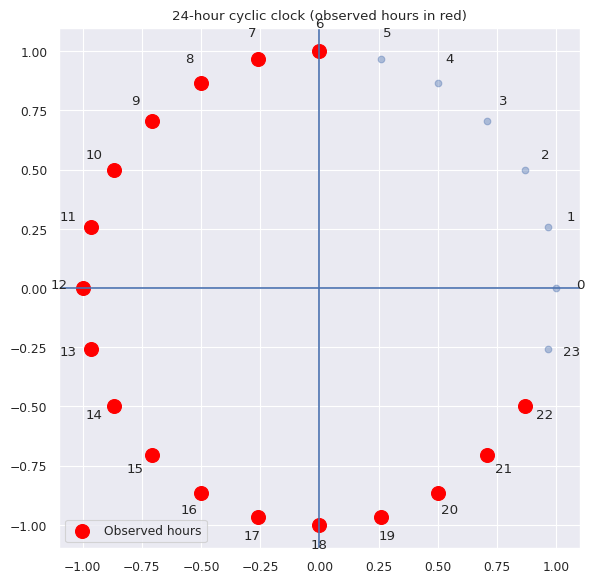

In [ ]:
hours = np.arange(24)
angles = 2*np.pi*hours/24

x = np.cos(angles)
y = np.sin(angles)

plt.figure(figsize=(6,6))

# plot all hours (background)
plt.scatter(x, y, alpha = 0.4)

# highlight selected hours in red
observed_hrs = df1['order_placed_datetime'].dt.hour.unique()
highlight_angles = 2*np.pi*observed_hrs/24
sin_h = np.sin(highlight_angles)
cos_h = np.cos(highlight_angles)

plt.scatter(sin_h, cos_h, color = 'red', s = 100, label = 'Observed hours')

# labels
for i in range(24):
    plt.text(x[i]*1.1, y[i]*1.1, str(i), ha='center')

plt.axhline(0)
plt.axvline(0)
plt.gca().set_aspect('equal')
plt.title('24-hour cyclic clock (observed hours in red)')
plt.legend()
plt.tight_layout()
plt.show()

#### c. Feature engineering for date_time columns

In [ ]:
def build_date_and_time_related_features(df):

    # ----------------------------------------------------------------------------------------
    # WHY THIS FUNCTION EXISTS
    # Delivery datasets store date and time separately, which makes temporal modeling messy
    # ----------------------------------------------------------------------------------------

    # What are we doing ?
    # 1. Combines date + time safely using timedelta addition
    # 2. Handles midnight crossing for pickup timestamps
    # 3. Extracts hour, cyclic encoding (sin/cos), and time-of-day buckets
    # 4. Computes pickup delay in minutes
    # 5. Creates rush-hour indicators
    # 6. Generates calendar features capturing weekly/monthly seasonality
    # 7. Drops redundant raw columns afterwards to save memory

    # ---------------------------------------------------------------------------------------
    # STEP 1: Create Proper Datetime Columns
    # ---------------------------------------------------------------------------------------
    # 1. Raw data stores date and time separately, so we combine them first.
    # 2. Combine date + time
    # 3. To avoid pandas assigning today's date: use pd.to_timedelta()
    # 4. errors = 'coerce' ensures invalid time become NaT instead of raising exception
    # ---------------------------------------------------------------------------------------
    df['order_placed_datetime'] = pd.to_datetime(df['order_date']) + pd.to_timedelta(df['order_time'], errors = 'coerce')
    df['order_picked_datetime'] = pd.to_datetime(df['order_date']) + pd.to_timedelta(df['order_picked_time'], errors = 'coerce')

    # --------------------------------------------------------------------------------------------------------
    # STEP 2: Handle Midnight Crossing
    # --------------------------------------------------------------------------------------------------------
    # If pickup time appears earlier than order time, it means order crossed midnight
    # Example:
    # order placed: 2022-04-10 23:50:00, pickup time: 2022-04-10 00:05:00
    # Implementation idea:
    # 1. Only compare rows where both timestamps exist, beacuse in cases where order placed time is not present,
    #    we can't find out if midnight crossing occurs
    # 2. Detect negative time differences: In mid-night crossing time_delta.total_seconds() is always < 0
    # 3. Correct those rows
    # --------------------------------------------------------------------------------------------------------
    condition_1 = df['order_placed_datetime'].notnull()
    condition_2 = df['order_picked_datetime'].notnull()
    masked_index = condition_1 & condition_2

    time_delta = df.loc[masked_index,'order_picked_datetime'] - df.loc[masked_index,'order_placed_datetime']
    midnight_crossing_index = time_delta[time_delta.dt.total_seconds() < 0].index.tolist()

    # ------------------------------------------------------
    # Add 1 day to order_picked_datetime to correct it.
    # ------------------------------------------------------
    df.loc[midnight_crossing_index, 'order_picked_datetime'] += pd.Timedelta(days = 1)

    # ---------------------------------------------------------------------------------------------
    # STEP 3: Extract Hour features
    # ---------------------------------------------------------------------------------------------
    # Hour-of-day can be predictive for delivery speed due to demand cycles and traffic patterns.
    # ---------------------------------------------------------------------------------------------

    # When order_placed_datetime exists
    # then hour value from order_placed_datetime can be used to fill value in order_placed_hr
    masked_index = df['order_placed_datetime'].notnull()
    df.loc[masked_index, 'order_placed_hr'] = df.loc[masked_index,'order_placed_datetime'].dt.hour

    # -------------------------------------------------------------------------------------------------------------
    # When order_placed_datetime is NaT & order_pickup_datetime exists and its order_picked_datetime.dt.hour != 0,
    # This signifies that there are no chances of mid-night crossing
    # Then hour value from order_picked_datetime can be used to fill value order_placed_hr
    # -------------------------------------------------------------------------------------------------------------
    condition_1 = df['order_placed_datetime'].isnull()
    condition_2 = df['order_picked_datetime'].dt.hour != 0
    masked_index2 = condition_1 & condition_2
    df.loc[masked_index2, 'order_placed_hr'] = df.loc[masked_index2, 'order_picked_datetime'].dt.hour

    # -------------------------------------------------------------------------------------------------
    # STEP 4: Time of day feature
    # -------------------------------------------------------------------------------------------------
    # Ensure your hour column ranges from 0 to 23
    conditions_list = [df['order_placed_hr'].between(5, 12,  inclusive = 'left'),  # [5, 12)  -> 05:00 AM to 11:59 AM (Morning)
                       df['order_placed_hr'].between(12, 17, inclusive = 'left'),  # [12, 17) -> 12:00 PM to 04:59 PM (Afternoon)
                       df['order_placed_hr'].between(17, 21, inclusive = 'left'),  # [17, 21) -> 05:00 PM to 08:59 PM (Evening)
                       df['order_placed_hr'].between(21, 24, inclusive = 'left')   # [21, 24) -> 09:00 PM to 11:59 PM (Night)
                      ]

    choice_list = ['Morning', 'Afternoon', 'Evening', 'Night']

    # Standard 24-hour clock resets to 0 at midnight.
    # Default 'Late Night' automatically catches hours in range [0, 5) i.e 0, 1, 2, 3, and 4
    df['order_time_of_day'] = np.select(conditions_list, choice_list, default = 'Late Night')

    # --------------------------------------------------------------------
    # STEP 5: Cyclic encoding of hour
    # --------------------------------------------------------------------
    # Hour is circular (0 -> 23 -> 0 transition) not linear (0 to 23)
    # Sin/cos encoding preserves circular structure
    # and helps models learn smooth temporal transitions.
    # --------------------------------------------------------------------
    angle_on_clock_radian = (2*np.pi*df['order_placed_hr'])/24
    df['sin_hr'] = round(np.sin(angle_on_clock_radian),4)
    df['cos_hr'] = round(np.cos(angle_on_clock_radian),4)

    # -------------------------------------------------------------------------
    # STEP 6: Calculate pickup delay (in minutes)
    # -------------------------------------------------------------------------
    # Use datetime subtraction and convert seconds into minutes
    # Delivery datasets rarely exceed 24hr, so this is a safe transformation.
    # -------------------------------------------------------------------------
    time_delta = df['order_picked_datetime'] - df['order_placed_datetime']
    df['order_pickup_time_mins']  = time_delta.dt.seconds/60

    # -------------------------------------------------------------------
    # STEP 7: Rush Hour Indicator Features
    # -------------------------------------------------------------------
    # Binary flags capturing peak demand windows
    # -------------------------------------------------------------------
    df['is_lunch_rush'] =  df['order_placed_hr'].between(13,16, inclusive = 'left').astype('boolean')
    df['is_dinner_rush'] = df['order_placed_hr'].between(20,23, inclusive = 'left').astype('boolean')

    # --------------------------------
    # STEP 8: Calendar features
    # --------------------------------
    # Ordering behavior varies by:
    # 1. weekday vs weekend
    # 2. month boundaries
    # 3. Friday night spikes
    # --------------------------------
    def get_calender_features(df):

        # -----------------------------------------------------------------------------------------------------------------------------------------------
        # When order_placed_datetime is not missing

        condition_1 = df['order_placed_datetime'].notnull()

        df.loc[condition_1,'order_month'] =       df.loc[condition_1,'order_placed_datetime'].dt.month
        df.loc[condition_1,'is_month_start'] =    df.loc[condition_1,'order_placed_datetime'].dt.is_month_start.astype('boolean')
        df.loc[condition_1,'is_month_end'] =      df.loc[condition_1,'order_placed_datetime'].dt.is_month_end.astype('boolean')
        df.loc[condition_1,'order_day'] =         df.loc[condition_1,'order_placed_datetime'].dt.day
        df.loc[condition_1,'order_day_of_week'] = df.loc[condition_1,'order_placed_datetime'].dt.day_name()

        is_friday_night = ((df.loc[condition_1,'order_day_of_week'] == 'Friday') & (df.loc[condition_1,'order_placed_datetime'].dt.hour >= 18)).astype('boolean')
        df.loc[condition_1,'is_friday_night'] = is_friday_night

        is_weekend =  (df.loc[condition_1,'order_day_of_week'].isin(['Saturday','Sunday'])).astype('boolean')
        df.loc[condition_1,'is_weekend'] = is_weekend

        # -----------------------------------------------------------------------------------------------------------------------------------------------
        # When order_placed_datetime is NaT & order_picked_datetime.dt.hour != 0
        # This signifies that there are no chances of mid night crossing
        # Then order_picked_datetime  can be used to fill value in:
        # - order_month, month_start, month_end,
        # - order_day, order_day_of_week, is_weekned, is_friday_night

        condition_2 = df['order_placed_datetime'].isnull()
        condition_3 = df['order_picked_datetime'].dt.hour != 0
        masked_index  = condition_2 & condition_3

        df.loc[masked_index,'order_month'] =       df.loc[masked_index, 'order_picked_datetime'].dt.month
        df.loc[masked_index,'is_month_start'] =    df.loc[masked_index, 'order_picked_datetime'].dt.is_month_start.astype('boolean')
        df.loc[masked_index,'is_month_end'] =      df.loc[masked_index, 'order_picked_datetime'].dt.is_month_end.astype('boolean')
        df.loc[masked_index,'order_day'] =         df.loc[masked_index, 'order_picked_datetime'].dt.day
        df.loc[masked_index,'order_day_of_week'] = df.loc[masked_index, 'order_picked_datetime'].dt.day_name()

        # Friday night spike feature
        is_friday_night = ((df.loc[masked_index,'order_day_of_week'] == 'Friday') & (df.loc[masked_index,'order_picked_datetime'].dt.hour >= 18)).astype('boolean')
        df.loc[masked_index,'is_friday_night'] = is_friday_night

        # Weekend ordering might behaves differently
        is_weekend =  (df.loc[masked_index,'order_day_of_week'].isin(['Saturday','Sunday'])).astype('boolean')
        df.loc[masked_index,'is_weekend'] = is_weekend

        # ----------------------------------------------------------------------------------------------------------------------------------------------------
        # When order_placed_datetime is NaT & order_picked_datetime.dt.hour == 0 & dt.day!=1 (not a month start)
        # because if the might-night crossing happens at date is 1st (i.e. start of month)
        # we cannot extract month value since it can be misleading
        # Suppose: order_picked_time: 2022-04-1 00:05 (1st April 12:05 am)
        # then in such case there is a higher chance that order might be actually placed on 2022-03-31 (31st March)
        # So we should avoid that case , Apart from this use we can use month value from order_picked_datetime in cases when order_placed_datetime is NaT
        condition_4 = df['order_placed_datetime'].isnull()
        condition_5 = df['order_picked_datetime'].dt.day != 1
        condition_6 = df['order_picked_datetime'].dt.hour == 0
        masked_index = condition_4 & condition_5 & condition_6

        df.loc[masked_index,'order_month'] =    df.loc[masked_index, 'order_picked_datetime'].dt.month
        df.loc[masked_index,'is_month_start'] = df.loc[masked_index, 'order_picked_datetime'].dt.is_month_start
        df.loc[masked_index,'is_month_end'] =   df.loc[masked_index, 'order_picked_datetime'].dt.is_month_end.astype('boolean')
        # ----------------------------------------------------------------------------------------------------------------------------------------------------

        return df

    df = get_calender_features(df)

    df.reset_index(drop = True, inplace = True)

    cols  =  ['rider_id','rider_age', 'rider_ratings', 'multiple_deliveries', 'vehicle_type', 'vehicle_condition', 'city_name',
              'restaurant_latitude', 'restaurant_longitude', 'delivery_latitude', 'delivery_longitude', 'distance_km',
              'order_type', 'order_placed_datetime', 'order_picked_datetime', 'order_pickup_time_mins',
              'order_placed_hr', 'sin_hr', 'cos_hr', 'order_time_of_day', 'is_lunch_rush', 'is_dinner_rush',
              'order_day', 'order_day_of_week', 'is_friday_night', 'is_weekend', 'order_month', 'is_month_start', 'is_month_end',
              'is_festival', 'weather', 'traffic', 'time_taken']

    # Return final dataframe with new features
    return df[cols]

In [ ]:
new_df = build_date_and_time_related_features(df.copy())

new_df.head()

,rider_id,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,city_name,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,distance_km,order_type,order_placed_datetime,order_picked_datetime,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic,time_taken
0,INDORES13DEL02,37.0,4.9,0.0,Motor-Cycle,2,Indore,22.745049,75.892471,22.765049,75.912471,3.025149,Snack,2022-03-19 11:30:00,2022-03-19 11:45:00,15.0,11.0,0.2588,-0.9659,Morning,False,False,19.0,Saturday,False,True,3.0,False,False,False,Sunny,High,24
1,BANGRES18DEL02,34.0,4.5,1.0,Scooter,2,Bangalore,12.913041,77.683237,13.043041,77.813237,20.183530,Snack,2022-03-25 19:45:00,2022-03-25 19:50:00,5.0,19.0,-0.9659,0.2588,Evening,False,False,25.0,Friday,True,False,3.0,False,False,False,Stormy,Jam,33
2,BANGRES19DEL01,23.0,4.4,1.0,Motor-Cycle,0,Bangalore,12.914264,77.678400,12.924264,77.688400,1.552758,Drinks,2022-03-19 08:30:00,2022-03-19 08:45:00,15.0,8.0,0.8660,-0.5000,Morning,False,False,19.0,Saturday,False,True,3.0,False,False,False,Sandstorms,Low,26
3,COIMBRES13DEL02,38.0,4.7,1.0,Motor-Cycle,0,Coimbatore,11.003669,76.976494,11.053669,77.026494,7.790401,Buffet,2022-04-05 18:00:00,2022-04-05 18:10:00,10.0,18.0,-1.0000,-0.0000,Evening,False,False,5.0,Tuesday,False,False,4.0,False,False,False,Sunny,Medium,21
4,CHENRES12DEL01,32.0,4.6,1.0,Scooter,1,Chennai,12.972793,80.249982,13.012793,80.289982,6.210138,Snack,2022-03-26 13:30:00,2022-03-26 13:45:00,15.0,13.0,-0.2588,-0.9659,Afternoon,True,False,26.0,Saturday,False,True,3.0,False,False,False,Cloudy,High,30


In [ ]:
check_for_midnight_crossing(new_df.copy()) # no mid night crossing issue in our new modified dataframe new_df

'no_midnight_crossing_issue'

In [ ]:
time_delta = new_df['order_picked_datetime'] - new_df['order_placed_datetime']

time_delta.dt.days.unique() # No > 24hr crossing issue

array([ 0., nan])

In [ ]:
get_index(new_df.copy(),'order_placed_datetime')

13

In [ ]:
condition_1 = new_df['order_placed_datetime'].isnull()
condition_2 = new_df['order_picked_datetime'].dt.day == 1
condition_3 = new_df['order_picked_datetime'].dt.hour != 0

new_df[condition_1 & condition_2 & condition_3].iloc[:,[9,10,22,23,24]].head(10)

# month extraction logic is working fine

,delivery_latitude,delivery_longitude,order_day,order_day_of_week,is_friday_night
499,12.966229,77.656791,1.0,Tuesday,False
610,NaN,NaN,1.0,Tuesday,False
1466,19.014237,72.845553,1.0,Friday,False
2180,19.149300,72.865451,1.0,Tuesday,False
2554,13.104181,80.276442,1.0,Tuesday,False
2696,12.973041,77.743237,1.0,Friday,True
3394,12.321072,76.664878,1.0,Tuesday,False
5474,13.086279,80.234568,1.0,Tuesday,False
6460,12.990221,77.665396,1.0,Tuesday,False
6539,21.200798,72.820489,1.0,Tuesday,False


In [ ]:
condition_1 = new_df['order_placed_datetime'].isnull()
condition_2 = new_df['order_picked_datetime'].dt.day != 1
condition_3 = new_df['order_picked_datetime'].dt.hour != 0

new_df[condition_1 & condition_2 & condition_3].iloc[:,[9,10,22,23,24]].head(10)

# month extraction logic is working fine

,delivery_latitude,delivery_longitude,order_day,order_day_of_week,is_friday_night
42,19.201999,72.988493,6.0,Wednesday,False
74,12.975662,77.654130,11.0,Friday,False
120,22.422790,73.280283,2.0,Saturday,False
140,18.573626,73.935101,9.0,Wednesday,False
179,26.983483,75.873139,12.0,Saturday,False
231,NaN,NaN,2.0,Wednesday,False
250,18.646718,73.940327,8.0,Tuesday,False
289,18.611440,73.864855,5.0,Saturday,False
305,23.463783,85.436967,4.0,Monday,False
331,NaN,NaN,5.0,Saturday,False


In [ ]:
condition_1 = new_df['order_placed_datetime'].isnull()
condition_2 = new_df['order_picked_datetime'].dt.day == 1
condition_3 = new_df['order_picked_datetime'].dt.hour == 0

new_df[condition_1 & condition_2 & condition_3].iloc[:,[9,10,22,23,24]].head(10)

# month extraction logic is working fine

,delivery_latitude,delivery_longitude,order_day,order_day_of_week,is_friday_night
30175,19.044237,72.875553,NaN,NaN,<NA>


In [ ]:
condition_1 = new_df['order_placed_datetime'].isnull()
condition_2 = new_df['order_picked_datetime'].dt.day != 1
condition_3 = new_df['order_picked_datetime'].dt.hour == 0

new_df[condition_1 & condition_2 & condition_3].iloc[:,[9,10,22,23,24]].head(10)

# month extraction logic is working fine

,delivery_latitude,delivery_longitude,order_day,order_day_of_week,is_friday_night
348,13.065662,77.744130,NaN,NaN,<NA>
727,11.021850,77.031082,NaN,NaN,<NA>
1079,13.023041,77.793237,NaN,NaN,<NA>
1263,30.349528,78.070267,NaN,NaN,<NA>
1669,23.393017,85.377200,NaN,NaN,<NA>
2531,27.044142,75.935704,NaN,NaN,<NA>
3098,19.970256,75.413503,NaN,NaN,<NA>
3271,12.402058,76.656650,NaN,NaN,<NA>
4464,19.333840,72.951347,NaN,NaN,<NA>
5713,18.623935,73.975367,NaN,NaN,<NA>


In [ ]:
condition_1 = new_df['order_placed_datetime'].isnull()
condition_2 = new_df['order_picked_datetime'].dt.hour == 0

new_df[condition_1 & condition_2].iloc[:,9:25]

# This is the data where order_placed_datetime is NaT & order hour from order_picked_datetime == 0
# In such conditions mid-night crossing might occurs
# Suppose
# 1. order_placed_datetime: 2022-03-01 23:55 , order_picked_datetime: 2022-03-02 00:05:00
# 2. order_placed_datetime: 2022-03-18 23:50 , order_picked_datetime: 2022-03-19 00:05:00
# 3. order_placed_datetime: 2022-03-10 00:00 , order_picked_datetime: 2022-03-10 00:05:00

# Since we don't have any value for order_placed_datetime:
# - Therefore in such case we can't fill order_placed_hr with the hour value from order_picked_datetime i.e filling all 0 in order_placed_hr
# - What if the order is placed on 11pm at night, in such cases instead of replacing it with 23, the logic accidentely filled it with 0
# - And this can create an additional bias toward 12am in order_placed_hr feature
# - Also these observations might be the case when order is actually placed at 12am i.e 0, but you never know because order_placed_datetime is NaT
#
# Final conclusion: order_placed_hr logic is working fine

,delivery_latitude,delivery_longitude,distance_km,order_type,order_placed_datetime,order_picked_datetime,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night
348,13.065662,77.744130,20.182634,Drinks,NaT,2022-03-02 00:05:00,NaN,NaN,NaN,NaN,Late Night,False,False,NaN,NaN,<NA>
727,11.021850,77.031082,9.349055,Meal,NaT,2022-03-19 00:05:00,NaN,NaN,NaN,NaN,Late Night,False,False,NaN,NaN,<NA>
1079,13.023041,77.793237,17.078706,Buffet,NaT,2022-03-10 00:05:00,NaN,NaN,NaN,NaN,Late Night,False,False,NaN,NaN,<NA>
1263,30.349528,78.070267,4.406511,Drinks,NaT,2022-02-17 00:05:00,NaN,NaN,NaN,NaN,Late Night,False,False,NaN,NaN,<NA>
1669,23.393017,85.377200,9.056673,Meal,NaT,2022-04-05 00:10:00,NaN,NaN,NaN,NaN,Late Night,False,False,NaN,NaN,<NA>
2531,27.044142,75.935704,19.362530,Buffet,NaT,2022-03-06 00:00:00,NaN,NaN,NaN,NaN,Late Night,False,False,NaN,NaN,<NA>
3098,19.970256,75.413503,13.735729,Buffet,NaT,2022-02-16 00:05:00,NaN,NaN,NaN,NaN,Late Night,False,False,NaN,NaN,<NA>
3271,12.402058,76.656650,7.771834,Meal,NaT,2022-03-30 00:05:00,NaN,NaN,NaN,NaN,Late Night,False,False,NaN,NaN,<NA>
4464,19.333840,72.951347,16.819857,Snack,NaT,2022-03-10 00:00:00,NaN,NaN,NaN,NaN,Late Night,False,False,NaN,NaN,<NA>
5713,18.623935,73.975367,9.192333,Meal,NaT,2022-03-09 00:10:00,NaN,NaN,NaN,NaN,Late Night,False,False,NaN,NaN,<NA>


In [ ]:
condition_1 = new_df['order_placed_datetime'].isnull()
condition_2 = new_df['order_picked_datetime'].dt.hour != 0

new_df[condition_1 & condition_2].iloc[:,9:25].head(10)

# Logic is working fine

,delivery_latitude,delivery_longitude,distance_km,order_type,order_placed_datetime,order_picked_datetime,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night
42,19.201999,72.988493,12.236724,Drinks,NaT,2022-04-06 18:35:00,NaN,18.0,-1.0000,-0.0000,Evening,False,False,6.0,Wednesday,False
74,12.975662,77.654130,6.210590,Drinks,NaT,2022-03-11 15:30:00,NaN,15.0,-0.7071,-0.7071,Afternoon,True,False,11.0,Friday,False
120,22.422790,73.280283,16.659838,Snack,NaT,2022-04-02 18:25:00,NaN,18.0,-1.0000,-0.0000,Evening,False,False,2.0,Saturday,False
140,18.573626,73.935101,4.596577,Snack,NaT,2022-03-09 23:40:00,NaN,23.0,-0.2588,0.9659,Night,False,False,9.0,Wednesday,False
179,26.983483,75.873139,10.427236,Drinks,NaT,2022-03-12 17:50:00,NaN,17.0,-0.9659,-0.2588,Evening,False,False,12.0,Saturday,False
231,NaN,NaN,NaN,Snack,NaT,2022-03-02 20:50:00,NaN,20.0,-0.8660,0.5000,Evening,False,True,2.0,Wednesday,False
250,18.646718,73.940327,16.852565,Buffet,NaT,2022-03-08 21:25:00,NaN,21.0,-0.7071,0.7071,Night,False,True,8.0,Tuesday,False
289,18.611440,73.864855,9.192572,Meal,NaT,2022-03-05 22:05:00,NaN,22.0,-0.5000,0.8660,Night,False,True,5.0,Saturday,False
305,23.463783,85.436967,16.601277,Drinks,NaT,2022-04-04 19:45:00,NaN,19.0,-0.9659,0.2588,Evening,False,False,4.0,Monday,False
331,NaN,NaN,NaN,Meal,NaT,2022-03-05 22:40:00,NaN,22.0,-0.5000,0.8660,Night,False,True,5.0,Saturday,False


In [ ]:
condition_1 = new_df['order_placed_datetime'].notnull()
condition_2 = new_df['order_picked_datetime'].dt.hour != 0

new_df[condition_1 & condition_2].iloc[:,9:25]

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
condition_1 = new_df['order_placed_datetime'].notnull()
condition_2 = new_df['order_picked_datetime'].dt.hour == 0

new_df[condition_1 & condition_2].iloc[:,9:25]

,delivery_latitude,delivery_longitude,distance_km,order_type,order_placed_datetime,order_picked_datetime,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night
75,17.491477,78.460350,9.220373,Buffet,2022-03-05 23:50:00,2022-03-06 00:05:00,15.0,23.0,-0.2588,0.9659,Night,False,False,5.0,Saturday,False
101,17.488998,78.530366,4.610036,Snack,2022-03-26 23:55:00,2022-03-27 00:10:00,15.0,23.0,-0.2588,0.9659,Night,False,False,26.0,Saturday,False
125,11.130762,77.111876,20.253785,Meal,2022-03-18 00:00:00,2022-03-18 00:15:00,15.0,0.0,0.0000,1.0000,Late Night,False,False,18.0,Friday,False
164,NaN,NaN,NaN,Snack,2022-04-04 23:50:00,2022-04-05 00:00:00,10.0,23.0,-0.2588,0.9659,Night,False,False,4.0,Monday,False
166,13.171878,80.338519,13.969117,Drinks,2022-03-04 23:45:00,2022-03-05 00:00:00,15.0,23.0,-0.2588,0.9659,Night,False,False,4.0,Friday,True
325,17.523809,78.476744,13.829932,Buffet,2022-03-18 23:55:00,2022-03-19 00:10:00,15.0,23.0,-0.2588,0.9659,Night,False,False,18.0,Friday,True
395,10.157014,76.438053,20.285402,Drinks,2022-02-12 23:55:00,2022-02-13 00:00:00,5.0,23.0,-0.2588,0.9659,Night,False,False,12.0,Saturday,False
443,23.476792,85.376842,9.054053,Drinks,2022-03-24 23:45:00,2022-03-25 00:00:00,15.0,23.0,-0.2588,0.9659,Night,False,False,24.0,Thursday,False
542,18.583811,73.949315,7.660957,Drinks,2022-03-17 23:45:00,2022-03-18 00:00:00,15.0,23.0,-0.2588,0.9659,Night,False,False,17.0,Thursday,False
568,13.024264,77.788400,17.078665,Meal,2022-03-23 23:55:00,2022-03-24 00:05:00,10.0,23.0,-0.2588,0.9659,Night,False,False,23.0,Wednesday,False


In [ ]:
(new_df['order_placed_datetime'].max() - new_df['order_placed_datetime'].min()).days # we have 54 days of swiggy data

54

In [ ]:
pd.to_datetime(df['order_date']).agg(['min','max']).set_axis(['min','max'], axis = 0)

,order_date
min,2022-02-11
max,2022-04-06


In [ ]:
new_df['order_placed_datetime'].agg(['min','max']).set_axis(['min_dt','max_dt'], axis = 0) # combined date&time

,order_placed_datetime
min_dt,2022-02-11 00:00:00
max_dt,2022-04-06 23:55:00


In [ ]:
new_df.head(10)

,rider_id,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,city_name,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,distance_km,order_type,order_placed_datetime,order_picked_datetime,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic,time_taken
0,INDORES13DEL02,37.0,4.9,0.0,Motor-Cycle,2,Indore,22.745049,75.892471,22.765049,75.912471,3.025149,Snack,2022-03-19 11:30:00,2022-03-19 11:45:00,15.0,11.0,0.2588,-0.9659,Morning,False,False,19.0,Saturday,False,True,3.0,False,False,False,Sunny,High,24
1,BANGRES18DEL02,34.0,4.5,1.0,Scooter,2,Bangalore,12.913041,77.683237,13.043041,77.813237,20.183530,Snack,2022-03-25 19:45:00,2022-03-25 19:50:00,5.0,19.0,-0.9659,0.2588,Evening,False,False,25.0,Friday,True,False,3.0,False,False,False,Stormy,Jam,33
2,BANGRES19DEL01,23.0,4.4,1.0,Motor-Cycle,0,Bangalore,12.914264,77.678400,12.924264,77.688400,1.552758,Drinks,2022-03-19 08:30:00,2022-03-19 08:45:00,15.0,8.0,0.8660,-0.5000,Morning,False,False,19.0,Saturday,False,True,3.0,False,False,False,Sandstorms,Low,26
3,COIMBRES13DEL02,38.0,4.7,1.0,Motor-Cycle,0,Coimbatore,11.003669,76.976494,11.053669,77.026494,7.790401,Buffet,2022-04-05 18:00:00,2022-04-05 18:10:00,10.0,18.0,-1.0000,-0.0000,Evening,False,False,5.0,Tuesday,False,False,4.0,False,False,False,Sunny,Medium,21
4,CHENRES12DEL01,32.0,4.6,1.0,Scooter,1,Chennai,12.972793,80.249982,13.012793,80.289982,6.210138,Snack,2022-03-26 13:30:00,2022-03-26 13:45:00,15.0,13.0,-0.2588,-0.9659,Afternoon,True,False,26.0,Saturday,False,True,3.0,False,False,False,Cloudy,High,30
5,HYDRES09DEL03,22.0,4.8,1.0,Motor-Cycle,0,Hyderabad,17.431668,78.408321,17.461668,78.438321,4.610365,Buffet,2022-03-11 21:20:00,2022-03-11 21:30:00,10.0,21.0,-0.7071,0.7071,Night,False,True,11.0,Friday,True,False,3.0,False,False,False,Cloudy,Jam,26
6,RANCHIRES15DEL01,33.0,4.7,1.0,Scooter,1,Ranchi,23.369746,85.339820,23.479746,85.449820,16.600361,Meal,2022-03-04 19:15:00,2022-03-04 19:30:00,15.0,19.0,-0.9659,0.2588,Evening,False,False,4.0,Friday,True,False,3.0,False,False,False,Fog,Jam,40
7,MYSRES15DEL02,35.0,4.6,1.0,Motor-Cycle,2,Mysore,12.352058,76.606650,12.482058,76.736650,20.205253,Meal,2022-03-14 17:25:00,2022-03-14 17:30:00,5.0,17.0,-0.9659,-0.2588,Evening,False,False,14.0,Monday,False,False,3.0,False,False,False,Cloudy,Medium,32
8,HYDRES05DEL02,22.0,4.8,1.0,Motor-Cycle,0,Hyderabad,17.433809,78.386744,17.563809,78.516744,19.975520,Buffet,2022-03-20 20:55:00,2022-03-20 21:05:00,10.0,20.0,-0.8660,0.5000,Evening,False,True,20.0,Sunday,False,True,3.0,False,False,False,Stormy,Jam,34
9,DEHRES17DEL01,36.0,4.2,3.0,Motor-Cycle,2,Delhi,30.327968,78.046106,30.397968,78.116106,10.280582,Snack,2022-02-12 21:55:00,2022-02-12 22:10:00,15.0,21.0,-0.7071,0.7071,Night,False,True,12.0,Saturday,False,True,2.0,False,False,False,Fog,Jam,46


#### d. Check for any anomaly in datetime derived features

In [ ]:
date_time_columns = ['order_pickup_time_mins', 'order_placed_hr', 'order_time_of_day', 'is_lunch_rush', 'is_dinner_rush',
                     'order_day', 'order_day_of_week', 'is_friday_night', 'is_weekend',
                     'order_month', 'is_month_start', 'is_month_end']

In [ ]:
for i in date_time_columns:
    get_categorical_info(new_df, i)
    print('-'*100, end = '\n\n')

Data-Type of "order_pickup_time_mins" : float64
Unique values in "order_pickup_time_mins" : [15.  5. 10. nan]
Total unique values in "order_pickup_time_mins" : 3
% of NaN values in "order_pickup_time_mins" : 3.6



,order_pickup_time_mins,count,proportion
0,5.0,14703,33.52104
1,15.0,14610,33.30901
2,10.0,14549,33.16994


----------------------------------------------------------------------------------------------------

Data-Type of "order_placed_hr" : float64
Unique values in "order_placed_hr" : [11. 19.  8. 18. 13. 21. 17. 20. 14.  9. 22. 12. 23. 10. 16. 15.  0. nan]
Total unique values in "order_placed_hr" : 17
% of NaN values in "order_placed_hr" : 0.13



,order_placed_hr,count,proportion
0,21.0,4854,10.68104
1,19.0,4763,10.48080
2,22.0,4752,10.45660
3,20.0,4699,10.33997
4,23.0,4679,10.29596
5,18.0,4653,10.23875
6,17.0,4395,9.67103
7,10.0,2061,4.53515
8,9.0,2033,4.47354
9,11.0,2024,4.45374


----------------------------------------------------------------------------------------------------

Data-Type of "order_time_of_day" : object
Unique values in "order_time_of_day" : ['Morning' 'Evening' 'Afternoon' 'Night' 'Late Night']
Total unique values in "order_time_of_day" : 5
% of NaN values in "order_time_of_day" : 0.0



,order_time_of_day,count,proportion
0,Evening,18510,40.67953
1,Night,14285,31.39422
2,Morning,7998,17.57725
3,Afternoon,4222,9.27871
4,Late Night,487,1.07028


... (15 outputs left out)

,is_month_start,count,proportion
0,False,43234,95.01769
1,True,2267,4.98231


----------------------------------------------------------------------------------------------------

Data-Type of "is_month_end" : boolean
Unique values in "is_month_end" : <BooleanArray>
[False, True, <NA>]
Length: 3, dtype: boolean
Total unique values in "is_month_end" : 2
% of NaN values in "is_month_end" : 0.0



,is_month_end,count,proportion
0,False,44535,97.87697
1,True,966,2.12303


----------------------------------------------------------------------------------------------------



In [ ]:
df = new_df

# Validate Cleaned Data

In [ ]:
df.head()

,rider_id,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,city_name,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,distance_km,order_type,order_placed_datetime,order_picked_datetime,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic,time_taken
0,INDORES13DEL02,37.0,4.9,0.0,Motor-Cycle,2,Indore,22.745049,75.892471,22.765049,75.912471,3.025149,Snack,2022-03-19 11:30:00,2022-03-19 11:45:00,15.0,11.0,0.2588,-0.9659,Morning,False,False,19.0,Saturday,False,True,3.0,False,False,False,Sunny,High,24
1,BANGRES18DEL02,34.0,4.5,1.0,Scooter,2,Bangalore,12.913041,77.683237,13.043041,77.813237,20.183530,Snack,2022-03-25 19:45:00,2022-03-25 19:50:00,5.0,19.0,-0.9659,0.2588,Evening,False,False,25.0,Friday,True,False,3.0,False,False,False,Stormy,Jam,33
2,BANGRES19DEL01,23.0,4.4,1.0,Motor-Cycle,0,Bangalore,12.914264,77.678400,12.924264,77.688400,1.552758,Drinks,2022-03-19 08:30:00,2022-03-19 08:45:00,15.0,8.0,0.8660,-0.5000,Morning,False,False,19.0,Saturday,False,True,3.0,False,False,False,Sandstorms,Low,26
3,COIMBRES13DEL02,38.0,4.7,1.0,Motor-Cycle,0,Coimbatore,11.003669,76.976494,11.053669,77.026494,7.790401,Buffet,2022-04-05 18:00:00,2022-04-05 18:10:00,10.0,18.0,-1.0000,-0.0000,Evening,False,False,5.0,Tuesday,False,False,4.0,False,False,False,Sunny,Medium,21
4,CHENRES12DEL01,32.0,4.6,1.0,Scooter,1,Chennai,12.972793,80.249982,13.012793,80.289982,6.210138,Snack,2022-03-26 13:30:00,2022-03-26 13:45:00,15.0,13.0,-0.2588,-0.9659,Afternoon,True,False,26.0,Saturday,False,True,3.0,False,False,False,Cloudy,High,30


In [ ]:
pd.set_option('display.max_rows', None)

In [ ]:
df['rider_id'].nunique()

1320

In [ ]:
df.groupby('rider_id')[['rider_age','rider_ratings']].value_counts().head(20)

# I thought maybe in future, we can use rider_id in future to impute missing values in rider_age, rider_ratings
# But there is a major problem in this feature as same rider_id has different rider_age and different rider_ratings
# There is no way in which this feature can be use for imputing missing values in rider_age, rider_ratings
# Also this feature has 1320 unique values which unecesssary increase dimensionality of data if we do OHE,
# without contribution much in model performace

rider_id        rider_age  rider_ratings
AGRRES010DEL01  20.0       4.8              1
                21.0       4.7              1
                25.0       4.8              1
                           4.9              1
                           5.0              1
                34.0       4.5              1
                           4.6              1
                           4.7              1
                           4.9              1
                36.0       4.9              1
                38.0       4.7              1
                           5.0              1
                39.0       4.4              1
AGRRES010DEL02  20.0       4.6              1
                21.0       4.7              1
                           5.0              1
                25.0       4.5              1
                           4.9              1
                           5.0              1
                30.0       4.9              1
Name: count, dtype: int64

In [ ]:
df.drop(columns = ['rider_id'], inplace = True)

In [ ]:
get_missing_info(df)

,feature,data_type,missing_count,missing_%
0,rider_age,float64,1854,4.07
1,rider_ratings,float64,1908,4.19
2,multiple_deliveries,float64,993,2.18
3,vehicle_type,object,0,0.00
4,vehicle_condition,int64,0,0.00
5,city_name,object,0,0.00
6,restaurant_latitude,float64,3630,7.98
7,restaurant_longitude,float64,3630,7.98
8,delivery_latitude,float64,3630,7.98
9,delivery_longitude,float64,3630,7.98


In [ ]:
num_cols = df.select_dtypes(include = 'number').columns.tolist()
cat_cols = df.select_dtypes(include = 'object').columns.tolist()
boolean_cols = df.select_dtypes(include = 'boolean').columns.tolist()

Data-Type of "rider_age": float64
Total NaN values in "rider_age" : 1854
% of NaN values in "rider_age" : 4.07%


,rider_age
count,43648.00
mean,29.56
std,5.76
min,20.00
25%,25.00
50%,30.00
75%,35.00
max,39.00


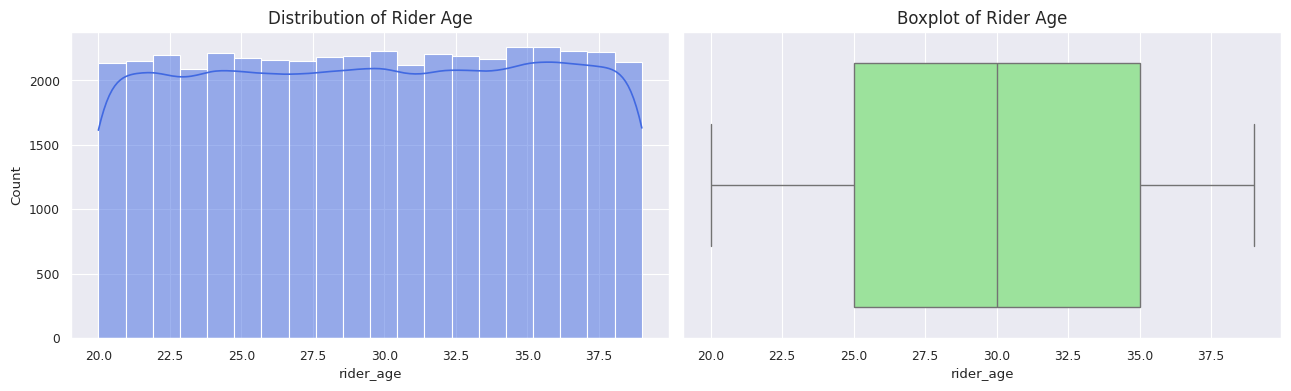

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "rider_ratings": float64
Total NaN values in "rider_ratings" : 1908
% of NaN values in "rider_ratings" : 4.19%


,rider_ratings
count,43594.00
mean,4.64
std,0.31
min,2.50
25%,4.50
50%,4.70
75%,4.90
max,5.00


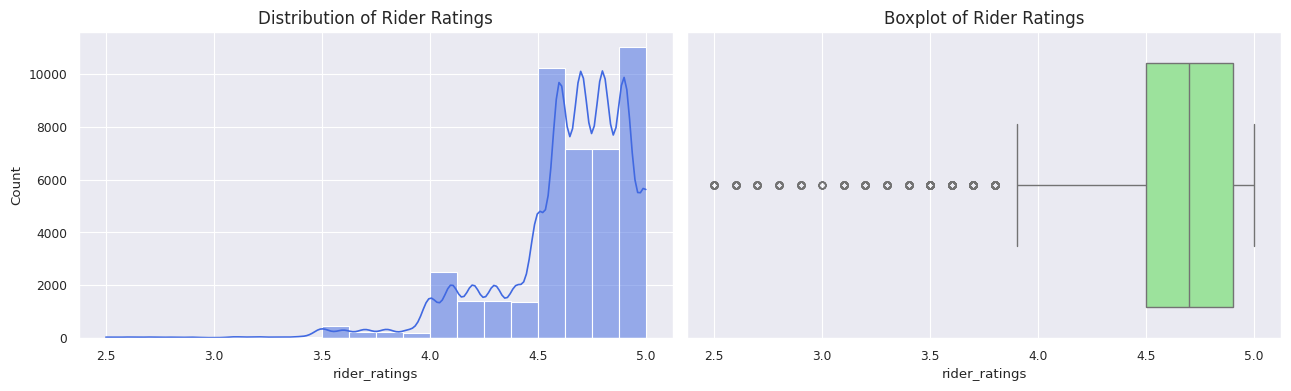

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "multiple_deliveries": float64
Total NaN values in "multiple_deliveries" : 993
% of NaN values in "multiple_deliveries" : 2.18%


,multiple_deliveries
count,44509.00
mean,0.74
std,0.57
min,0.00
25%,0.00
50%,1.00
75%,1.00
max,3.00


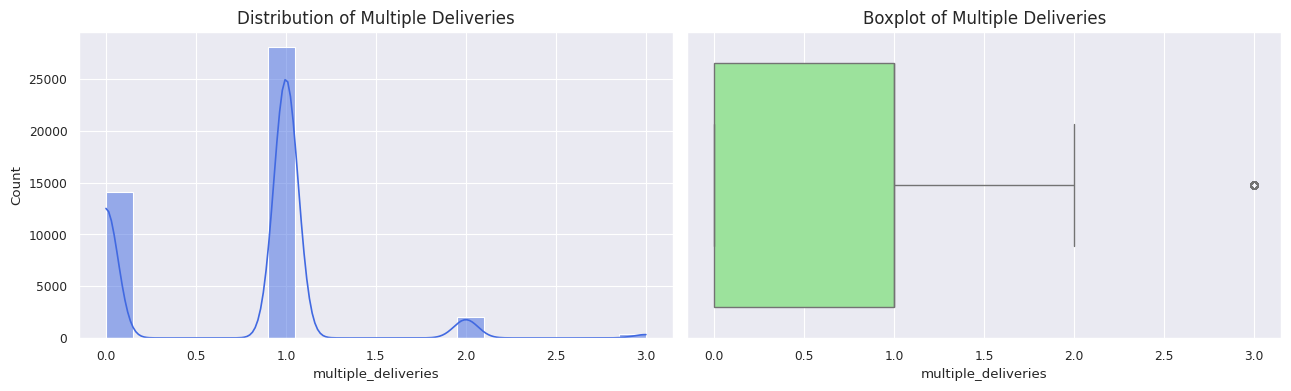

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "vehicle_condition": int64
Total NaN values in "vehicle_condition" : 0
% of NaN values in "vehicle_condition" : 0.0%


,vehicle_condition
count,45502.00
mean,1.02
std,0.84
min,0.00
25%,0.00
50%,1.00
75%,2.00
max,3.00


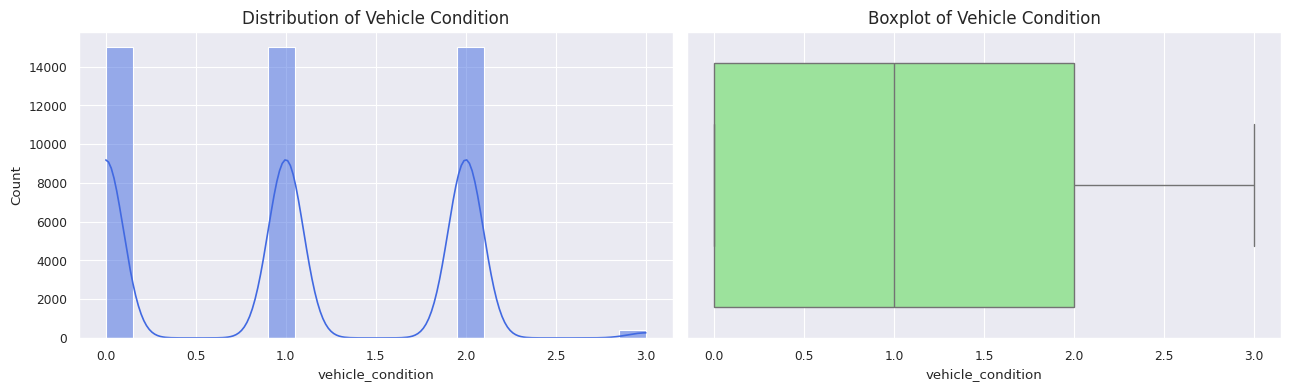

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "restaurant_latitude": float64
Total NaN values in "restaurant_latitude" : 3630
% of NaN values in "restaurant_latitude" : 7.98%


,restaurant_latitude
count,41872.00
mean,18.91
std,5.47
min,9.96
25%,12.99
50%,19.07
75%,22.75
max,30.91


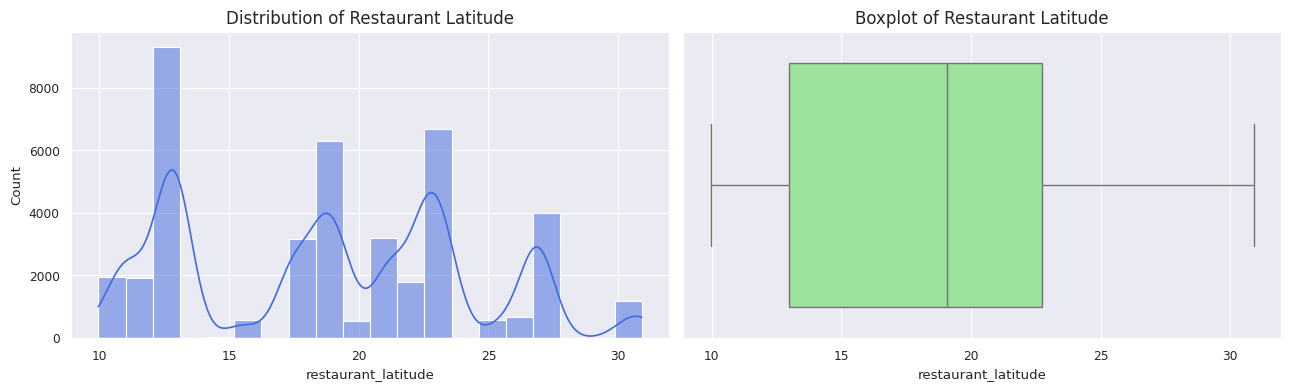

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "restaurant_longitude": float64
Total NaN values in "restaurant_longitude" : 3630
% of NaN values in "restaurant_longitude" : 7.98%


,restaurant_longitude
count,41872.00
mean,76.92
std,3.50
min,72.77
25%,73.90
50%,76.62
75%,78.37
max,88.43


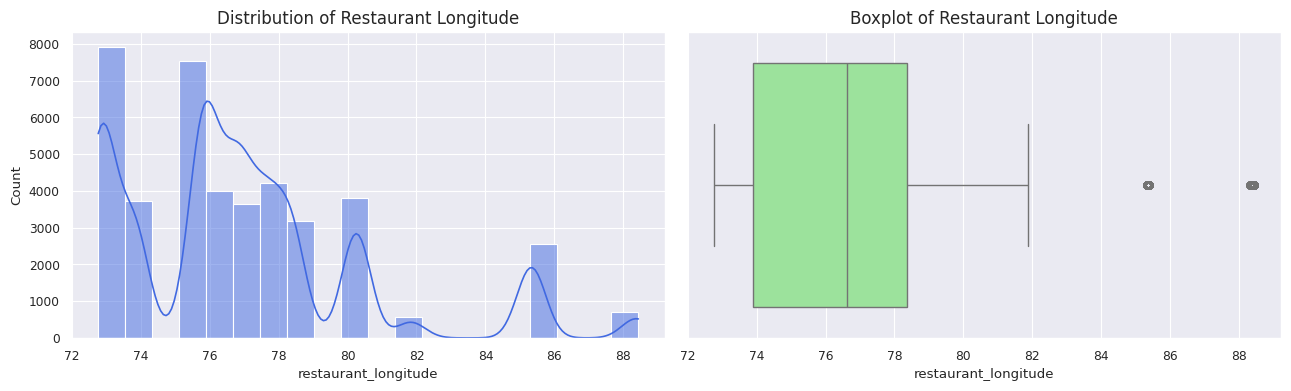

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "delivery_latitude": float64
Total NaN values in "delivery_latitude" : 3630
% of NaN values in "delivery_latitude" : 7.98%


,delivery_latitude
count,41872.00
mean,18.98
std,5.47
min,9.97
25%,13.07
50%,19.12
75%,22.82
max,31.05


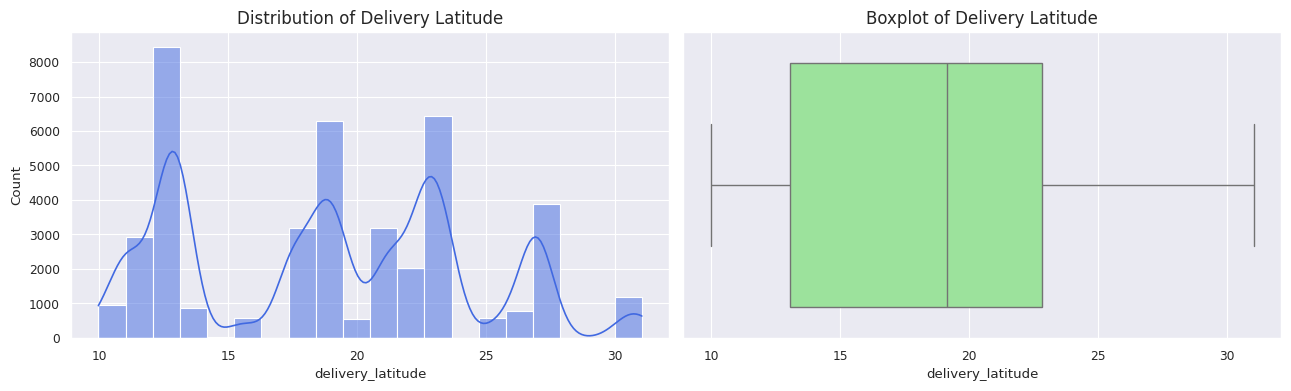

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "delivery_longitude": float64
Total NaN values in "delivery_longitude" : 3630
% of NaN values in "delivery_longitude" : 7.98%


,delivery_longitude
count,41872.00
mean,76.99
std,3.50
min,72.78
25%,73.94
50%,76.66
75%,78.41
max,88.56


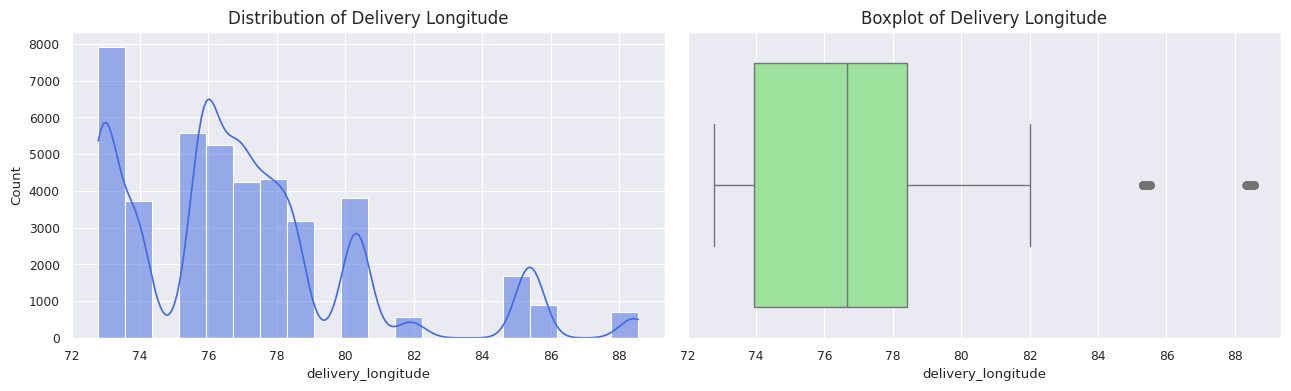

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "distance_km": float64
Total NaN values in "distance_km" : 3630
% of NaN values in "distance_km" : 7.98%


,distance_km
count,41872.00
mean,9.72
std,5.60
min,1.47
25%,4.66
50%,9.19
75%,13.68
max,20.97


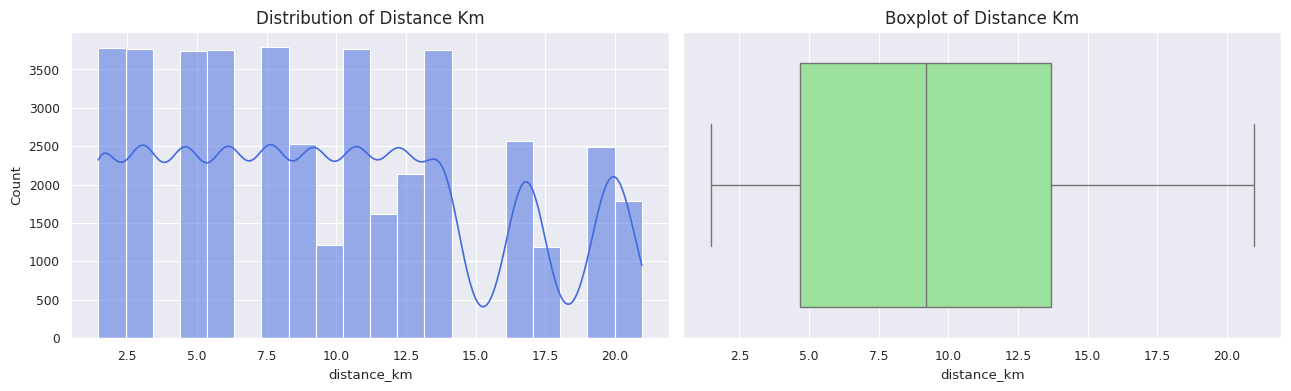

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "order_pickup_time_mins": float64
Total NaN values in "order_pickup_time_mins" : 1640
% of NaN values in "order_pickup_time_mins" : 3.6%


,order_pickup_time_mins
count,43862.00
mean,9.99
std,4.09
min,5.00
25%,5.00
50%,10.00
75%,15.00
max,15.00


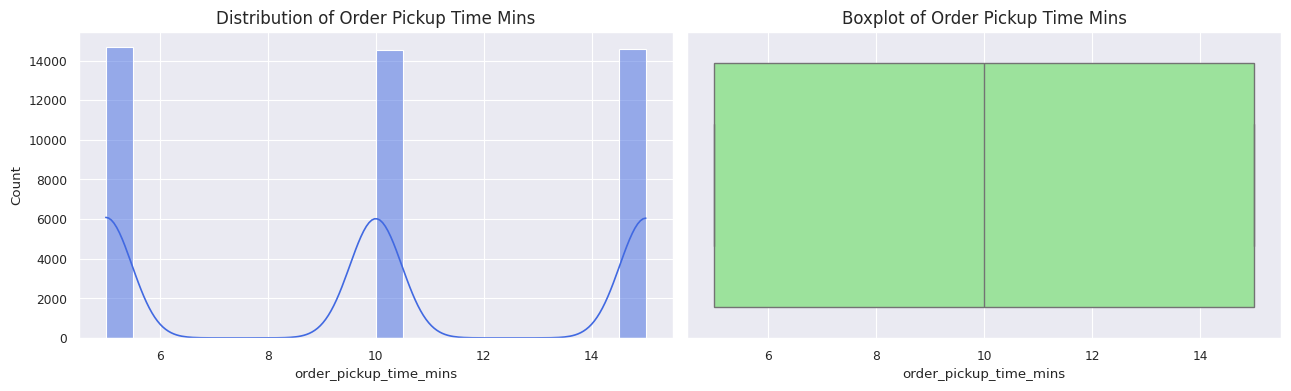

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "order_placed_hr": float64
Total NaN values in "order_placed_hr" : 57
% of NaN values in "order_placed_hr" : 0.13%


,order_placed_hr
count,45445.00
mean,17.43
std,4.81
min,0.00
25%,15.00
50%,19.00
75%,21.00
max,23.00


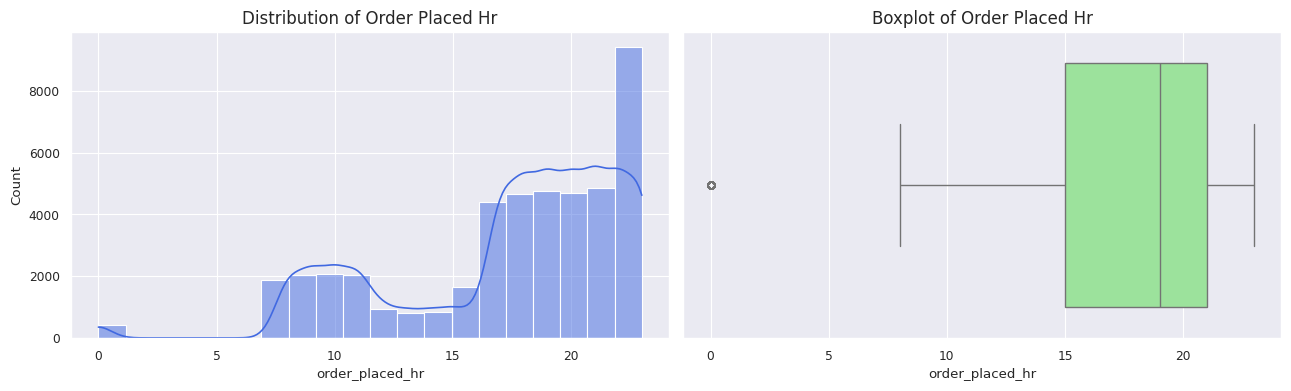

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "sin_hr": float64
Total NaN values in "sin_hr" : 57
% of NaN values in "sin_hr" : 0.13%


,sin_hr
count,45445.00
mean,-0.48
std,0.56
min,-1.00
25%,-0.97
50%,-0.71
75%,-0.26
max,0.87


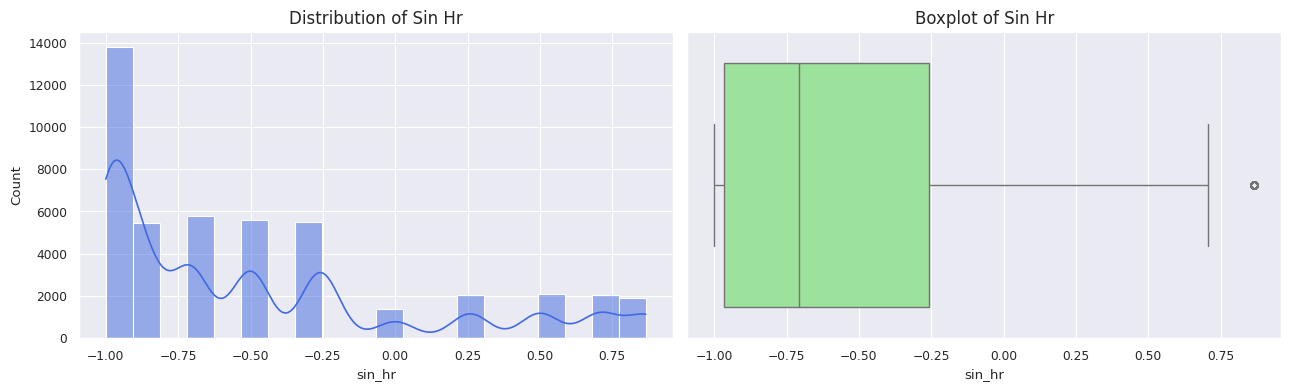

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "cos_hr": float64
Total NaN values in "cos_hr" : 57
% of NaN values in "cos_hr" : 0.13%


,cos_hr
count,45445.00
mean,0.12
std,0.66
min,-1.00
25%,-0.50
50%,0.26
75%,0.71
max,1.00


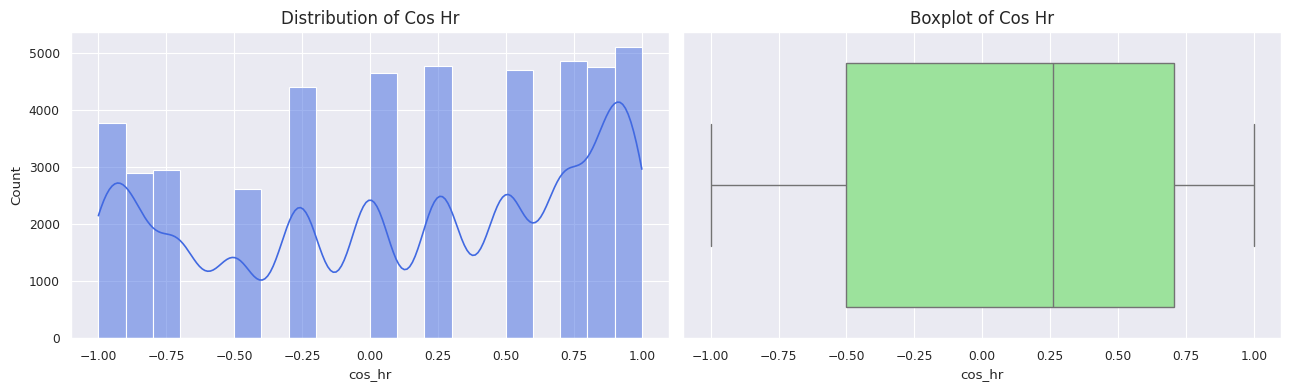

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "order_day": float64
Total NaN values in "order_day" : 57
% of NaN values in "order_day" : 0.13%


,order_day
count,45445.00
mean,13.81
std,8.71
min,1.00
25%,6.00
50%,13.00
75%,20.00
max,31.00


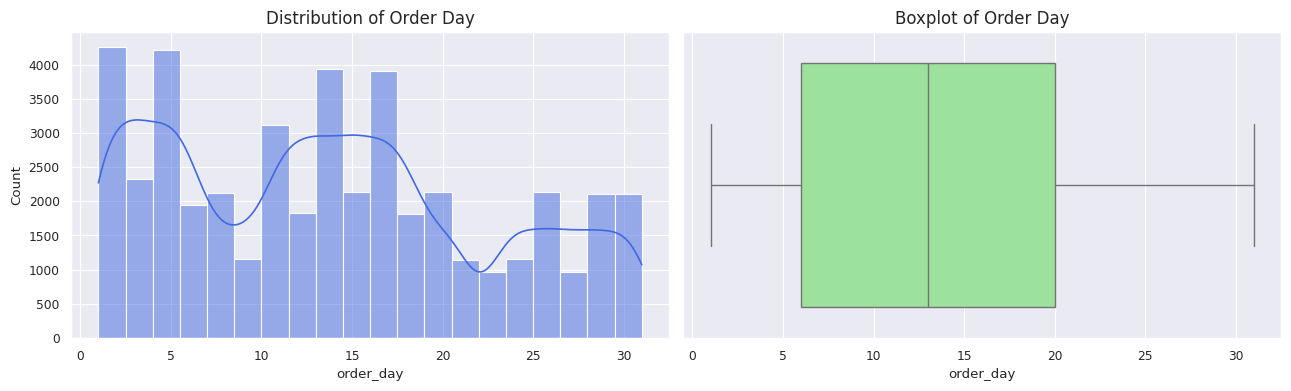

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "order_month": float64
Total NaN values in "order_month" : 1
% of NaN values in "order_month" : 0.0%


,order_month
count,45501.00
mean,2.98
std,0.55
min,2.00
25%,3.00
50%,3.00
75%,3.00
max,4.00


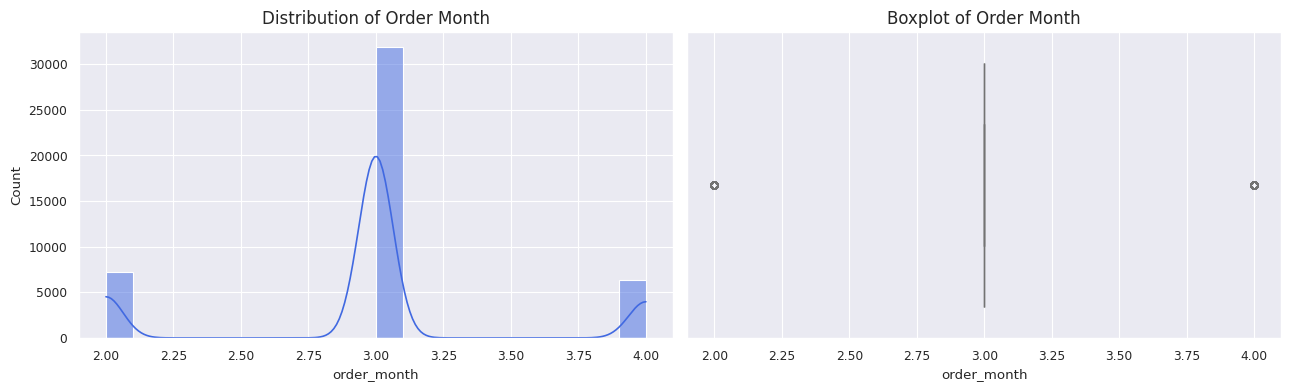

------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "time_taken": int64
Total NaN values in "time_taken" : 0
% of NaN values in "time_taken" : 0.0%


,time_taken
count,45502.00
mean,26.30
std,9.39
min,10.00
25%,19.00
50%,26.00
75%,32.00
max,54.00


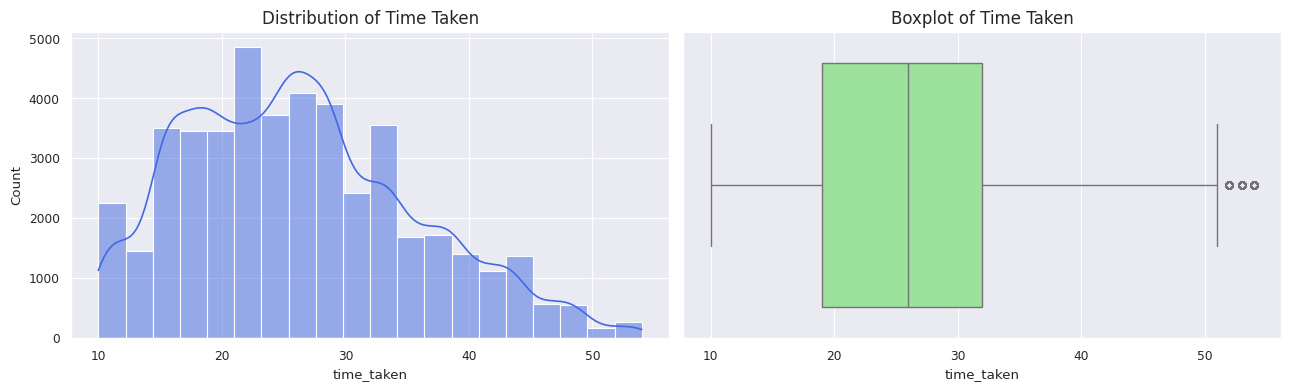

------------------------------------------------------------------------------------------------------------------------------------------------------



In [ ]:
for i in num_cols:
    get_numerical_info(df, i, n_bins = 20)
    print('-'*150,end = '\n\n')

In [ ]:
for i in cat_cols:
    get_categorical_info(df, i)
    print('-'*150,end = '\n\n')

Data-Type of "vehicle_type" : object
Unique values in "vehicle_type" : ['Motor-Cycle' 'Scooter' 'Electric-Scooter' 'Bicycle']
Total unique values in "vehicle_type" : 4
% of NaN values in "vehicle_type" : 0.0



,vehicle_type,count,proportion
0,Motor-Cycle,26427,58.07877
1,Scooter,15244,33.50182
2,Electric-Scooter,3778,8.30293
3,Bicycle,53,0.11648


------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "city_name" : object
Unique values in "city_name" : ['Indore' 'Bangalore' 'Coimbatore' 'Chennai' 'Hyderabad' 'Ranchi' 'Mysore'
 'Delhi' 'Kochi' 'Pune' 'Ludhiana' 'Kanpur' 'Mumbai' 'Kolkata' 'Jaipur'
 'Surat' 'Goa' 'Aurangabad' 'Agra' 'Vadodara' 'Prayagraj' 'Bhopal']
Total unique values in "city_name" : 22
% of NaN values in "city_name" : 0.0



,city_name,count,proportion
0,Jaipur,3439,7.55791
1,Ranchi,3222,7.08101
2,Bangalore,3184,6.99749
3,Surat,3182,6.99310
4,Hyderabad,3177,6.98211
5,Mumbai,3168,6.96233
6,Mysore,3164,6.95354
7,Coimbatore,3162,6.94915
8,Vadodara,3159,6.94255
9,Indore,3154,6.93156


------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "order_type" : object
Unique values in "order_type" : ['Snack' 'Drinks' 'Buffet' 'Meal']
Total unique values in "order_type" : 4
% of NaN values in "order_type" : 0.0



,order_type,count,proportion
0,Snack,11512,25.29999
1,Meal,11435,25.13076
2,Drinks,11294,24.82089
3,Buffet,11261,24.74836


... (5 outputs left out)

,weather,count,proportion
0,Fog,7654,17.01759
1,Stormy,7586,16.86640
2,Cloudy,7536,16.75523
3,Sandstorms,7495,16.66407
4,Windy,7422,16.50177
5,Sunny,7284,16.19494


------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "traffic" : object
Unique values in "traffic" : ['High' 'Jam' 'Low' 'Medium' nan]
Total unique values in "traffic" : 4
% of NaN values in "traffic" : 1.12



,traffic,count,proportion
0,Low,15477,34.39945
1,Jam,14143,31.43448
2,Medium,10947,24.33099
3,High,4425,9.83508


------------------------------------------------------------------------------------------------------------------------------------------------------



In [ ]:
for col in cat_cols:
    print(f'Unique Values in {col} are: {df[col].unique()}')

Unique Values in vehicle_type are: ['Motor-Cycle' 'Scooter' 'Electric-Scooter' 'Bicycle']
Unique Values in city_name are: ['Indore' 'Bangalore' 'Coimbatore' 'Chennai' 'Hyderabad' 'Ranchi' 'Mysore'
 'Delhi' 'Kochi' 'Pune' 'Ludhiana' 'Kanpur' 'Mumbai' 'Kolkata' 'Jaipur'
 'Surat' 'Goa' 'Aurangabad' 'Agra' 'Vadodara' 'Prayagraj' 'Bhopal']
Unique Values in order_type are: ['Snack' 'Drinks' 'Buffet' 'Meal']
Unique Values in order_time_of_day are: ['Morning' 'Evening' 'Afternoon' 'Night' 'Late Night']
Unique Values in order_day_of_week are: ['Saturday' 'Friday' 'Tuesday' 'Monday' 'Sunday' 'Wednesday' 'Thursday'
 nan]
Unique Values in weather are: ['Sunny' 'Stormy' 'Sandstorms' 'Cloudy' 'Fog' 'Windy' nan]
Unique Values in traffic are: ['High' 'Jam' 'Low' 'Medium' nan]


In [ ]:
for i in boolean_cols:
    get_categorical_info(df, i)
    print('-'*150,end = '\n\n')

Data-Type of "is_lunch_rush" : boolean
Unique values in "is_lunch_rush" : <BooleanArray>
[False, True]
Length: 2, dtype: boolean
Total unique values in "is_lunch_rush" : 2
% of NaN values in "is_lunch_rush" : 0.0



,is_lunch_rush,count,proportion
0,False,42947,94.38486
1,True,2555,5.61514


------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "is_dinner_rush" : boolean
Unique values in "is_dinner_rush" : <BooleanArray>
[False, True]
Length: 2, dtype: boolean
Total unique values in "is_dinner_rush" : 2
% of NaN values in "is_dinner_rush" : 0.0



,is_dinner_rush,count,proportion
0,False,31197,68.56182
1,True,14305,31.43818


------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "is_friday_night" : boolean
Unique values in "is_friday_night" : <BooleanArray>
[False, True, <NA>]
Length: 3, dtype: boolean
Total unique values in "is_friday_night" : 2
% of NaN values in "is_friday_night" : 0.13



,is_friday_night,count,proportion
0,False,40855,89.89988
1,True,4590,10.10012


... (5 outputs left out)

,is_month_end,count,proportion
0,False,44535,97.87697
1,True,966,2.12303


------------------------------------------------------------------------------------------------------------------------------------------------------

Data-Type of "is_festival" : boolean
Unique values in "is_festival" : <BooleanArray>
[False, True, <NA>]
Length: 3, dtype: boolean
Total unique values in "is_festival" : 2
% of NaN values in "is_festival" : 0.5



,is_festival,count,proportion
0,False,44380,98.02536
1,True,894,1.97464


------------------------------------------------------------------------------------------------------------------------------------------------------



In [ ]:
mask = df.isnull().sum()
nullity_cols = mask[mask>0].index.to_list()
nullity_df = df.loc[:,nullity_cols]
nullity_df.head(10)

,rider_age,rider_ratings,multiple_deliveries,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,distance_km,order_placed_datetime,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic
0,37.0,4.9,0.0,22.745049,75.892471,22.765049,75.912471,3.025149,2022-03-19 11:30:00,15.0,11.0,0.2588,-0.9659,19.0,Saturday,False,True,3.0,False,False,False,Sunny,High
1,34.0,4.5,1.0,12.913041,77.683237,13.043041,77.813237,20.183530,2022-03-25 19:45:00,5.0,19.0,-0.9659,0.2588,25.0,Friday,True,False,3.0,False,False,False,Stormy,Jam
2,23.0,4.4,1.0,12.914264,77.678400,12.924264,77.688400,1.552758,2022-03-19 08:30:00,15.0,8.0,0.8660,-0.5000,19.0,Saturday,False,True,3.0,False,False,False,Sandstorms,Low
3,38.0,4.7,1.0,11.003669,76.976494,11.053669,77.026494,7.790401,2022-04-05 18:00:00,10.0,18.0,-1.0000,-0.0000,5.0,Tuesday,False,False,4.0,False,False,False,Sunny,Medium
4,32.0,4.6,1.0,12.972793,80.249982,13.012793,80.289982,6.210138,2022-03-26 13:30:00,15.0,13.0,-0.2588,-0.9659,26.0,Saturday,False,True,3.0,False,False,False,Cloudy,High
5,22.0,4.8,1.0,17.431668,78.408321,17.461668,78.438321,4.610365,2022-03-11 21:20:00,10.0,21.0,-0.7071,0.7071,11.0,Friday,True,False,3.0,False,False,False,Cloudy,Jam
6,33.0,4.7,1.0,23.369746,85.339820,23.479746,85.449820,16.600361,2022-03-04 19:15:00,15.0,19.0,-0.9659,0.2588,4.0,Friday,True,False,3.0,False,False,False,Fog,Jam
7,35.0,4.6,1.0,12.352058,76.606650,12.482058,76.736650,20.205253,2022-03-14 17:25:00,5.0,17.0,-0.9659,-0.2588,14.0,Monday,False,False,3.0,False,False,False,Cloudy,Medium
8,22.0,4.8,1.0,17.433809,78.386744,17.563809,78.516744,19.975520,2022-03-20 20:55:00,10.0,20.0,-0.8660,0.5000,20.0,Sunday,False,True,3.0,False,False,False,Stormy,Jam
9,36.0,4.2,3.0,30.327968,78.046106,30.397968,78.116106,10.280582,2022-02-12 21:55:00,15.0,21.0,-0.7071,0.7071,12.0,Saturday,False,True,2.0,False,False,False,Fog,Jam


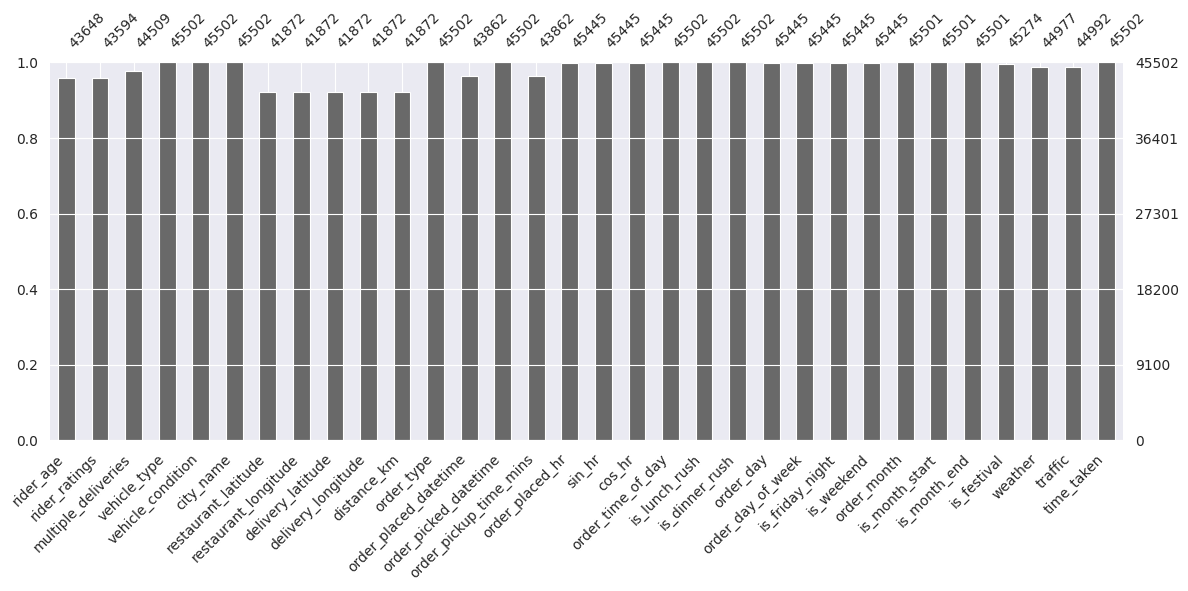

In [ ]:
fig,ax = plt.subplots(nrows = 1, ncols = 1, figsize = (12,6))
msno.bar(df, ax = ax, fontsize = 10)
plt.tight_layout()
plt.show()

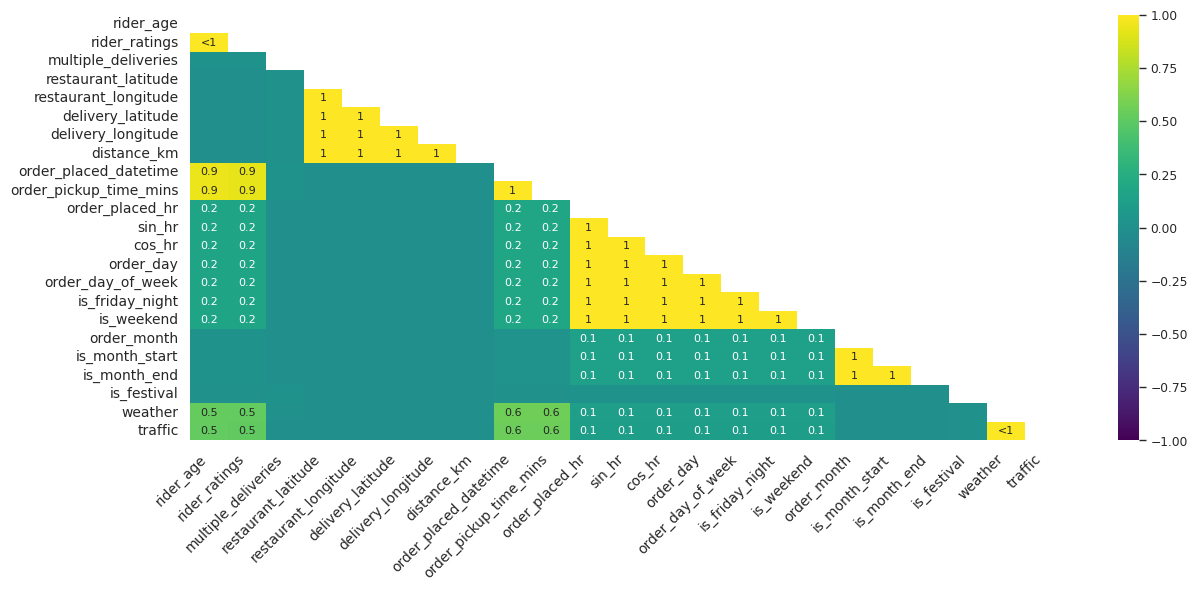

In [ ]:
fig,ax = plt.subplots(nrows = 1, ncols = 1, figsize = (13,6))
msno.heatmap(df, ax = ax, fontsize = 10, cmap = 'viridis')
plt.tight_layout()
plt.show()

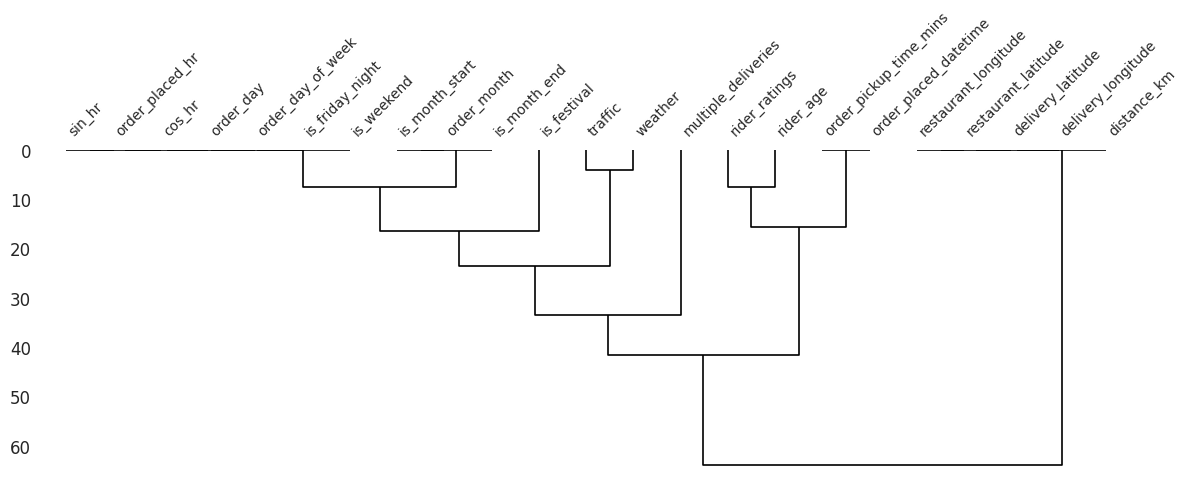

In [ ]:
fig,ax = plt.subplots(nrows = 1, ncols = 1, figsize = (12,5))
msno.dendrogram(nullity_df, ax = ax, fontsize = 10)
plt.tight_layout()
plt.show()

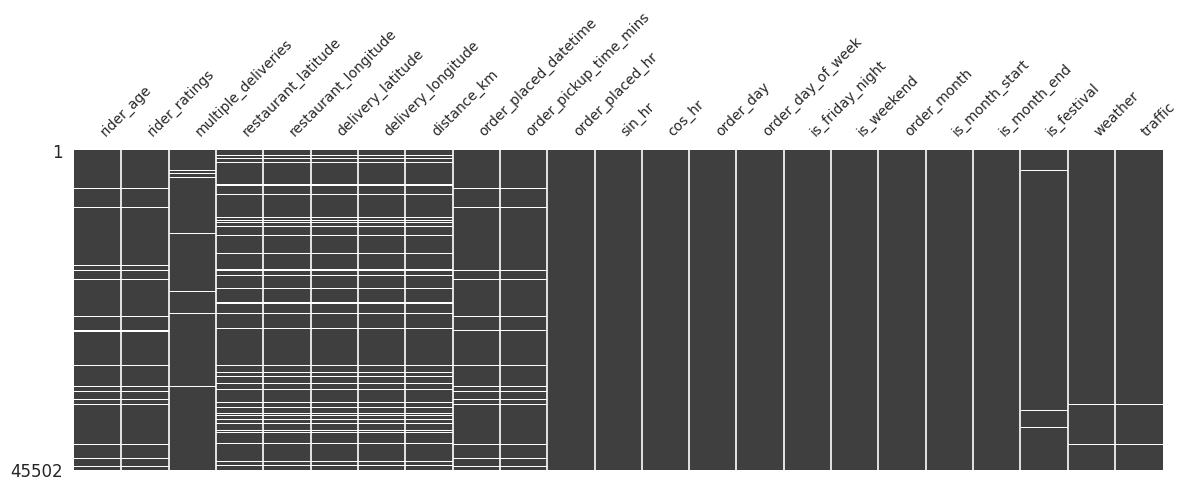

In [ ]:
fig,ax = plt.subplots(nrows = 1, ncols = 1, figsize = (12,5))
msno.matrix(nullity_df, ax = ax, fontsize = 10)
plt.tight_layout()
plt.show()

In [ ]:
# Orignal Data

# There are 45593 rows and 20 columns in the dataset
# There are 9131 missing cells out of 911860 total cells, which signifies that 1.0% of data is missing
# There are 4225 rows containing at least one missing value, which accounts for 9.27% of total rows
# There are 0 rows containing all missing values, which accounts for 0.0% of total rows
# There are 0 duplicated rows

In [ ]:
# Cleaned data

row, cols = df.shape
missing_cells = df.isnull().sum().sum()
missing_atleast_rows = df.isnull().any(axis = 1).sum()
missing_all_rows = df.isnull().all(axis = 1).sum()
rows_duplicated = df.duplicated().sum()

print(f'There are {row} rows and {cols} columns in the dataset')
print(f'There are {missing_cells} missing cells out of {df.size} total cells, which signifies that {round((missing_cells/df.size)*100,2)}% of data is missing')
print(f'There are {missing_atleast_rows} rows containing at least one missing value, which accounts for {round((missing_atleast_rows/row)*100,2)}% of total rows')
print(f'There are {missing_all_rows} rows containing all missing values, which accounts for {round((missing_all_rows/row)*100,2)}% of total rows')
print(f'There are {rows_duplicated} duplicated rows')

There are 45502 rows and 32 columns in the dataset
There are 27850 missing cells out of 1456064 total cells, which signifies that 1.91% of data is missing
There are 6434 rows containing at least one missing value, which accounts for 14.14% of total rows
There are 0 rows containing all missing values, which accounts for 0.0% of total rows
There are 0 duplicated rows


In [ ]:
load_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Type_of_order                45593 non-null  object 
 9   Order_Date                   45593 non-null  object 
 10  Time_ordered                 45593 non-null  object 
 11  Time_Order_picked            45593 non-null  object 
 12  Weatherconditions            45593 non-null  object 
 13  Road_traffic_den

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45502 entries, 0 to 45501
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   rider_age               43648 non-null  float64       
 1   rider_ratings           43594 non-null  float64       
 2   multiple_deliveries     44509 non-null  float64       
 3   vehicle_type            45502 non-null  object        
 4   vehicle_condition       45502 non-null  int64         
 5   city_name               45502 non-null  object        
 6   restaurant_latitude     41872 non-null  float64       
 7   restaurant_longitude    41872 non-null  float64       
 8   delivery_latitude       41872 non-null  float64       
 9   delivery_longitude      41872 non-null  float64       
 10  distance_km             41872 non-null  float64       
 11  order_type              45502 non-null  object        
 12  order_placed_datetime   43862 non-null  dateti

In [ ]:
df.isnull().sum()

,0
rider_age,1854
rider_ratings,1908
multiple_deliveries,993
vehicle_type,0
vehicle_condition,0
city_name,0
restaurant_latitude,3630
restaurant_longitude,3630
delivery_latitude,3630
delivery_longitude,3630


In [ ]:
df[df['order_month'].isnull()]

,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,city_name,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,distance_km,order_type,order_placed_datetime,order_picked_datetime,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic,time_taken
30175,NaN,NaN,0.0,Motor-Cycle,0,Mumbai,18.994237,72.825553,19.044237,72.875553,7.651064,Buffet,NaT,2022-03-01 00:05:00,NaN,NaN,NaN,NaN,Late Night,False,False,NaN,NaN,<NA>,<NA>,NaN,<NA>,<NA>,False,Fog,Low,25


In [ ]:
df.drop(index = df[df['order_month'].isnull()].index, inplace = True)

In [ ]:
df.head()

,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,city_name,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,distance_km,order_type,order_placed_datetime,order_picked_datetime,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic,time_taken
0,37.0,4.9,0.0,Motor-Cycle,2,Indore,22.745049,75.892471,22.765049,75.912471,3.025149,Snack,2022-03-19 11:30:00,2022-03-19 11:45:00,15.0,11.0,0.2588,-0.9659,Morning,False,False,19.0,Saturday,False,True,3.0,False,False,False,Sunny,High,24
1,34.0,4.5,1.0,Scooter,2,Bangalore,12.913041,77.683237,13.043041,77.813237,20.183530,Snack,2022-03-25 19:45:00,2022-03-25 19:50:00,5.0,19.0,-0.9659,0.2588,Evening,False,False,25.0,Friday,True,False,3.0,False,False,False,Stormy,Jam,33
2,23.0,4.4,1.0,Motor-Cycle,0,Bangalore,12.914264,77.678400,12.924264,77.688400,1.552758,Drinks,2022-03-19 08:30:00,2022-03-19 08:45:00,15.0,8.0,0.8660,-0.5000,Morning,False,False,19.0,Saturday,False,True,3.0,False,False,False,Sandstorms,Low,26
3,38.0,4.7,1.0,Motor-Cycle,0,Coimbatore,11.003669,76.976494,11.053669,77.026494,7.790401,Buffet,2022-04-05 18:00:00,2022-04-05 18:10:00,10.0,18.0,-1.0000,-0.0000,Evening,False,False,5.0,Tuesday,False,False,4.0,False,False,False,Sunny,Medium,21
4,32.0,4.6,1.0,Scooter,1,Chennai,12.972793,80.249982,13.012793,80.289982,6.210138,Snack,2022-03-26 13:30:00,2022-03-26 13:45:00,15.0,13.0,-0.2588,-0.9659,Afternoon,True,False,26.0,Saturday,False,True,3.0,False,False,False,Cloudy,High,30


In [ ]:
df.isnull().sum()

,0
rider_age,1853
rider_ratings,1907
multiple_deliveries,993
vehicle_type,0
vehicle_condition,0
city_name,0
restaurant_latitude,3630
restaurant_longitude,3630
delivery_latitude,3630
delivery_longitude,3630


In [ ]:
df['vehicle_condition'] = df['vehicle_condition'].astype('object')

In [ ]:
get_missing_info(df)

,feature,data_type,missing_count,missing_%
0,rider_age,float64,1853,4.07
1,rider_ratings,float64,1907,4.19
2,multiple_deliveries,float64,993,2.18
3,vehicle_type,object,0,0.00
4,vehicle_condition,object,0,0.00
5,city_name,object,0,0.00
6,restaurant_latitude,float64,3630,7.98
7,restaurant_longitude,float64,3630,7.98
8,delivery_latitude,float64,3630,7.98
9,delivery_longitude,float64,3630,7.98


# Divide data into Train & Test Set

In [ ]:
all_indexes = set(df.index)
index_of_test_data = set(df.sample(round((0.2 * df.shape[0]))).index) # sampling 20% of rows without replacement
index_of_train_data = all_indexes - index_of_test_data # Set A - Set B

In [ ]:
np.intersect1d(index_of_train_data, index_of_test_data) # no same observations between train & test set

array([], dtype=object)

In [ ]:
train_data = df.loc[list(index_of_train_data)].reset_index(drop = True)
test_data = df.loc[list(index_of_test_data)].reset_index(drop = True)

In [ ]:
print(train_data.shape[0])
print(test_data.shape[0])

36401
9100


In [ ]:
print(train_data.shape[0] + test_data.shape[0])

45501


In [ ]:
df.shape[0]

45501

In [ ]:
mask = df.isnull().sum()
mask[mask > 0]
a = np.array(mask.index)

mask = train_data.isnull().sum()
mask[mask > 0]
b = np.array(mask.index)

mask = test_data.isnull().sum()
mask[mask > 0]
c = np.array(mask.index)

In [ ]:
# To check if the cleaned data, train data, test data have same nullity features

print(np.array_equal(a,b))
print(np.array_equal(b,c))
print(np.array_equal(c,a))

True
True
True


# Save Cleaned Data

In [ ]:
df.to_csv('3. swiggy_data_cleaned.csv', index = False)
train_data.to_csv('4. swiggy_train_data.csv', index = False)
test_data.to_csv('5. swiggy_test_data.csv', index = False)

-------------------------------------------------------- Data Cleaning Completed --------------------------------------------------